In [ ]:
#

In [1]:
'''import shutil

# Apaga a pasta inteira (mesmo se tiver arquivos dentro)
shutil.rmtree('/content/Classification')'''


"import shutil\n\n# Apaga a pasta inteira (mesmo se tiver arquivos dentro)\nshutil.rmtree('/content/Classification')"

In [ ]:
import shutil

# Compacta a pasta em um arquivo zip
shutil.make_archive('/content/Classification_zip', 'zip', '/content/Classification')

# Baixa o arquivo zip
from google.colab import files
files.download('/content/Classification_zip.zip')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
import random

import numpy as np
import json
import seaborn as sns
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.tree import DecisionTreeClassifier
from sklearn import svm
from sklearn.linear_model import SGDClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import cross_val_score
import os
import time
from sklearn.metrics import confusion_matrix, cohen_kappa_score
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, cohen_kappa_score
from sklearn.metrics import ConfusionMatrixDisplay

class Results:
    accuracy = pd.DataFrame()
    precision = pd.DataFrame()
    recall = pd.DataFrame()
    f1 = pd.DataFrame()
    kappa = pd.DataFrame()
    train_accuracy = pd.DataFrame()
    train_precision = pd.DataFrame()
    train_recall = pd.DataFrame()
    train_f1 = pd.DataFrame()
    train_kappa = pd.DataFrame()
    cv_mean = pd.DataFrame()
    cv_stddev = pd.DataFrame()
    train_error_rate = pd.DataFrame()
    gap = pd.DataFrame()
    error_rate = pd.DataFrame()
    train_time = pd.DataFrame()
    infer_time = pd.DataFrame()

    accuracy["Setup"] = ""
    precision["Setup"] = ""
    recall["Setup"] = ""
    f1["Setup"] = ""
    cv_mean["Setup"] = ""
    cv_stddev["Setup"] = ""
    kappa["Setup"] = ""
    error_rate["Setup"] = ""
    train_time["Setup"] = ""
    infer_time["Setup"] = ""
    train_accuracy["Setup"] = ""
    train_precision["Setup"] = ""
    train_recall["Setup"] = ""
    train_f1["Setup"] = ""
    train_kappa["Setup"] = ""
    train_error_rate["Setup"] = ""
    gap["Setup"] = ""

    accuracy.set_index('Setup')
    precision.set_index('Setup')
    recall.set_index('Setup')
    f1.set_index('Setup')
    cv_mean.set_index('Setup')
    cv_stddev.set_index('Setup')
    kappa.set_index('Setup')
    error_rate.set_index('Setup')
    train_time.set_index('Setup')
    infer_time.set_index('Setup')
    train_accuracy.set_index('Setup')
    train_precision.set_index('Setup')
    train_recall.set_index('Setup')
    train_f1.set_index('Setup')
    train_kappa.set_index('Setup')
    train_error_rate.set_index('Setup')
    gap.set_index('Setup')

    def addModel(self, name):
        self.accuracy[name] = ""
        self.precision[name] = ""
        self.recall[name] = ""
        self.f1[name] = ""
        self.cv_mean[name] = ""
        self.cv_stddev[name] = ""
        self.kappa[name] = ""
        self.error_rate[name] = ""
        self.train_time[name] = ""
        self.infer_time[name] = ""
        self.train_accuracy[name] = ""
        self.train_precision[name] = ""
        self.train_recall[name] = ""
        self.train_f1[name] = ""
        self.train_kappa[name] = ""
        self.train_error_rate[name] = ""
        self.gap[name] = ""

    def addResults(self, _acc, _precision, _recall, _f1, _cv_mean, _cv_stddev, _kappa, _error_rate, _train_time, _infer_time, _train_acc, _train_precision, _train_recall, _train_f1, _train_kappa, _train_error_rate, _gap):
        self.accuracy.loc[len(self.accuracy)] = _acc
        self.precision.loc[len(self.precision)] = _precision
        self.recall.loc[len(self.recall)] = _recall
        self.f1.loc[len(self.f1)] = _f1
        self.cv_mean.loc[len(self.cv_mean)] = _cv_mean
        self.cv_stddev.loc[len(self.cv_stddev)] = _cv_stddev
        self.kappa.loc[len(self.kappa)] = _kappa
        self.error_rate.loc[len(self.error_rate)] = _error_rate
        self.train_time.loc[len(self.train_time)] = _train_time
        self.infer_time.loc[len(self.infer_time)] = _infer_time
        self.train_accuracy.loc[len(self.accuracy)] = _train_acc
        self.train_precision.loc[len(self.precision)] = _train_precision
        self.train_recall.loc[len(self.recall)] = _train_recall
        self.train_f1.loc[len(self.f1)] = _train_f1
        self.train_kappa.loc[len(self.kappa)] = _train_kappa
        self.train_error_rate.loc[len(self.error_rate)] = _train_error_rate
        self.gap.loc[len(self.gap)] = _gap

    def printCSV(self, output_folder="Classification"):
      # Cria a pasta com o subdiretório
        full_path = os.path.join("Classification", output_folder)
        os.makedirs(full_path, exist_ok=True)
        self.accuracy.to_csv(f'{full_path}/classification_all_accuracy.csv', index=False, float_format='%.3f')
        self.precision.to_csv(f'{full_path}/classification_all_precision.csv', index=False, float_format='%.3f')
        self.recall.to_csv(f'{full_path}/classification_all_recall.csv', index=False, float_format='%.3f')
        self.f1.to_csv(f'{full_path}/classification_all_f1.csv', index=False, float_format='%.3f')
        self.cv_mean.to_csv(f'{full_path}/classification_all_cv_mean.csv', index=False, float_format='%.3f')
        self.cv_stddev.to_csv(f'{full_path}/classification_all_cv_stddev.csv', index=False, float_format='%.3f')
        self.kappa.to_csv(f'{full_path}/classification_all_kappa.csv', index=False, float_format='%.3f')
        self.error_rate.to_csv(f'{full_path}/classification_all_error_rate.csv', index=False, float_format='%.3f')
        self.train_time.to_csv(f'{full_path}/classification_all_train_time.csv', index=False, float_format='%.3f')
        self.infer_time.to_csv(f'{full_path}/classification_all_infer_time.csv', index=False, float_format='%.3f')

def initialize_data_frame():
    pd.set_option('display.max_columns', None)
    pd.set_option('display.width', 2000)
    sns.set(rc={'figure.figsize':(19.20, 10.80)})


def get_dungeon_data_frame():
    with open('backup.json') as data_file:
        json_data = json.load(data_file)
    return pd.DataFrame(json_data['__collections__']['dungeons']).T


def get_user_data_frame():
    with open('backup.json') as data_file:
        json_data = json.load(data_file)
    return pd.DataFrame(json_data['__collections__']['users']).T


def drop_invalid_rows(_data_frame):
    _data_frame.drop(_data_frame[_data_frame['UniqueRoomsEntered'] == 0].index, inplace=True)
    return _data_frame


def drop_unused_columns(_data_frame):
    _data_frame.drop('__collections__', inplace=True, axis=1)
    _data_frame = _data_frame.drop(list(_data_frame.filter(regex='^Total.*Quests')), axis=1)
    _data_frame.drop('CompletedQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedKillQuests', inplace=True, axis=1)
    _data_frame.rename(columns={'CompletedDamageQuests': 'CompletedKillQuests'}, inplace=True)
    _data_frame.drop('TreasuresCollected', inplace=True, axis=1)
    _data_frame.drop('TotalNpcs', inplace=True, axis=1)
    _data_frame.drop('WeaponName', inplace=True, axis=1)
    _data_frame.drop('HeatMap', inplace=True, axis=1)
    return _data_frame


def get_percentages(_data_frame):
    _data_frame['LockUsage'] = _data_frame['LocksOpened'].div(_data_frame['TotalLocks'].values)*100
    _data_frame['KeyCollection'] = _data_frame['KeysCollected'].div(_data_frame['TotalKeys'].values)*100
    _data_frame['MapCompletion'] = _data_frame['UniqueRoomsEntered'].div(_data_frame['TotalRooms'].values)*100
    _data_frame['RoomRevisitRate'] = _data_frame['RoomsEntered'].div(_data_frame['TotalRooms'].values)*100
    _data_frame['EnemyKillRate'] = _data_frame['EnemiesKilled'].div(_data_frame['TotalEnemies'].values)*100
    _data_frame['TotalAttempts'] = _data_frame['TotalWins'] + _data_frame['TotalDeaths'].values
    _data_frame['TotalAttempts'] = _data_frame['TotalAttempts'].astype(float)
    _data_frame['TotalWins'] = _data_frame['TotalWins'].astype(float)
    _data_frame['Success Rate'] = _data_frame['TotalAttempts'].div(_data_frame['TotalWins'].values)*100
    _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
    return _data_frame


def drop_processed_columns(_data_frame):
    _data_frame.drop('LocksOpened', inplace=True, axis=1)
    _data_frame.drop('TotalLocks', inplace=True, axis=1)
    _data_frame.drop('KeysCollected', inplace=True, axis=1)
    _data_frame.drop('TotalKeys', inplace=True, axis=1)
    _data_frame.drop('EnemiesKilled', inplace=True, axis=1)
    _data_frame.drop('TotalEnemies', inplace=True, axis=1)
    _data_frame.drop('TotalAttempts', inplace=True, axis=1)
    _data_frame.drop('TotalWins', inplace=True, axis=1)
    _data_frame.drop('TotalDeaths', inplace=True, axis=1)
    _data_frame.drop('NpcsInteracted', inplace=True, axis=1)
    _data_frame.drop('RoomsEntered', inplace=True, axis=1)
    _data_frame.drop('TotalRooms', inplace=True, axis=1)
    _data_frame.drop('UniqueRoomsEntered', inplace=True, axis=1)
    _data_frame.drop('TotalTreasure', inplace=True, axis=1)
    return _data_frame


def split_preform_answers(_data_frame):
    _data_frame[['A', 'C', 'I', 'M']] = _data_frame['PreFormAnswers'].str.split(',', expand=True)
    _data_frame['A'] = _data_frame['A'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    _data_frame['C'] = _data_frame['C'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    _data_frame['I'] = _data_frame['I'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    _data_frame['M'] = _data_frame['M'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    return _data_frame


def drop_quest_data(_data_frame):
    _data_frame = _data_frame.drop(list(_data_frame.filter(regex='Quest')), axis=1)
    return _data_frame


def drop_player_data(_data_frame):
    _data_frame.drop('A', inplace=True, axis=1)
    _data_frame.drop('C', inplace=True, axis=1)
    _data_frame.drop('I', inplace=True, axis=1)
    _data_frame.drop('M', inplace=True, axis=1)
    _data_frame.drop('PostFormAnswers', inplace=True, axis=1)
    _data_frame.drop('PlayerId', inplace=True, axis=1)
    return _data_frame


def drop_gameplay_data(_data_frame):
    _data_frame.drop('TimeToFinish', inplace=True, axis=1)
    _data_frame.drop('LockUsage', inplace=True, axis=1)
    _data_frame.drop('KeyCollection', inplace=True, axis=1)
    _data_frame.drop('MapCompletion', inplace=True, axis=1)
    _data_frame.drop('EnemyKillRate', inplace=True, axis=1)
    return _data_frame


def drop_terminal_quest_data(_data_frame):
    _data_frame.drop('CompletedReportQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedListenQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedExploreQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedExchangeQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedKillQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedGiveQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedGoToQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedGatherQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedReadQuests', inplace=True, axis=1)
    return _data_frame


def augment_dataframe_with_scaling(df, y, n, scale_factor):
    """
    Augments the DataFrame by adding `n` new rows, scaling numeric columns by a given factor.
    The new rows inherit the same 'y' values as their corresponding sampled rows.

    Parameters:
        df (pd.DataFrame): Original DataFrame with numeric columns and a 'y' column.
        n (int): Number of new rows to generate.
        scale_factor (float): The factor by which numeric columns will be scaled.

    Returns:
        pd.DataFrame: DataFrame with the original and new rows.
    """
    # Identify numeric columns, excluding 'y'
    numeric_columns = df.select_dtypes(include=['number']).columns.difference(y)
    # Randomly sample `n` rows from the original DataFrame
    sampled_rows = df.sample(n=n, replace=True).reset_index(drop=True)

    # Scale numeric columns
    for col in numeric_columns:
        sampled_rows[col] *= scale_factor

    # Append the scaled rows to the original DataFrame
    augmented_df = pd.concat([df, sampled_rows], ignore_index=True)

    return augmented_df


def augment_data_random(_df, y, n):
    """
    Augments the DataFrame by adding `n` new rows.
    - Adds noise to numerical columns using a normal distribution.
    - Retains the same 'y' values for the newly added rows as their corresponding sampled rows.

    Parameters:
        _df (pd.DataFrame): Original DataFrame with numeric columns and a 'y' column.
        y (list): the column(s) that will have their value retained
        n (int): Number of new rows to generate.

    Returns:
        pd.DataFrame: DataFrame with the original and new rows.
    """
    # Identify float and integer columns, excluding 'y'
    float_columns = _df.select_dtypes(include=['float']).columns.difference(y)
    int_columns = _df.select_dtypes(include=['integer']).columns.difference(y)

    # Randomly sample `n` rows from the original DataFrame
    sampled_rows = _df.sample(n=n, replace=True).reset_index(drop=True)

    # Add noise to float columns
    for col in float_columns:
        if random.randint(1, 100) > 50:
            std = _df[col].std()
            noise = np.random.normal(loc=0, scale=std, size=n)
            sampled_rows[col] += noise

    for col in int_columns:
        if random.randint(1, 100) > 50:
            std = _df[col].std()
            noise = np.random.normal(loc=0, scale=std, size=n)
            sampled_rows[col] += noise

    # Ensure integer columns remain integers
    sampled_rows[int_columns] = sampled_rows[int_columns].round().astype(int)

    # Append the sampled (augmented) rows to the original DataFrame
    augmented_df = pd.concat([_df, sampled_rows], ignore_index=True)
    return augmented_df


def classify(_df, models, output_folder):
    _df.drop('PostFormAnswers', axis=1, inplace=True)
    _df.drop('PlayerId', axis=1, inplace=True)
    _df.drop('InputProfile', axis=1, inplace=True)
    _df.drop('LevelName', axis=1, inplace=True)
    _df['PreFormAnswers'] = _df['PreFormAnswers'].apply(lambda x: 'A=' + str(x[0]) + ", C=" + str(x[1]) + ", I=" + str(x[2]) +
                                                                  ", M=" + str(x[3]))
    _df = split_preform_answers(_df)
    n = _df.shape[0]

    _df.describe().to_csv('descriptive_statistics.csv')


    _dfnoise = augment_data_random(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n)
    _dfscale = augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.05)
    _dfnoise2 = augment_data_random(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], 2*n)
    _dfscale2 = augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.05)
    _dfscale2 = augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 0.95)
    _dfmixed = augment_data_random(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n)
    _dfmixed = pd.concat([_dfmixed, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.05)], ignore_index=True)
    _dfmixed10 = augment_data_random(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], 6*n)
    _dfmixed10 = pd.concat([_dfmixed10, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.05)], ignore_index=True)
    _dfmixed10 = pd.concat([_dfmixed10, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 0.95)], ignore_index=True)
    _dfmixed10 = pd.concat([_dfmixed10, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.10)], ignore_index=True)
    _dfmixed10 = pd.concat([_dfmixed10, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 0.9)], ignore_index=True)

    dataframes = [#_df, _dfnoise, _dfscale, _dfnoise2, _dfscale2, _dfmixed,
                  _dfmixed10]
    experiment_names = [#'Baseline', '1xN', '1xS-1_05', '2xN', '2xS-1_05+0_95', '1xS-1_05+1xN',
                        '6xN+4xS-1_05+0_95+1_1+0_9']

    strategies = [#'Original', '1xNoise', '1xScale', '2xN', '2xScale', '1xN+1xS',
                  '6xN+4xS']

    results = Results()
    # LIMPA COMPLETAMENTE TODOS OS RESULTADOS ANTERIORES

    results.accuracy = pd.DataFrame(columns=["Setup"])
    results.precision = pd.DataFrame(columns=["Setup"])
    results.recall = pd.DataFrame(columns=["Setup"])
    results.f1 = pd.DataFrame(columns=["Setup"])
    results.kappa = pd.DataFrame(columns=["Setup"])

    results.train_accuracy = pd.DataFrame(columns=["Setup"])
    results.train_precision = pd.DataFrame(columns=["Setup"])
    results.train_recall = pd.DataFrame(columns=["Setup"])
    results.train_f1 = pd.DataFrame(columns=["Setup"])
    results.train_kappa = pd.DataFrame(columns=["Setup"])

    results.cv_mean = pd.DataFrame(columns=["Setup"])
    results.cv_stddev = pd.DataFrame(columns=["Setup"])

    results.train_error_rate = pd.DataFrame(columns=["Setup"])
    results.error_rate = pd.DataFrame(columns=["Setup"])
    results.gap = pd.DataFrame(columns=["Setup"])

    results.train_time = pd.DataFrame(columns=["Setup"])
    results.infer_time = pd.DataFrame(columns=["Setup"])

    for model in models:
        results.addModel(model)

    for i in range(len(strategies)):
        _experimentdf = dataframes[i]

        profiles = _experimentdf['PreFormAnswers']
        _experimentdf.drop('PreFormAnswers', axis=1, inplace=True)
        _experimentdf.drop('A', axis=1, inplace=True)
        _experimentdf.drop('C', axis=1, inplace=True)
        _experimentdf.drop('I', axis=1, inplace=True)
        _experimentdf.drop('M', axis=1, inplace=True)
        _experimentdf.drop('Success Rate', axis=1, inplace=True)
        X_train, X_test, y_train, y_test = train_test_split(_experimentdf, profiles, test_size=0.3, random_state=42)

        min_max_scaler = MinMaxScaler()
        X_train = min_max_scaler.fit_transform(X_train)

        experiment_name = experiment_names[i]

        train_accuracy = [experiment_name]
        train_precision = [experiment_name]
        train_recall = [experiment_name]
        train_f1score = [experiment_name]
        train_kappa = [experiment_name]
        train_error_rate = [experiment_name]
        accuracy = [experiment_name]
        precision = [experiment_name]
        recall = [experiment_name]
        f1score = [experiment_name]
        cv_mean = [experiment_name]
        cv_stddev = [experiment_name]
        kappa = [experiment_name]
        error_rate = [experiment_name]
        train_time = [experiment_name]
        infer_time = [experiment_name]
        gap = [experiment_name]

        for name, model in models.items():
            start_train = time.perf_counter()
            model.fit(X_train, y_train)
            train_pred = model.predict(X_train)
            end_train = time.perf_counter()
            #train_time = end_train - start_train
            #print(f"Tempo de treino: {train_time:0.4f} segundos")

            start_pred = time.perf_counter()
            pred = model.predict(X_test)
            end_pred = time.perf_counter()
            #infer_time = end_pred - start_pred
            #print(f"Tempo de treino: {infer_time:0.4f} segundos")

            train_accuracy.append(accuracy_score(y_train, train_pred))
            train_precision.append(precision_score(y_train, train_pred, average='weighted'))
            train_recall.append(recall_score(y_train, train_pred, average='weighted'))
            train_f1score.append(f1_score(y_train, train_pred, average='weighted'))
            train_error_rate.append(1 - accuracy_score(y_train, train_pred))
            train_kappa.append(cohen_kappa_score(y_train, train_pred))

            accuracy.append(accuracy_score(y_test, pred))
            precision.append(precision_score(y_test, pred, average='weighted'))
            recall.append(recall_score(y_test, pred, average='weighted'))
            f1score.append(f1_score(y_test, pred, average='weighted'))
            error_rate.append(1 - accuracy_score(y_test, pred))
            kappa.append(cohen_kappa_score(y_test, pred))
            gap.append(accuracy_score(y_train, train_pred) - accuracy_score(y_test, pred))
            train_time.append(end_train - start_train)
            infer_time.append(end_pred - start_pred)

            # ---------- Matriz de confusão ----------
            cm = confusion_matrix(y_test, pred)
            # Cria a pasta com output_folder no caminho
            full_path = os.path.join("Classification/", output_folder)
            os.makedirs(full_path, exist_ok=True)

            with open(f"{full_path}/confusion_matrices.txt", "a") as f:
              f.write(f"\n=== Experimento: {experiment_name} | Modelo: {model} ===\n")
              f.write(str(cm))
              f.write("\n")

            scores = cross_val_score(model, _experimentdf, profiles, cv=5)
            cv_mean.append(scores.mean())
            cv_stddev.append(scores.std())

            print("\n==============================")
            print(f"Experimento: {experiment_name}")
            print(f"Modelo: {name}")
            print("------------------------------")

            print("TRAIN")
            print(f"Accuracy: {train_accuracy[-1]:.4f}")
            print(f"Precision: {train_precision[-1]:.4f}")
            print(f"Recall: {train_recall[-1]:.4f}")
            print(f"F1: {train_f1score[-1]:.4f}")
            print(f"Kappa: {train_kappa[-1]:.4f}")
            print(f"Error Rate: {train_error_rate[-1]:.4f}")

            print("\nTEST")
            print(f"Accuracy: {accuracy[-1]:.4f}")
            print(f"Precision: {precision[-1]:.4f}")
            print(f"Recall: {recall[-1]:.4f}")
            print(f"F1: {f1score[-1]:.4f}")
            print(f"Kappa: {kappa[-1]:.4f}")
            print(f"Error Rate: {error_rate[-1]:.4f}")
            print(f"Gap (overfitting): {gap[-1]:.4f}")

            print("\nCV")
            print(f"Mean: {cv_mean[-1]:.4f}")
            print(f"Std: {cv_stddev[-1]:.4f}")

            print("------------------------------")
            print("Model params:")
            print(model.get_params())
            print("==============================\n")

            fig, ax = plt.subplots(figsize=(8, 6))
            disp = ConfusionMatrixDisplay(confusion_matrix=cm)
            disp.plot(ax=ax)

            plt.title("Confusion Matrix")

            # Cria a pasta com output_folder no caminho
            full_path = os.path.join("Classification/", output_folder, "images")
            os.makedirs(full_path, exist_ok=True)

            # Salva a figura na subpasta
            plt.savefig(
                f"{full_path}/confusion_matrix_{experiment_name}_{model}.png",
                dpi=300,
                bbox_inches='tight'
            )

            plt.show()
            plt.close(fig)



        results.addResults(
            accuracy, precision, recall, f1score,
            cv_mean, cv_stddev,
            kappa, error_rate,
            train_time, infer_time,
            train_accuracy, train_precision, train_recall,
            train_f1score, train_kappa, train_error_rate,
            gap
        )
    results.printCSV(output_folder)

def reset_results():
    Results.accuracy = pd.DataFrame()
    Results.precision = pd.DataFrame()
    Results.recall = pd.DataFrame()
    Results.f1 = pd.DataFrame()
    Results.kappa = pd.DataFrame()
    Results.train_accuracy = pd.DataFrame()
    Results.train_precision = pd.DataFrame()
    Results.train_recall = pd.DataFrame()
    Results.train_f1 = pd.DataFrame()
    Results.train_kappa = pd.DataFrame()
    Results.cv_mean = pd.DataFrame()
    Results.cv_stddev = pd.DataFrame()
    Results.train_error_rate = pd.DataFrame()
    Results.gap = pd.DataFrame()
    Results.error_rate = pd.DataFrame()
    Results.train_time = pd.DataFrame()
    Results.infer_time = pd.DataFrame()

def main(models, folder):
    initialize_data_frame()
    dungeon_frame = get_dungeon_data_frame()
    user_frame = get_user_data_frame()
    dungeon_frame = pd.merge(dungeon_frame, user_frame[['PlayerId', 'PreFormAnswers']], on=['PlayerId'], how='left')
    dungeon_frame = drop_invalid_rows(dungeon_frame)
    dungeon_frame = drop_unused_columns(dungeon_frame)
    dungeon_frame = get_percentages(dungeon_frame)
    dungeon_frame = drop_processed_columns(dungeon_frame)
    classify(dungeon_frame, models,folder)

def teste():
    initialize_data_frame()

    dungeon_frame = get_dungeon_data_frame()
    user_frame = get_user_data_frame()

    # 🔥 CONVERTE PARA TUPLA AQUI
    profiles = user_frame['PreFormAnswers'].apply(tuple)

    print("Combinações únicas:")
    print(sorted(profiles.unique()))

    print("\nQuantidade de combinações únicas:")
    print(profiles.nunique())

    print("\nFrequência de cada combinação:")
    print(profiles.value_counts())

    dungeon_frame = pd.merge(
        dungeon_frame,
        user_frame[['PlayerId', 'PreFormAnswers']],
        on=['PlayerId'],
        how='left'
    )


In [ ]:
teste()

Combinações únicas:
[(1, 3, 2, 4), (2, 1, 3, 4), (2, 1, 4, 3), (3, 2, 1, 4), (3, 2, 4, 1), (4, 1, 3, 2), (4, 2, 1, 3), (4, 3, 2, 1)]

Quantidade de combinações únicas:
8

Frequência de cada combinação:
PreFormAnswers
(4, 2, 1, 3)    3
(3, 2, 4, 1)    3
(1, 3, 2, 4)    3
(3, 2, 1, 4)    2
(4, 3, 2, 1)    1
(4, 1, 3, 2)    1
(2, 1, 3, 4)    1
(2, 1, 4, 3)    1
Name: count, dtype: int64


Primeiro, exemplos indicados pelo professor - procurar referncias

/tmp/ipykernel_3949/173336096.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to conve


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_lbfgs_30
------------------------------
TRAIN
Accuracy: 1.0000
Precision: 1.0000
Recall: 1.0000
F1: 1.0000
Kappa: 1.0000
Error Rate: 0.0000

TEST
Accuracy: 0.1698
Precision: 0.2207
Recall: 0.1698
F1: 0.1008
Kappa: 0.0589
Error Rate: 0.8302
Gap (overfitting): 0.8302

CV
Mean: 0.6846
Std: 0.0533
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'lbfgs', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



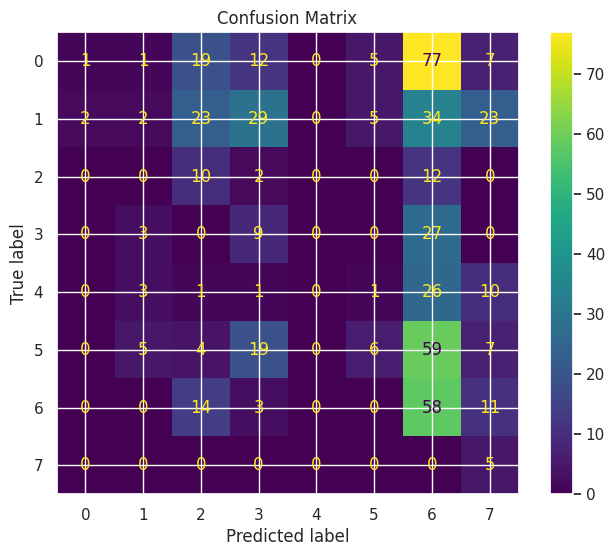

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_relu_adam
------------------------------
TRAIN
Accuracy: 0.7590
Precision: 0.7651
Recall: 0.7590
F1: 0.7577
Kappa: 0.7055
Error Rate: 0.2410

TEST
Accuracy: 0.0877
Precision: 0.3115
Recall: 0.0877
F1: 0.0646
Kappa: 0.0269
Error Rate: 0.9123
Gap (overfitting): 0.6713

CV
Mean: 0.6672
Std: 0.0685
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



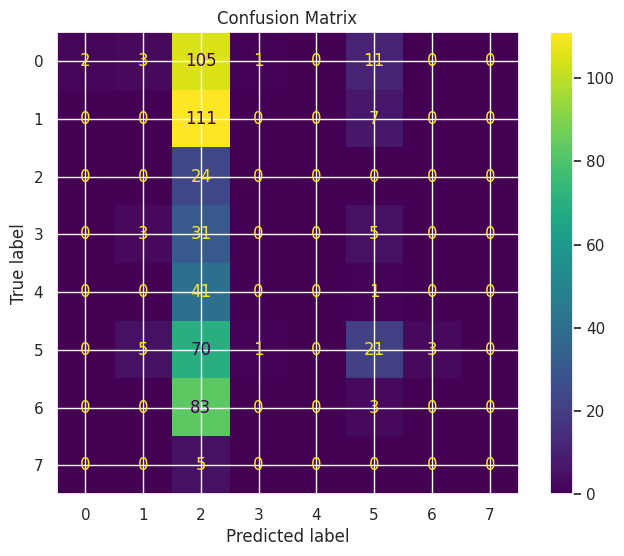

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_relu_sgd_momentum
------------------------------
TRAIN
Accuracy: 0.4572
Precision: 0.4106
Recall: 0.4572
F1: 0.4208
Kappa: 0.3242
Error Rate: 0.5428

TEST
Accuracy: 0.2407
Precision: 0.2941
Recall: 0.2407
F1: 0.1902
Kappa: 0.0837
Error Rate: 0.7593
Gap (overfitting): 0.2165

CV
Mean: 0.3815
Std: 0.0416
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'sgd', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



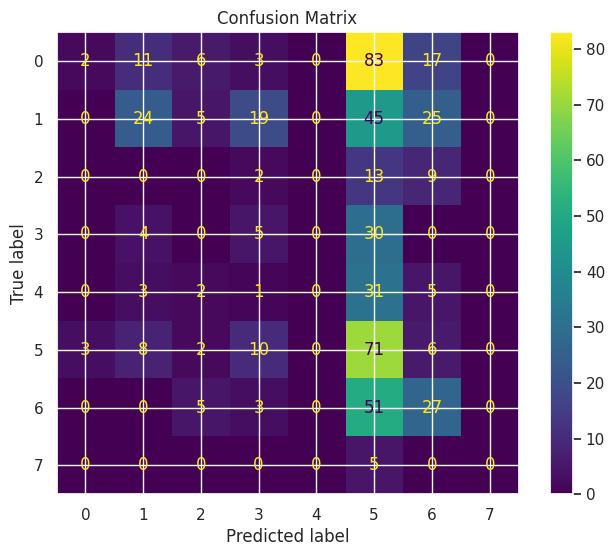

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/n


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_tanh_adam
------------------------------
TRAIN
Accuracy: 0.6821
Precision: 0.6912
Recall: 0.6821
F1: 0.6786
Kappa: 0.6109
Error Rate: 0.3179

TEST
Accuracy: 0.0560
Precision: 0.0157
Recall: 0.0560
F1: 0.0132
Kappa: 0.0135
Error Rate: 0.9440
Gap (overfitting): 0.6262

CV
Mean: 0.6616
Std: 0.1166
------------------------------
Model params:
{'activation': 'tanh', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



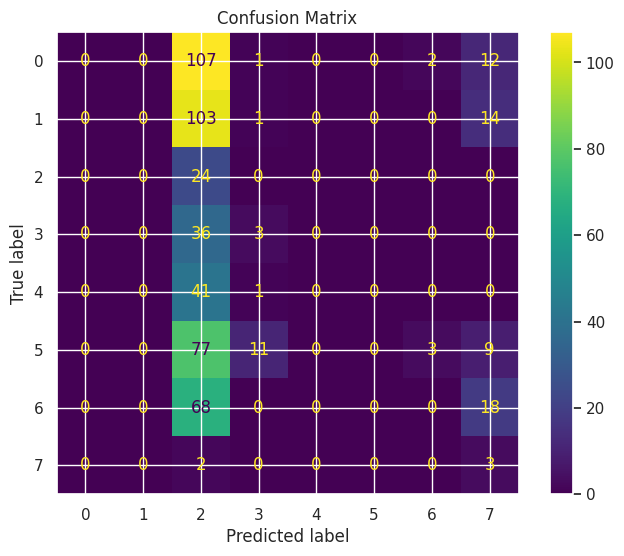

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_relu_adam_lowLR
------------------------------
TRAIN
Accuracy: 0.4556
Precision: 0.4105
Recall: 0.4556
F1: 0.4188
Kappa: 0.3216
Error Rate: 0.5444

TEST
Accuracy: 0.2239
Precision: 0.2413
Recall: 0.2239
F1: 0.1562
Kappa: 0.0875
Error Rate: 0.7761
Gap (overfitting): 0.2317

CV
Mean: 0.4980
Std: 0.0385
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



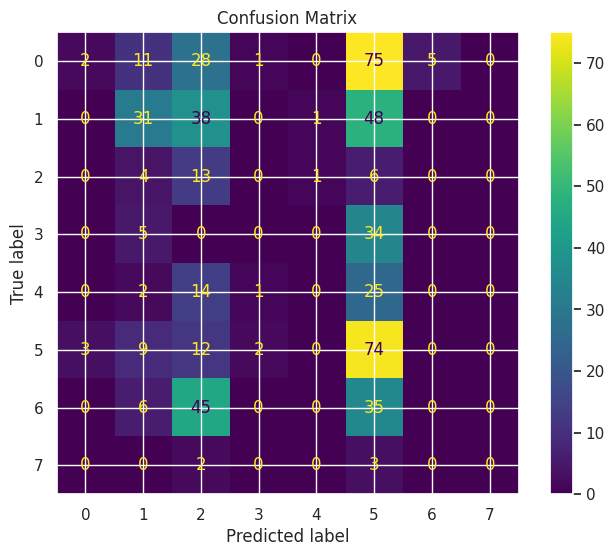

In [ ]:

models = {}
# BASE
models['MLP_lbfgs_30'] = MLPClassifier(
    solver='lbfgs',
    alpha=1e-5,
    hidden_layer_sizes=(30,),
    random_state=42,
    max_iter=500
)

# relu + adam
models['MLP_relu_adam'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-5,
    random_state=42,
    max_iter=500
)



# relu + sgd + momentum
models['MLP_relu_sgd_momentum'] = MLPClassifier(
    solver='sgd',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-5,
    momentum=0.9,
    random_state=42,
    max_iter=500
)

# tanh + adam
models['MLP_tanh_adam'] = MLPClassifier(
    solver='adam',
    activation='tanh',
    hidden_layer_sizes=(30,),
    alpha=1e-5,
    random_state=42,
    max_iter=500
)

# relu + adam + learning rate menor
models['MLP_relu_adam_lowLR'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-5,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)

main(models, "teste_combinacoes")

Segundi Iniciar fase de afunilamento


1º Fazer algumas referncias do base

2º FASE 2 PEGAS OS MELHROES DAQUI, E DIVIDIR EM GRUPO (ATIVAÇÃO, REGULARIZACAO,...)

3º PEGA OS MELHORES MAS FUNILAMENTO

/tmp/ipykernel_3949/173336096.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to co


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_relu_adam_lowLR_30
------------------------------
TRAIN
Accuracy: 0.4412
Precision: 0.4718
Recall: 0.4412
F1: 0.4217
Kappa: 0.3086
Error Rate: 0.5588

TEST
Accuracy: 0.2649
Precision: 0.1373
Recall: 0.2649
F1: 0.1617
Kappa: 0.0730
Error Rate: 0.7351
Gap (overfitting): 0.1762

CV
Mean: 0.4123
Std: 0.1092
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



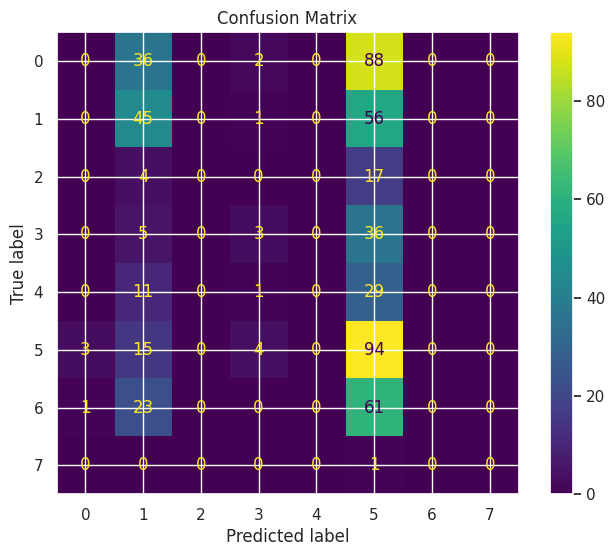

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_relu_adam_lowLR_50
------------------------------
TRAIN
Accuracy: 0.4940
Precision: 0.5304
Recall: 0.4940
F1: 0.4719
Kappa: 0.3736
Error Rate: 0.5060

TEST
Accuracy: 0.2425
Precision: 0.1914
Recall: 0.2425
F1: 0.1652
Kappa: 0.0489
Error Rate: 0.7575
Gap (overfitting): 0.2515

CV
Mean: 0.5221
Std: 0.1001
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50,), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



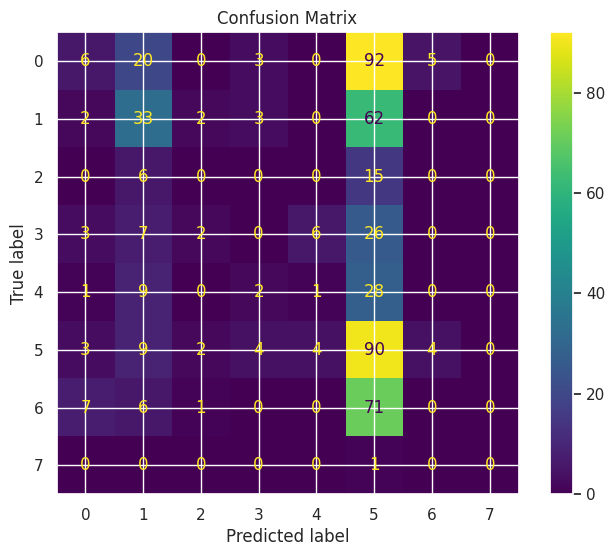

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_relu_adam_lowLR_50_25
------------------------------
TRAIN
Accuracy: 0.5308
Precision: 0.5627
Recall: 0.5308
F1: 0.5050
Kappa: 0.4179
Error Rate: 0.4692

TEST
Accuracy: 0.1698
Precision: 0.1897
Recall: 0.1698
F1: 0.1515
Kappa: 0.0467
Error Rate: 0.8302
Gap (overfitting): 0.3610

CV
Mean: 0.4756
Std: 0.0813
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50, 25), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



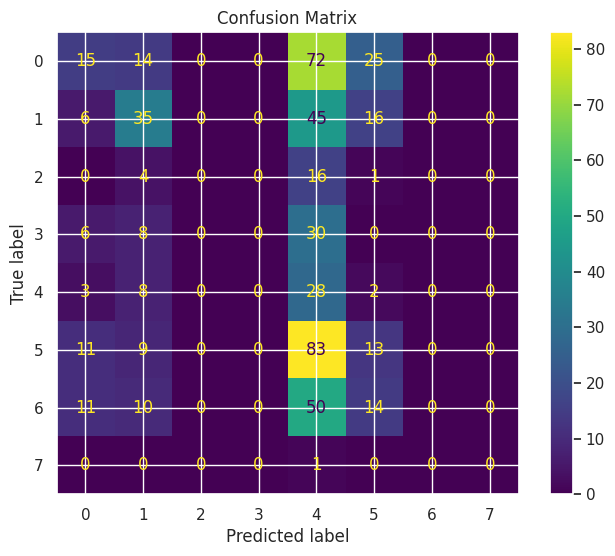

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_relu_adam_lowLR_reg1e3
------------------------------
TRAIN
Accuracy: 0.4956
Precision: 0.5308
Recall: 0.4956
F1: 0.4738
Kappa: 0.3754
Error Rate: 0.5044

TEST
Accuracy: 0.2519
Precision: 0.1951
Recall: 0.2519
F1: 0.1724
Kappa: 0.0567
Error Rate: 0.7481
Gap (overfitting): 0.2437

CV
Mean: 0.5165
Std: 0.1095
------------------------------
Model params:
{'activation': 'relu', 'alpha': 0.001, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50,), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



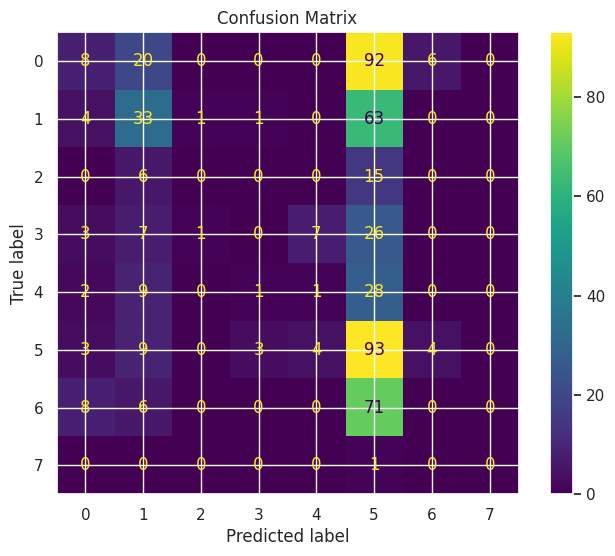

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_relu_adam_lowLR_reg5e3
------------------------------
TRAIN
Accuracy: 0.4924
Precision: 0.5289
Recall: 0.4924
F1: 0.4707
Kappa: 0.3715
Error Rate: 0.5076

TEST
Accuracy: 0.2519
Precision: 0.1944
Recall: 0.2519
F1: 0.1722
Kappa: 0.0562
Error Rate: 0.7481
Gap (overfitting): 0.2405

CV
Mean: 0.5154
Std: 0.1112
------------------------------
Model params:
{'activation': 'relu', 'alpha': 0.005, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50,), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



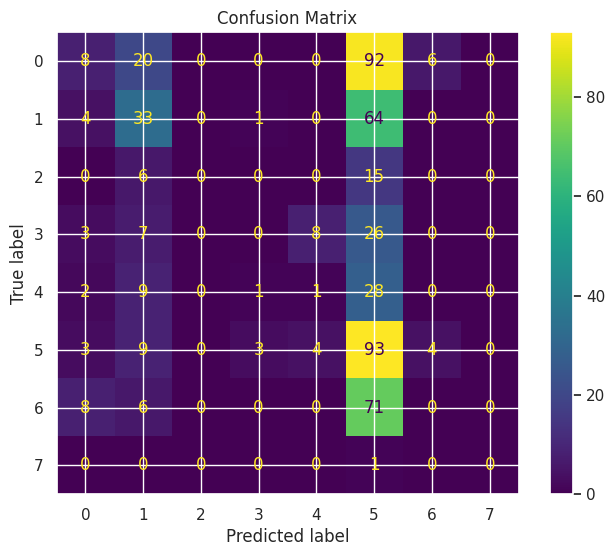

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_relu_sgd_30
------------------------------
TRAIN
Accuracy: 0.4532
Precision: 0.4777
Recall: 0.4532
F1: 0.4297
Kappa: 0.3243
Error Rate: 0.5468

TEST
Accuracy: 0.2705
Precision: 0.1266
Recall: 0.2705
F1: 0.1637
Kappa: 0.0807
Error Rate: 0.7295
Gap (overfitting): 0.1826

CV
Mean: 0.2443
Std: 0.0141
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'sgd', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



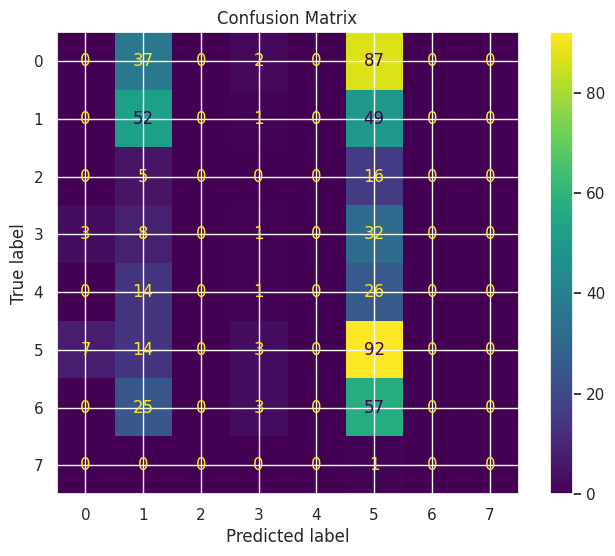

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_relu_sgd_50
------------------------------
TRAIN
Accuracy: 0.4676
Precision: 0.5031
Recall: 0.4676
F1: 0.4404
Kappa: 0.3405
Error Rate: 0.5324

TEST
Accuracy: 0.2593
Precision: 0.3305
Recall: 0.2593
F1: 0.1892
Kappa: 0.0852
Error Rate: 0.7407
Gap (overfitting): 0.2082

CV
Mean: 0.2560
Std: 0.0381
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50,), 'learning_rate': 'constant', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'sgd', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



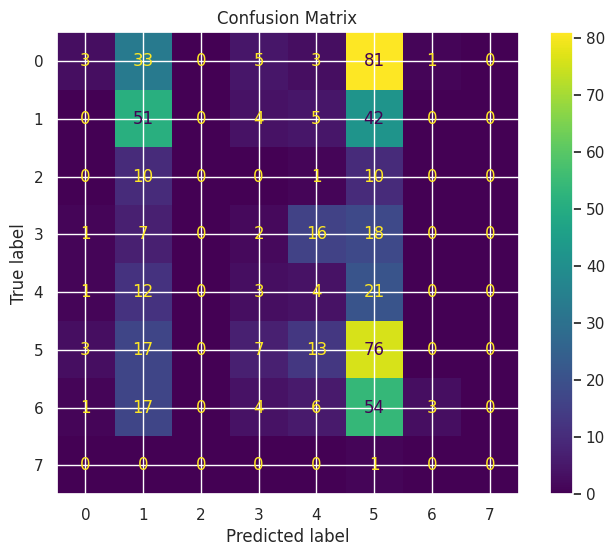

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_relu_sgd_adaptive
------------------------------
TRAIN
Accuracy: 0.5068
Precision: 0.5299
Recall: 0.5068
F1: 0.4879
Kappa: 0.3890
Error Rate: 0.4932

TEST
Accuracy: 0.2593
Precision: 0.3843
Recall: 0.2593
F1: 0.1926
Kappa: 0.0747
Error Rate: 0.7407
Gap (overfitting): 0.2475

CV
Mean: 0.2487
Std: 0.0357
------------------------------
Model params:
{'activation': 'relu', 'alpha': 0.001, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50,), 'learning_rate': 'adaptive', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.95, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'sgd', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



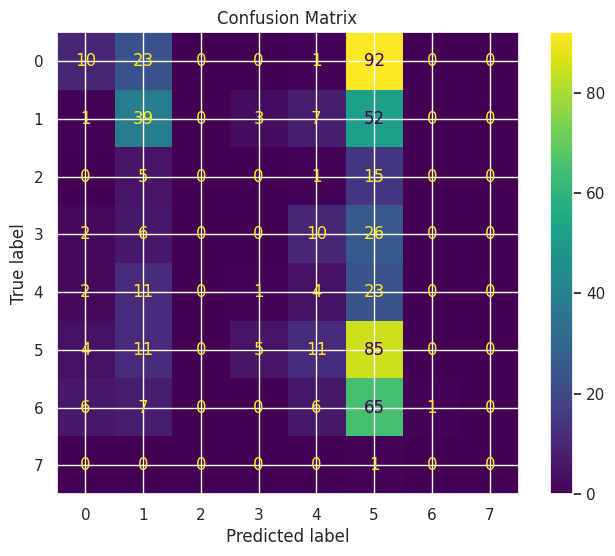

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: Conv


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_lbfgs_30
------------------------------
TRAIN
Accuracy: 0.9472
Precision: 0.9478
Recall: 0.9472
F1: 0.9472
Kappa: 0.9361
Error Rate: 0.0528

TEST
Accuracy: 0.2127
Precision: 0.1872
Recall: 0.2127
F1: 0.0863
Kappa: -0.0043
Error Rate: 0.7873
Gap (overfitting): 0.7345

CV
Mean: 0.4303
Std: 0.0457
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'lbfgs', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



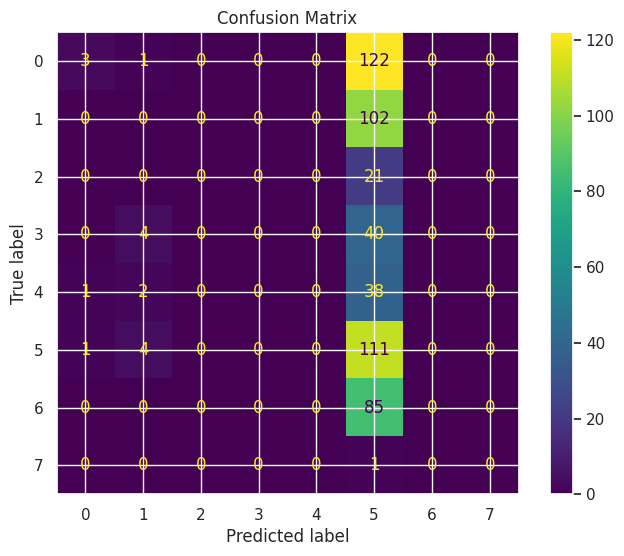

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: Conv


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_lbfgs_50
------------------------------
TRAIN
Accuracy: 0.9848
Precision: 0.9848
Recall: 0.9848
F1: 0.9848
Kappa: 0.9816
Error Rate: 0.0152

TEST
Accuracy: 0.0522
Precision: 0.0942
Recall: 0.0522
F1: 0.0258
Kappa: 0.0027
Error Rate: 0.9478
Gap (overfitting): 0.9325

CV
Mean: 0.5826
Std: 0.0880
------------------------------
Model params:
{'activation': 'relu', 'alpha': 0.001, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50,), 'learning_rate': 'constant', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 1000, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'lbfgs', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



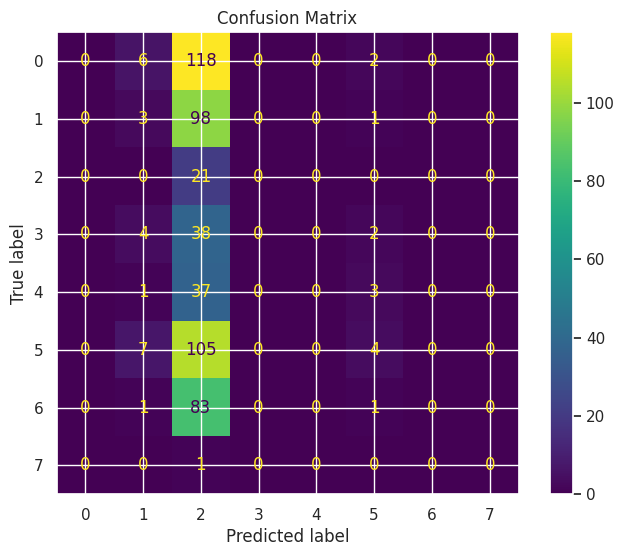

In [ ]:
models_f1 = {}
models_f1['MLP_relu_adam_lowLR_30'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-5,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)

models_f1['MLP_relu_adam_lowLR_50'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(50,),
    alpha=1e-5,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)

models_f1['MLP_relu_adam_lowLR_50_25'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(50, 25),
    alpha=1e-5,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)

models_f1['MLP_relu_adam_lowLR_reg1e3'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(50,),
    alpha=1e-3,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)

models_f1['MLP_relu_adam_lowLR_reg5e3'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(50,),
    alpha=5e-3,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)

models_f1['MLP_relu_sgd_30'] = MLPClassifier(
    solver='sgd',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-5,
    momentum=0.9,
    random_state=42,
    max_iter=500
)

models_f1['MLP_relu_sgd_50'] = MLPClassifier(
    solver='sgd',
    activation='relu',
    hidden_layer_sizes=(50,),
    alpha=1e-5,
    momentum=0.9,
    random_state=42,
    max_iter=500
)

models_f1['MLP_relu_sgd_adaptive'] = MLPClassifier(
    solver='sgd',
    activation='relu',
    hidden_layer_sizes=(50,),
    alpha=1e-3,
    momentum=0.95,
    learning_rate='adaptive',
    random_state=42,
    max_iter=500
)

models_f1['MLP_lbfgs_30'] = MLPClassifier(
    solver='lbfgs',
    hidden_layer_sizes=(30,),
    alpha=1e-5,
    random_state=42,
    max_iter=500
)

models_f1['MLP_lbfgs_50'] = MLPClassifier(
    solver='lbfgs',
    hidden_layer_sizes=(50,),
    alpha=1e-3,
    random_state=42,
    max_iter=1000
)

main(models_f1, "fase_1")

/tmp/ipykernel_3949/173336096.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to co


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_solver_adam
------------------------------
TRAIN
Accuracy: 0.4396
Precision: 0.4495
Recall: 0.4396
F1: 0.4163
Kappa: 0.3018
Error Rate: 0.5604

TEST
Accuracy: 0.2537
Precision: 0.1903
Recall: 0.2537
F1: 0.1871
Kappa: 0.0700
Error Rate: 0.7463
Gap (overfitting): 0.1858

CV
Mean: 0.4006
Std: 0.0858
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



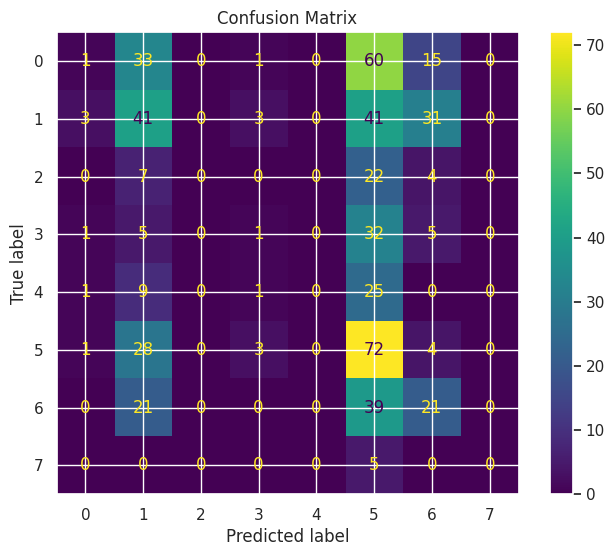

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_solver_sgd
------------------------------
TRAIN
Accuracy: 0.2434
Precision: 0.1736
Recall: 0.2434
F1: 0.1630
Kappa: 0.0253
Error Rate: 0.7566

TEST
Accuracy: 0.2332
Precision: 0.1451
Recall: 0.2332
F1: 0.1627
Kappa: 0.0334
Error Rate: 0.7668
Gap (overfitting): 0.0102

CV
Mean: 0.3412
Std: 0.0687
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'sgd', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



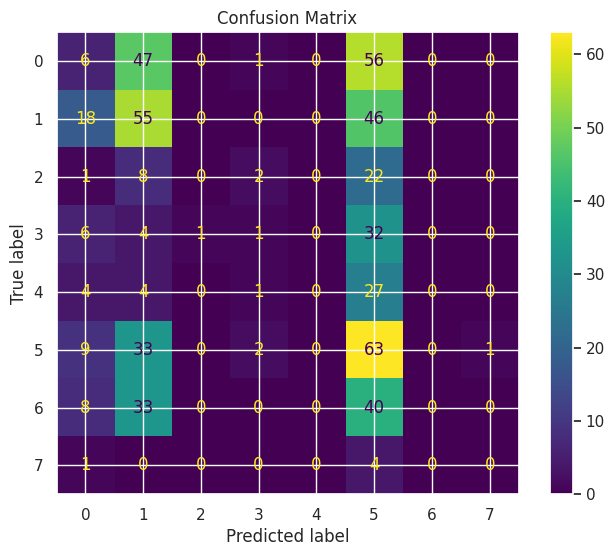

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: Conv


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_solver_lbfgs
------------------------------
TRAIN
Accuracy: 0.8223
Precision: 0.8274
Recall: 0.8223
F1: 0.8224
Kappa: 0.7835
Error Rate: 0.1777

TEST
Accuracy: 0.0858
Precision: 0.1488
Recall: 0.0858
F1: 0.0533
Kappa: 0.0055
Error Rate: 0.9142
Gap (overfitting): 0.7364

CV
Mean: 0.4398
Std: 0.1018
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'lbfgs', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



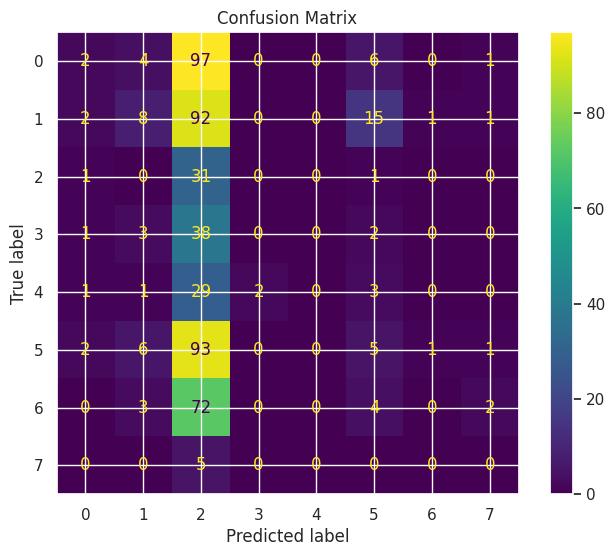

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_activation_relu
------------------------------
TRAIN
Accuracy: 0.4396
Precision: 0.4495
Recall: 0.4396
F1: 0.4163
Kappa: 0.3018
Error Rate: 0.5604

TEST
Accuracy: 0.2537
Precision: 0.1903
Recall: 0.2537
F1: 0.1871
Kappa: 0.0700
Error Rate: 0.7463
Gap (overfitting): 0.1858

CV
Mean: 0.4006
Std: 0.0858
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



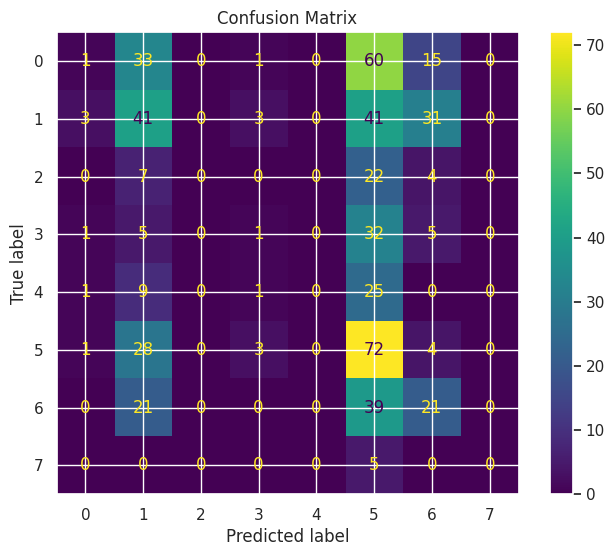

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/n


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_activation_tanh
------------------------------
TRAIN
Accuracy: 0.4620
Precision: 0.4808
Recall: 0.4620
F1: 0.4384
Kappa: 0.3304
Error Rate: 0.5380

TEST
Accuracy: 0.2239
Precision: 0.2431
Recall: 0.2239
F1: 0.1893
Kappa: 0.0754
Error Rate: 0.7761
Gap (overfitting): 0.2381

CV
Mean: 0.2924
Std: 0.0592
------------------------------
Model params:
{'activation': 'tanh', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



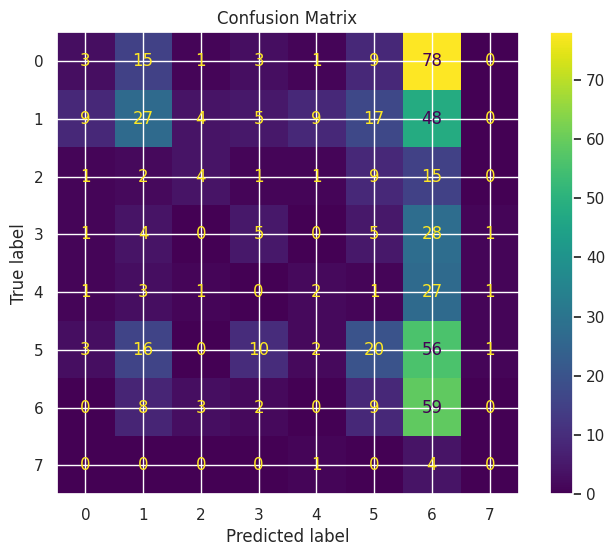

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_activation_logistic
------------------------------
TRAIN
Accuracy: 0.2882
Precision: 0.1277
Recall: 0.2882
F1: 0.1749
Kappa: 0.0816
Error Rate: 0.7118

TEST
Accuracy: 0.2332
Precision: 0.2074
Recall: 0.2332
F1: 0.1908
Kappa: 0.0455
Error Rate: 0.7668
Gap (overfitting): 0.0550

CV
Mean: 0.4034
Std: 0.0924
------------------------------
Model params:
{'activation': 'logistic', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



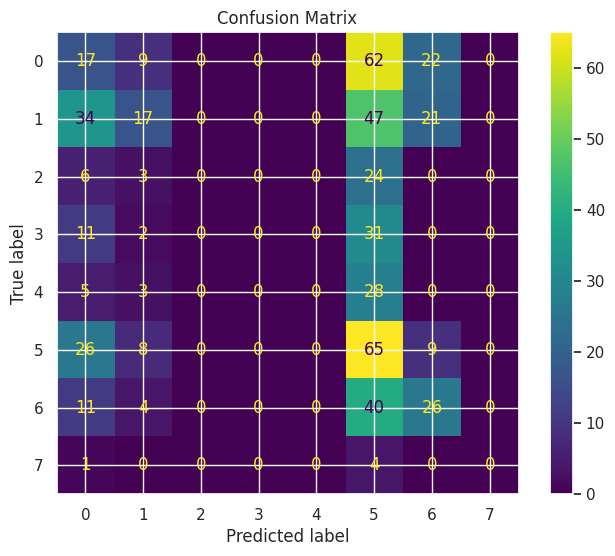

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_arch_10
------------------------------
TRAIN
Accuracy: 0.3090
Precision: 0.3331
Recall: 0.3090
F1: 0.2643
Kappa: 0.1219
Error Rate: 0.6910

TEST
Accuracy: 0.0765
Precision: 0.2399
Recall: 0.0765
F1: 0.0483
Kappa: -0.0069
Error Rate: 0.9235
Gap (overfitting): 0.2326

CV
Mean: 0.1899
Std: 0.0220
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (10,), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



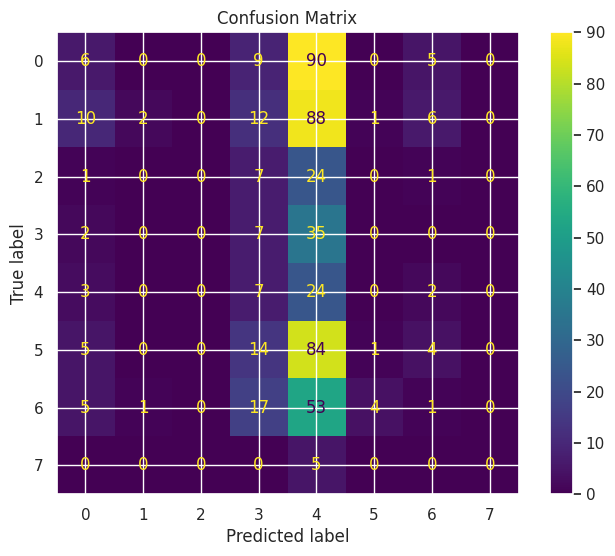

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_arch_30
------------------------------
TRAIN
Accuracy: 0.4396
Precision: 0.4495
Recall: 0.4396
F1: 0.4163
Kappa: 0.3018
Error Rate: 0.5604

TEST
Accuracy: 0.2537
Precision: 0.1903
Recall: 0.2537
F1: 0.1871
Kappa: 0.0700
Error Rate: 0.7463
Gap (overfitting): 0.1858

CV
Mean: 0.4006
Std: 0.0858
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



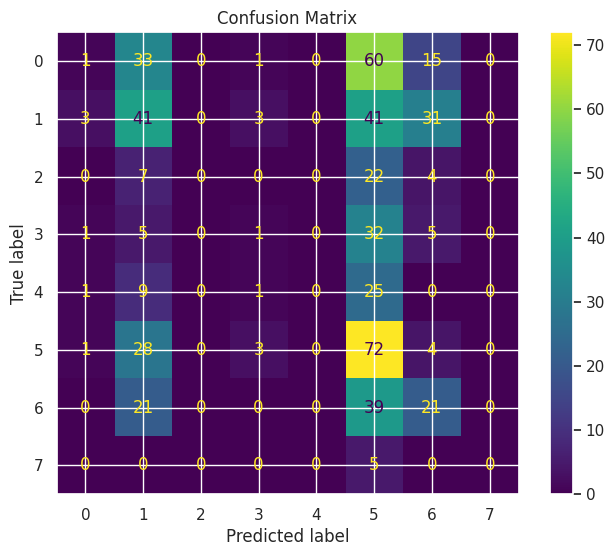

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_arch_50
------------------------------
TRAIN
Accuracy: 0.5020
Precision: 0.5324
Recall: 0.5020
F1: 0.4832
Kappa: 0.3799
Error Rate: 0.4980

TEST
Accuracy: 0.2313
Precision: 0.2005
Recall: 0.2313
F1: 0.1922
Kappa: 0.0643
Error Rate: 0.7687
Gap (overfitting): 0.2707

CV
Mean: 0.4583
Std: 0.1068
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50,), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



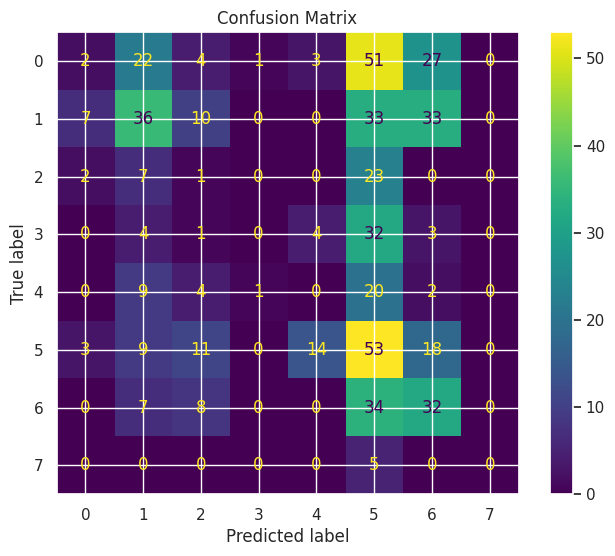

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_arch_50_25
------------------------------
TRAIN
Accuracy: 0.5068
Precision: 0.5656
Recall: 0.5068
F1: 0.4949
Kappa: 0.3892
Error Rate: 0.4932

TEST
Accuracy: 0.1847
Precision: 0.2506
Recall: 0.1847
F1: 0.1699
Kappa: 0.0719
Error Rate: 0.8153
Gap (overfitting): 0.3221

CV
Mean: 0.4241
Std: 0.0867
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50, 25), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



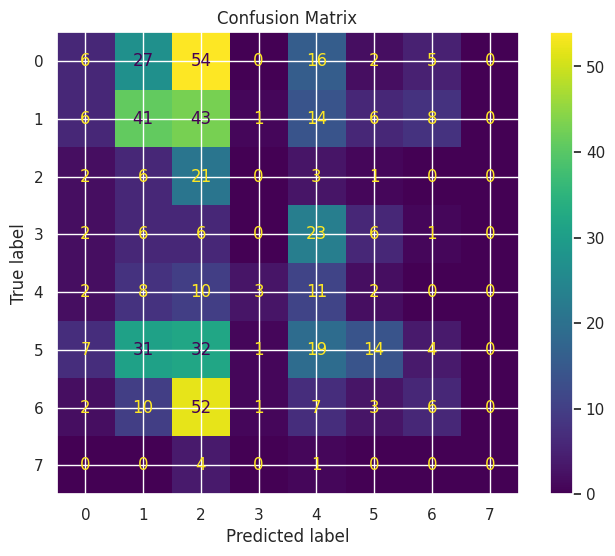

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_alpha_1e-6
------------------------------
TRAIN
Accuracy: 0.4396
Precision: 0.4495
Recall: 0.4396
F1: 0.4163
Kappa: 0.3018
Error Rate: 0.5604

TEST
Accuracy: 0.2556
Precision: 0.2070
Recall: 0.2556
F1: 0.1906
Kappa: 0.0684
Error Rate: 0.7444
Gap (overfitting): 0.1840

CV
Mean: 0.4006
Std: 0.0858
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-06, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



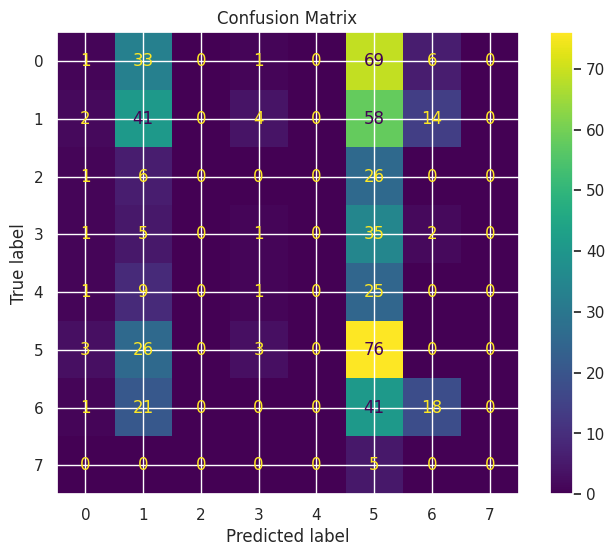

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_alpha_1e-5
------------------------------
TRAIN
Accuracy: 0.4396
Precision: 0.4495
Recall: 0.4396
F1: 0.4163
Kappa: 0.3018
Error Rate: 0.5604

TEST
Accuracy: 0.2537
Precision: 0.1903
Recall: 0.2537
F1: 0.1871
Kappa: 0.0700
Error Rate: 0.7463
Gap (overfitting): 0.1858

CV
Mean: 0.4006
Std: 0.0858
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



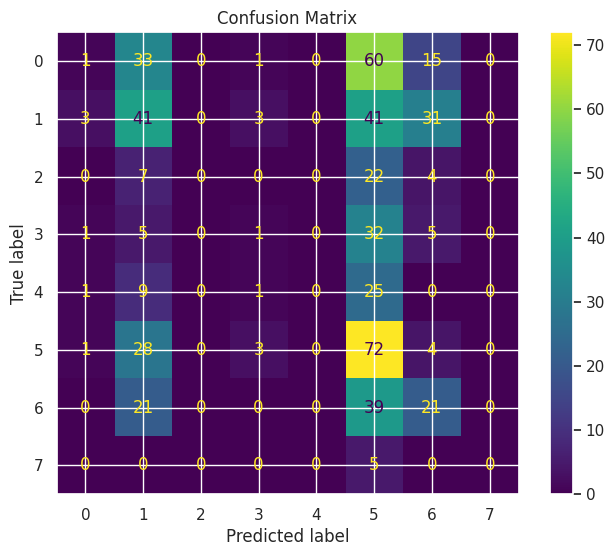

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_alpha_1e-4
------------------------------
TRAIN
Accuracy: 0.4388
Precision: 0.4485
Recall: 0.4388
F1: 0.4157
Kappa: 0.3009
Error Rate: 0.5612

TEST
Accuracy: 0.2556
Precision: 0.1887
Recall: 0.2556
F1: 0.1909
Kappa: 0.0747
Error Rate: 0.7444
Gap (overfitting): 0.1832

CV
Mean: 0.4000
Std: 0.0867
------------------------------
Model params:
{'activation': 'relu', 'alpha': 0.0001, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



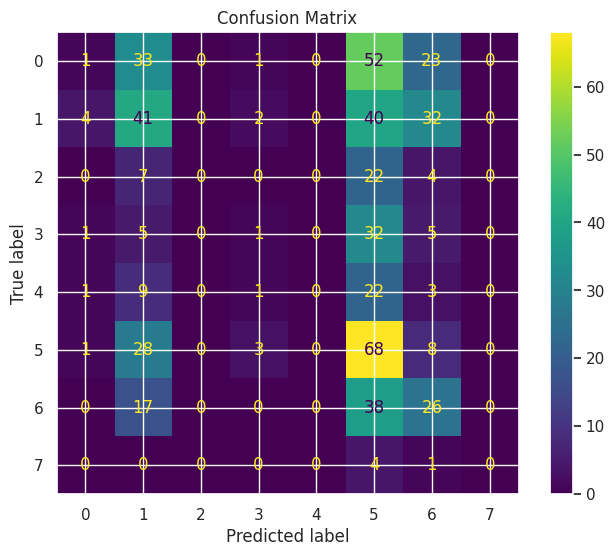

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_alpha_1e-3
------------------------------
TRAIN
Accuracy: 0.4388
Precision: 0.4485
Recall: 0.4388
F1: 0.4157
Kappa: 0.3009
Error Rate: 0.5612

TEST
Accuracy: 0.2724
Precision: 0.1998
Recall: 0.2724
F1: 0.2048
Kappa: 0.0967
Error Rate: 0.7276
Gap (overfitting): 0.1664

CV
Mean: 0.4000
Std: 0.0867
------------------------------
Model params:
{'activation': 'relu', 'alpha': 0.001, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



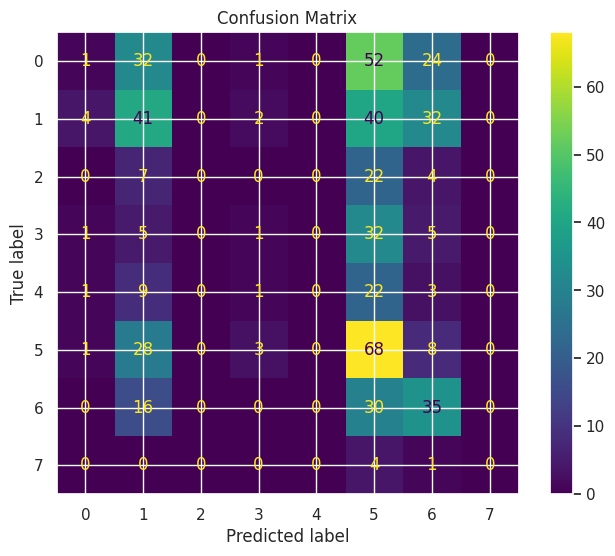

In [ ]:
models_f2 = {}
#OTIMIZADOR
models_f2['MLP_solver_adam'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-5,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)

models_f2['MLP_solver_sgd'] = MLPClassifier(
    solver='sgd',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-5,
    learning_rate_init=0.0001,
    momentum=0.9,
    random_state=42,
    max_iter=500
)

models_f2['MLP_solver_lbfgs'] = MLPClassifier(
    solver='lbfgs',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-5,
    random_state=42,
    max_iter=500
)
#ATIVAÇÃO
models_f2['MLP_activation_relu'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-5,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)

models_f2['MLP_activation_tanh'] = MLPClassifier(
    solver='adam',
    activation='tanh',
    hidden_layer_sizes=(30,),
    alpha=1e-5,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)

models_f2['MLP_activation_logistic'] = MLPClassifier(
    solver='adam',
    activation='logistic',
    hidden_layer_sizes=(30,),
    alpha=1e-5,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)
#ARQAUITTRUA
models_f2['MLP_arch_10'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(10,),
    alpha=1e-5,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)

models_f2['MLP_arch_30'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-5,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)

models_f2['MLP_arch_50'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(50,),
    alpha=1e-5,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)

models_f2['MLP_arch_50_25'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(50, 25),
    alpha=1e-5,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)
#REGULARIZCAO
models_f2['MLP_alpha_1e-6'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-6,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)

models_f2['MLP_alpha_1e-5'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-5,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)

models_f2['MLP_alpha_1e-4'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-4,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)

models_f2['MLP_alpha_1e-3'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-3,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)
main(models_f2, "fase_2")
#FASE 2 PEGAS OS MELHROES DAQUI
#FASE 3 MUDA SEMNTE, MUDA NUMERO DE TIRACOES
#

/tmp/ipykernel_3949/173336096.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to co


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_30_alpha1e-4_adam
------------------------------
TRAIN
Accuracy: 0.4307
Precision: 0.4558
Recall: 0.4307
F1: 0.4174
Kappa: 0.2976
Error Rate: 0.5693

TEST
Accuracy: 0.2873
Precision: 0.1891
Recall: 0.2873
F1: 0.2019
Kappa: 0.0978
Error Rate: 0.7127
Gap (overfitting): 0.1434

CV
Mean: 0.4364
Std: 0.0868
------------------------------
Model params:
{'activation': 'relu', 'alpha': 0.0001, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



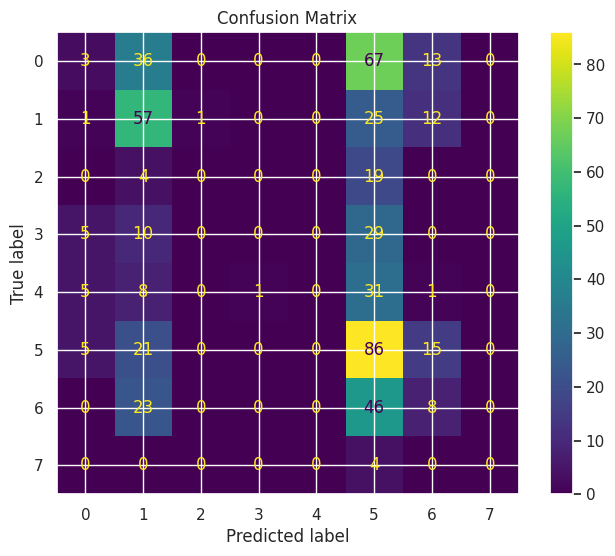

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_30_alpha1e-6_adam
------------------------------
TRAIN
Accuracy: 0.4363
Precision: 0.4632
Recall: 0.4363
F1: 0.4233
Kappa: 0.3041
Error Rate: 0.5637

TEST
Accuracy: 0.2799
Precision: 0.1713
Recall: 0.2799
F1: 0.1859
Kappa: 0.0833
Error Rate: 0.7201
Gap (overfitting): 0.1565

CV
Mean: 0.4370
Std: 0.0866
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-06, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



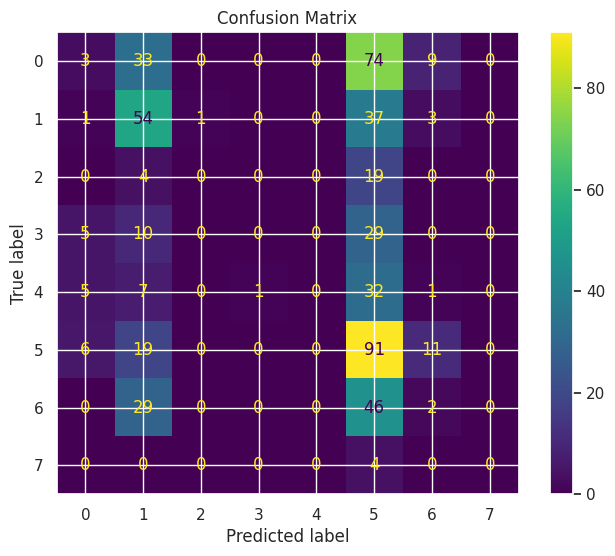

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_alpha1e-4_adam
------------------------------
TRAIN
Accuracy: 0.4812
Precision: 0.4919
Recall: 0.4812
F1: 0.4638
Kappa: 0.3607
Error Rate: 0.5188

TEST
Accuracy: 0.2071
Precision: 0.2707
Recall: 0.2071
F1: 0.1869
Kappa: 0.0878
Error Rate: 0.7929
Gap (overfitting): 0.2741

CV
Mean: 0.4689
Std: 0.0980
------------------------------
Model params:
{'activation': 'relu', 'alpha': 0.0001, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50,), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



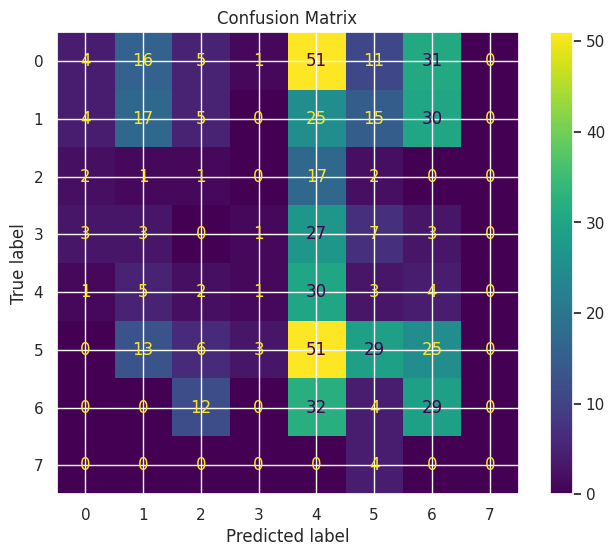

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_alpha1e-6_adam
------------------------------
TRAIN
Accuracy: 0.4812
Precision: 0.4919
Recall: 0.4812
F1: 0.4638
Kappa: 0.3607
Error Rate: 0.5188

TEST
Accuracy: 0.2295
Precision: 0.3126
Recall: 0.2295
F1: 0.2017
Kappa: 0.1119
Error Rate: 0.7705
Gap (overfitting): 0.2517

CV
Mean: 0.4672
Std: 0.0985
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-06, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50,), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



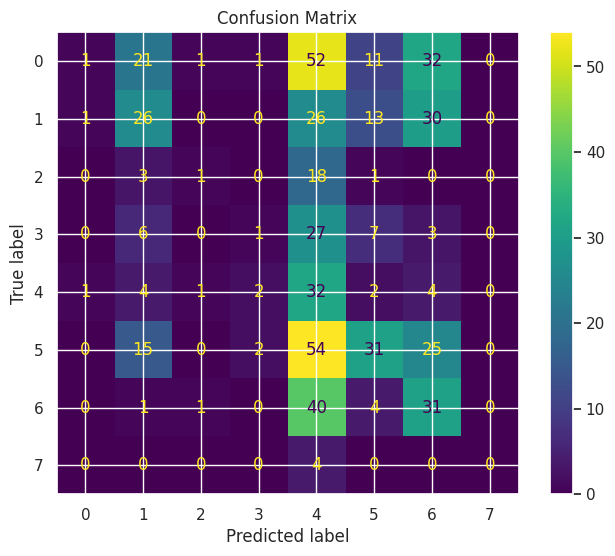

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_25_alpha1e-4_adam
------------------------------
TRAIN
Accuracy: 0.4980
Precision: 0.5083
Recall: 0.4980
F1: 0.4844
Kappa: 0.3811
Error Rate: 0.5020

TEST
Accuracy: 0.1101
Precision: 0.4185
Recall: 0.1101
F1: 0.1208
Kappa: 0.0302
Error Rate: 0.8899
Gap (overfitting): 0.3879

CV
Mean: 0.4751
Std: 0.0861
------------------------------
Model params:
{'activation': 'relu', 'alpha': 0.0001, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50, 25), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



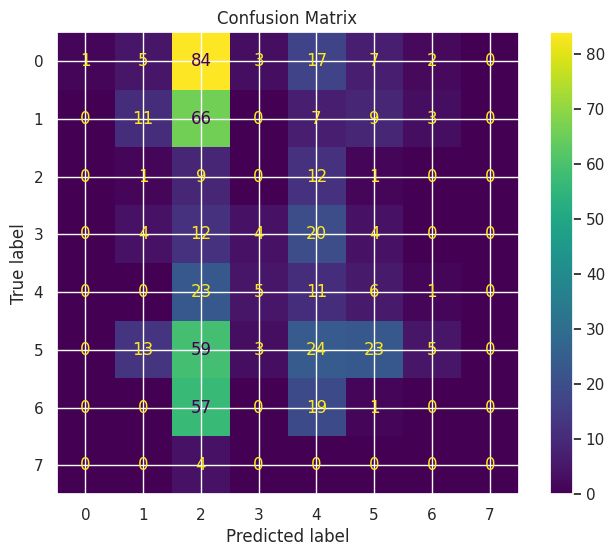

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_25_alpha1e-6_adam
------------------------------
TRAIN
Accuracy: 0.5004
Precision: 0.5115
Recall: 0.5004
F1: 0.4865
Kappa: 0.3841
Error Rate: 0.4996

TEST
Accuracy: 0.1101
Precision: 0.2087
Recall: 0.1101
F1: 0.1116
Kappa: 0.0379
Error Rate: 0.8899
Gap (overfitting): 0.3903

CV
Mean: 0.4706
Std: 0.0905
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-06, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50, 25), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



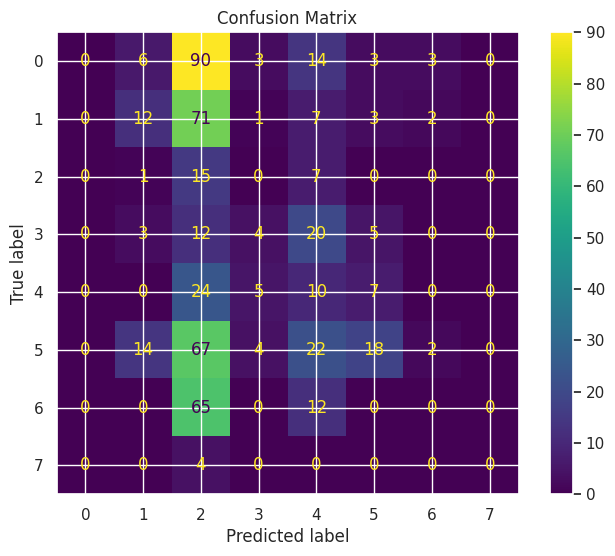

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_alpha1e-4_sgd
------------------------------
TRAIN
Accuracy: 0.4532
Precision: 0.4735
Recall: 0.4532
F1: 0.4402
Kappa: 0.3256
Error Rate: 0.5468

TEST
Accuracy: 0.1660
Precision: 0.2399
Recall: 0.1660
F1: 0.1349
Kappa: 0.0560
Error Rate: 0.8340
Gap (overfitting): 0.2871

CV
Mean: 0.2863
Std: 0.0336
------------------------------
Model params:
{'activation': 'relu', 'alpha': 0.0001, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50,), 'learning_rate': 'adaptive', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'sgd', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



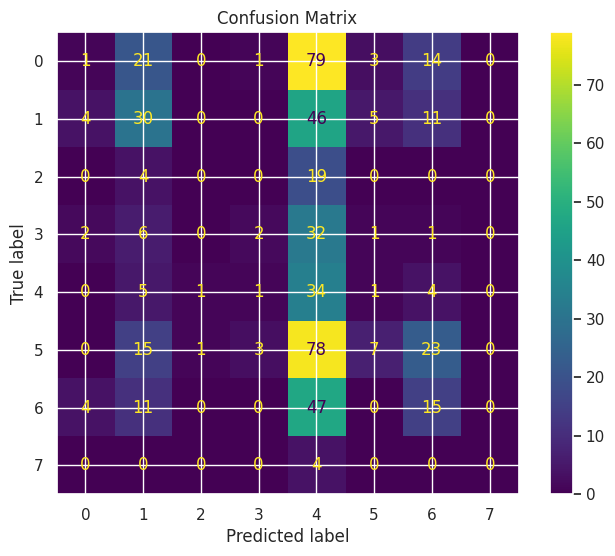

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_30_alpha1e-4_sgd
------------------------------
TRAIN
Accuracy: 0.4179
Precision: 0.4405
Recall: 0.4179
F1: 0.3992
Kappa: 0.2807
Error Rate: 0.5821

TEST
Accuracy: 0.2575
Precision: 0.1929
Recall: 0.2575
F1: 0.1955
Kappa: 0.0973
Error Rate: 0.7425
Gap (overfitting): 0.1605

CV
Mean: 0.2403
Std: 0.0162
------------------------------
Model params:
{'activation': 'relu', 'alpha': 0.0001, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'adaptive', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'sgd', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



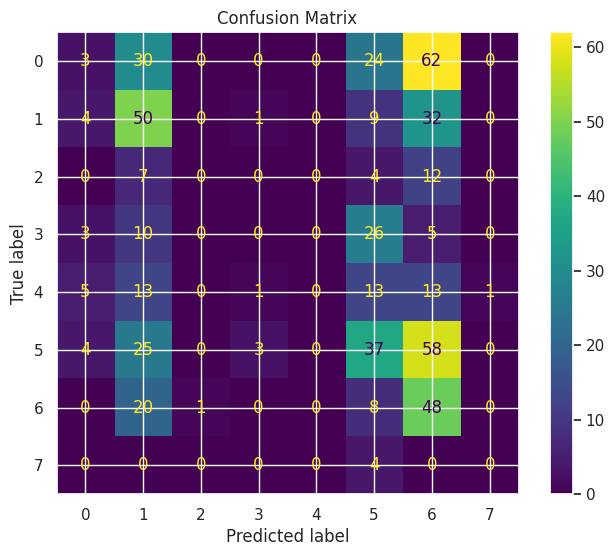

In [ ]:
models_f3 = {}

# =========================
# 🔥 BASE TOP (ADAM)
# =========================

models_f3['F2_30_alpha1e-4_adam'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-4,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)

models_f3['F2_30_alpha1e-6_adam'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-6,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)

models_f3['F2_50_alpha1e-4_adam'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(50,),
    alpha=1e-4,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)

models_f3['F2_50_alpha1e-6_adam'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(50,),
    alpha=1e-6,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)

models_f3['F2_50_25_alpha1e-4_adam'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(50, 25),
    alpha=1e-4,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)

models_f3['F2_50_25_alpha1e-6_adam'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(50, 25),
    alpha=1e-6,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)

# =========================
# ⚖️ CONTROLE (SGD)
# =========================

models_f3['F2_50_alpha1e-4_sgd'] = MLPClassifier(
    solver='sgd',
    activation='relu',
    hidden_layer_sizes=(50,),
    alpha=1e-4,
    momentum=0.9,
    learning_rate='adaptive',
    random_state=42,
    max_iter=500
)

models_f3['F2_30_alpha1e-4_sgd'] = MLPClassifier(
    solver='sgd',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-4,
    momentum=0.9,
    learning_rate='adaptive',
    random_state=42,
    max_iter=500
)
main(models_f3, "fase_3")

/tmp/ipykernel_3949/173336096.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to co


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_30_alpha1e-4_adam
------------------------------
TRAIN
Accuracy: 0.6269
Precision: 0.6413
Recall: 0.6269
F1: 0.6265
Kappa: 0.5449
Error Rate: 0.3731

TEST
Accuracy: 0.0653
Precision: 0.2107
Recall: 0.0653
F1: 0.0295
Kappa: 0.0086
Error Rate: 0.9347
Gap (overfitting): 0.5616

CV
Mean: 0.4622
Std: 0.0615
------------------------------
Model params:
{'activation': 'relu', 'alpha': 0.0001, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



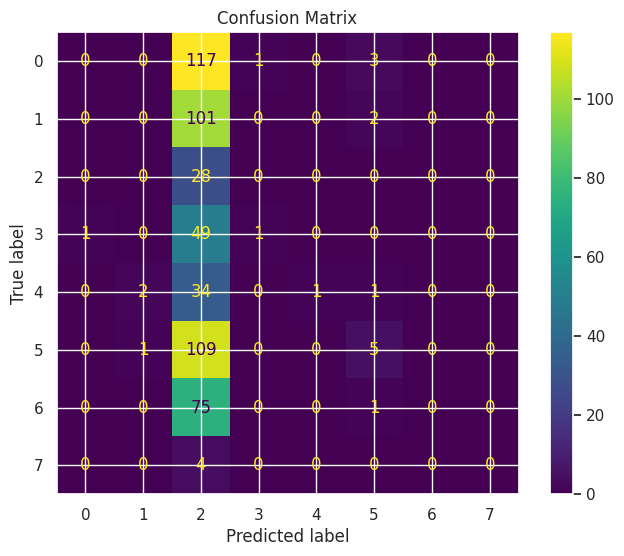

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_30_alpha1e-6_adam
------------------------------
TRAIN
Accuracy: 0.6053
Precision: 0.6170
Recall: 0.6053
F1: 0.6020
Kappa: 0.5182
Error Rate: 0.3947

TEST
Accuracy: 0.0765
Precision: 0.2710
Recall: 0.0765
F1: 0.0458
Kappa: 0.0154
Error Rate: 0.9235
Gap (overfitting): 0.5288

CV
Mean: 0.4633
Std: 0.0621
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-06, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



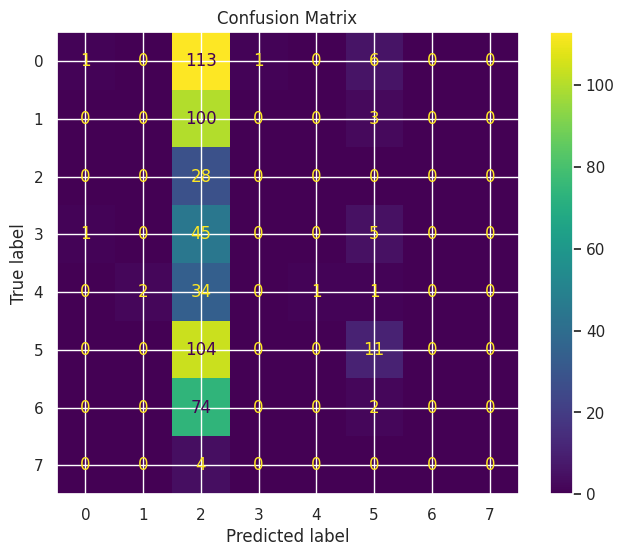

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_30_alpha1e-5_adam
------------------------------
TRAIN
Accuracy: 0.6253
Precision: 0.6391
Recall: 0.6253
F1: 0.6232
Kappa: 0.5424
Error Rate: 0.3747

TEST
Accuracy: 0.0597
Precision: 0.2882
Recall: 0.0597
F1: 0.0197
Kappa: 0.0064
Error Rate: 0.9403
Gap (overfitting): 0.5656

CV
Mean: 0.4611
Std: 0.0630
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



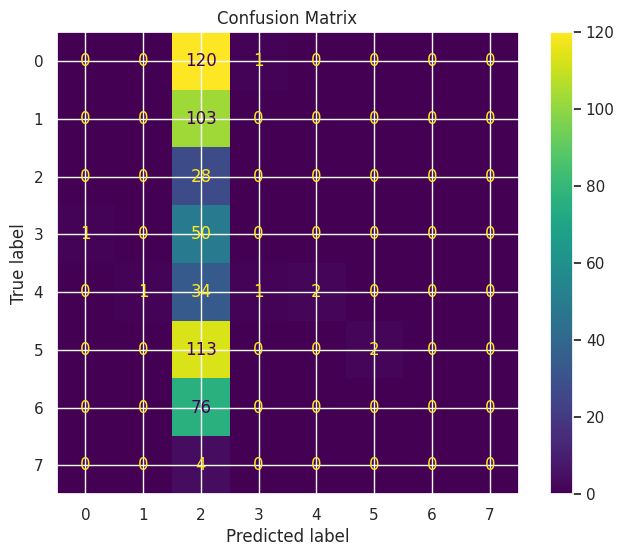

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_50_alpha1e-4_adam
------------------------------
TRAIN
Accuracy: 0.7118
Precision: 0.7336
Recall: 0.7118
F1: 0.7113
Kappa: 0.6480
Error Rate: 0.2882

TEST
Accuracy: 0.1679
Precision: 0.0740
Recall: 0.1679
F1: 0.0950
Kappa: 0.0634
Error Rate: 0.8321
Gap (overfitting): 0.5439

CV
Mean: 0.5266
Std: 0.1398
------------------------------
Model params:
{'activation': 'relu', 'alpha': 0.0001, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50,), 'learning_rate': 'constant', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



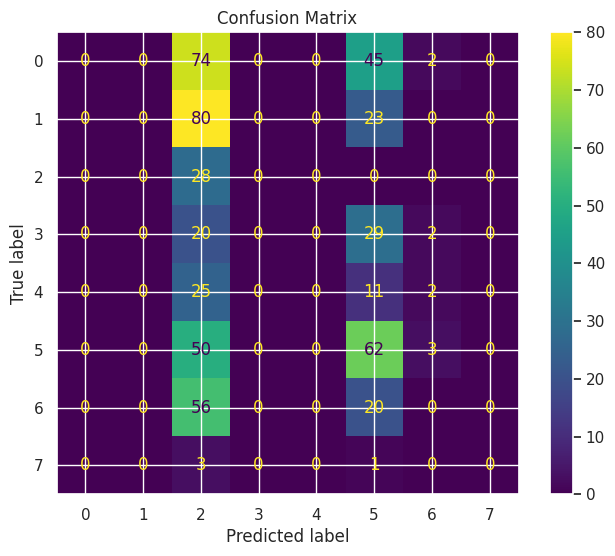

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_50_alpha1e-6_adam
------------------------------
TRAIN
Accuracy: 0.7134
Precision: 0.7387
Recall: 0.7134
F1: 0.7140
Kappa: 0.6497
Error Rate: 0.2866

TEST
Accuracy: 0.1287
Precision: 0.0901
Recall: 0.1287
F1: 0.0850
Kappa: 0.0418
Error Rate: 0.8713
Gap (overfitting): 0.5846

CV
Mean: 0.5249
Std: 0.1428
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-06, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50,), 'learning_rate': 'constant', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



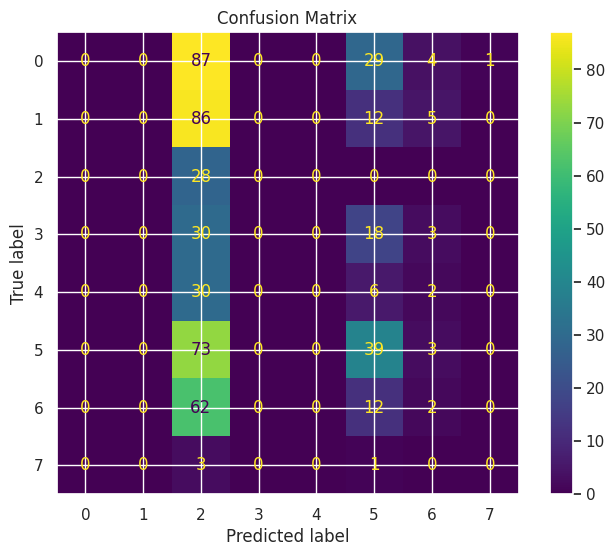

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_50_alpha1e-5_adam
------------------------------
TRAIN
Accuracy: 0.7054
Precision: 0.7281
Recall: 0.7054
F1: 0.7055
Kappa: 0.6401
Error Rate: 0.2946

TEST
Accuracy: 0.0896
Precision: 0.0702
Recall: 0.0896
F1: 0.0539
Kappa: 0.0177
Error Rate: 0.9104
Gap (overfitting): 0.6158

CV
Mean: 0.5249
Std: 0.1404
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50,), 'learning_rate': 'constant', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



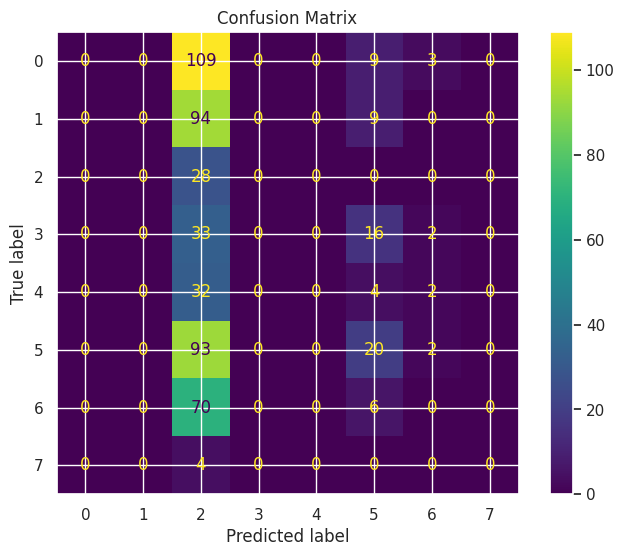

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_50_25_alpha1e-4_adam
------------------------------
TRAIN
Accuracy: 0.8511
Precision: 0.8570
Recall: 0.8511
F1: 0.8501
Kappa: 0.8190
Error Rate: 0.1489

TEST
Accuracy: 0.1959
Precision: 0.0464
Recall: 0.1959
F1: 0.0750
Kappa: -0.0010
Error Rate: 0.8041
Gap (overfitting): 0.6552

CV
Mean: 0.5485
Std: 0.1475
------------------------------
Model params:
{'activation': 'relu', 'alpha': 0.0001, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50, 25), 'learning_rate': 'constant', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



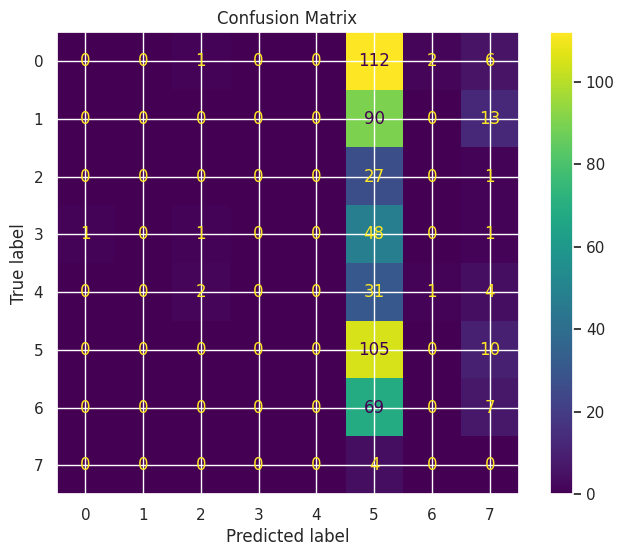

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_50_25_alpha1e-6_adam
------------------------------
TRAIN
Accuracy: 0.8439
Precision: 0.8496
Recall: 0.8439
F1: 0.8434
Kappa: 0.8104
Error Rate: 0.1561

TEST
Accuracy: 0.2090
Precision: 0.1210
Recall: 0.2090
F1: 0.0860
Kappa: 0.0034
Error Rate: 0.7910
Gap (overfitting): 0.6349

CV
Mean: 0.5412
Std: 0.1331
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-06, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50, 25), 'learning_rate': 'constant', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



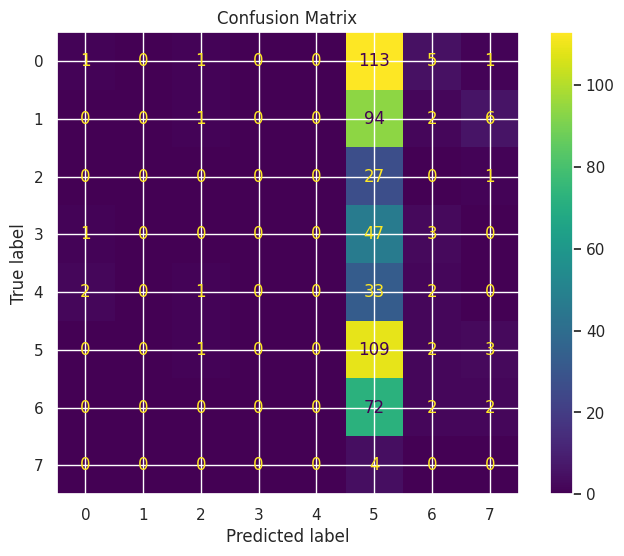

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_50_25_alpha1e-5_adam
------------------------------
TRAIN
Accuracy: 0.8463
Precision: 0.8526
Recall: 0.8463
F1: 0.8458
Kappa: 0.8132
Error Rate: 0.1537

TEST
Accuracy: 0.0485
Precision: 0.1870
Recall: 0.0485
F1: 0.0536
Kappa: 0.0087
Error Rate: 0.9515
Gap (overfitting): 0.7978

CV
Mean: 0.5350
Std: 0.1312
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50, 25), 'learning_rate': 'constant', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



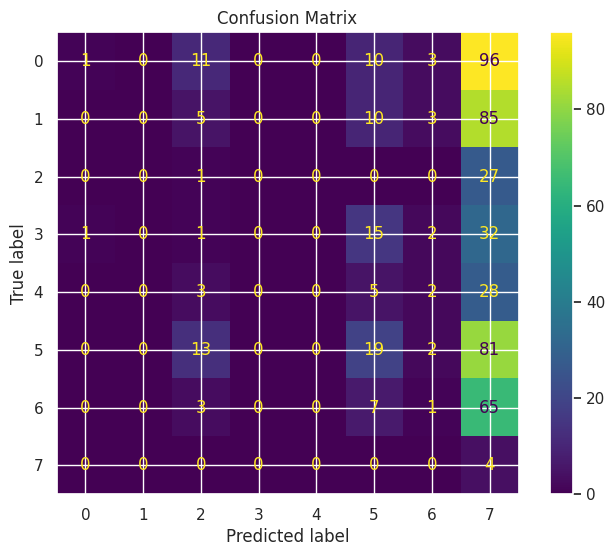

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_30_alpha1e-4_sgd
------------------------------
TRAIN
Accuracy: 0.4524
Precision: 0.4667
Recall: 0.4524
F1: 0.4266
Kappa: 0.3249
Error Rate: 0.5476

TEST
Accuracy: 0.2388
Precision: 0.2168
Recall: 0.2388
F1: 0.1834
Kappa: 0.0792
Error Rate: 0.7612
Gap (overfitting): 0.2136

CV
Mean: 0.2325
Std: 0.0383
------------------------------
Model params:
{'activation': 'relu', 'alpha': 0.0001, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'adaptive', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'sgd', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



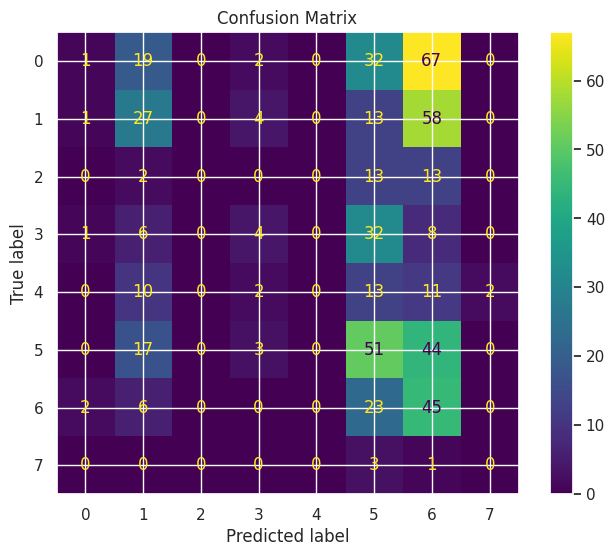

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_30_alpha1e-6_sgd
------------------------------
TRAIN
Accuracy: 0.4524
Precision: 0.4667
Recall: 0.4524
F1: 0.4266
Kappa: 0.3249
Error Rate: 0.5476

TEST
Accuracy: 0.2388
Precision: 0.2168
Recall: 0.2388
F1: 0.1834
Kappa: 0.0792
Error Rate: 0.7612
Gap (overfitting): 0.2136

CV
Mean: 0.2325
Std: 0.0383
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-06, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'adaptive', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'sgd', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



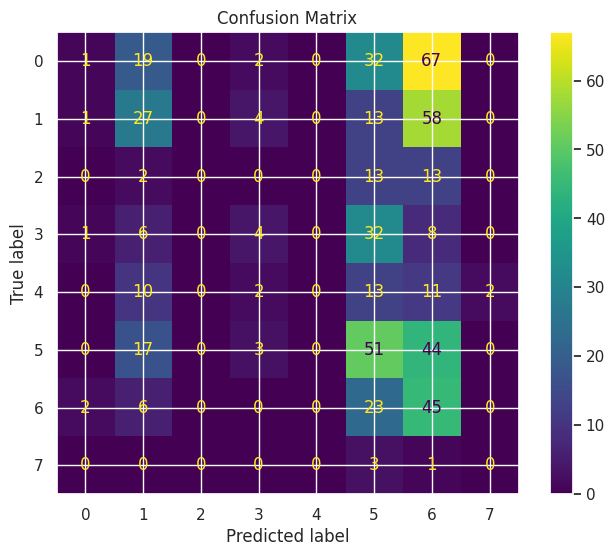

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_30_alpha1e-5_sgd
------------------------------
TRAIN
Accuracy: 0.4524
Precision: 0.4667
Recall: 0.4524
F1: 0.4266
Kappa: 0.3249
Error Rate: 0.5476

TEST
Accuracy: 0.2388
Precision: 0.2168
Recall: 0.2388
F1: 0.1834
Kappa: 0.0792
Error Rate: 0.7612
Gap (overfitting): 0.2136

CV
Mean: 0.2325
Std: 0.0383
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'adaptive', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'sgd', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



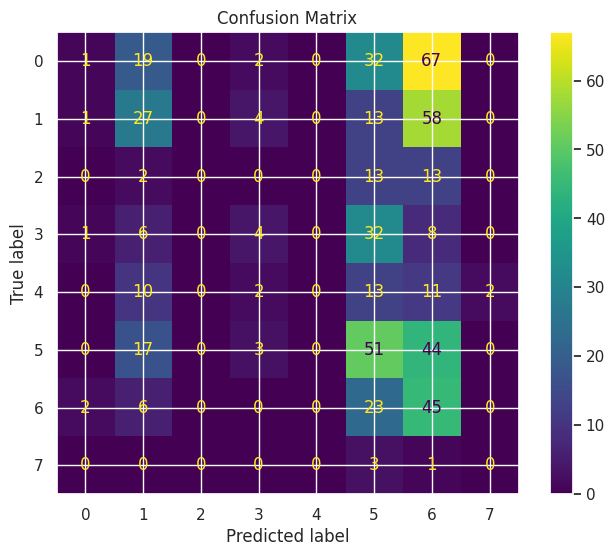

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_50_alpha1e-4_sgd
------------------------------
TRAIN
Accuracy: 0.4508
Precision: 0.4987
Recall: 0.4508
F1: 0.4269
Kappa: 0.3229
Error Rate: 0.5492

TEST
Accuracy: 0.1325
Precision: 0.2057
Recall: 0.1325
F1: 0.1180
Kappa: 0.0201
Error Rate: 0.8675
Gap (overfitting): 0.3183

CV
Mean: 0.2908
Std: 0.0394
------------------------------
Model params:
{'activation': 'relu', 'alpha': 0.0001, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50,), 'learning_rate': 'adaptive', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'sgd', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



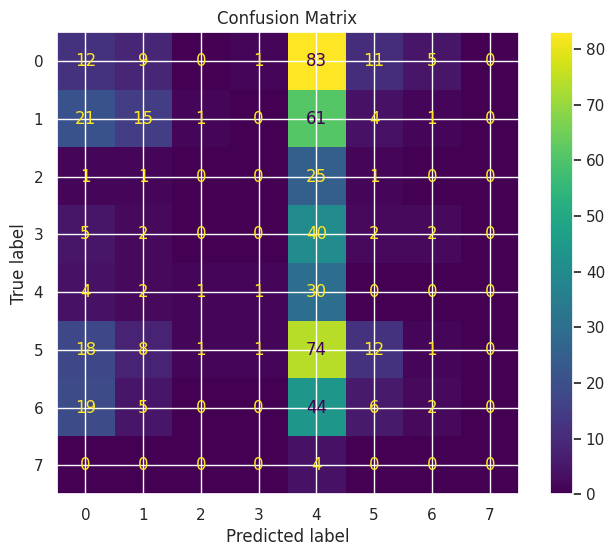

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_50_alpha1e-6_sgd
------------------------------
TRAIN
Accuracy: 0.4508
Precision: 0.4987
Recall: 0.4508
F1: 0.4269
Kappa: 0.3229
Error Rate: 0.5492

TEST
Accuracy: 0.1325
Precision: 0.2057
Recall: 0.1325
F1: 0.1180
Kappa: 0.0201
Error Rate: 0.8675
Gap (overfitting): 0.3183

CV
Mean: 0.2913
Std: 0.0415
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-06, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50,), 'learning_rate': 'adaptive', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'sgd', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



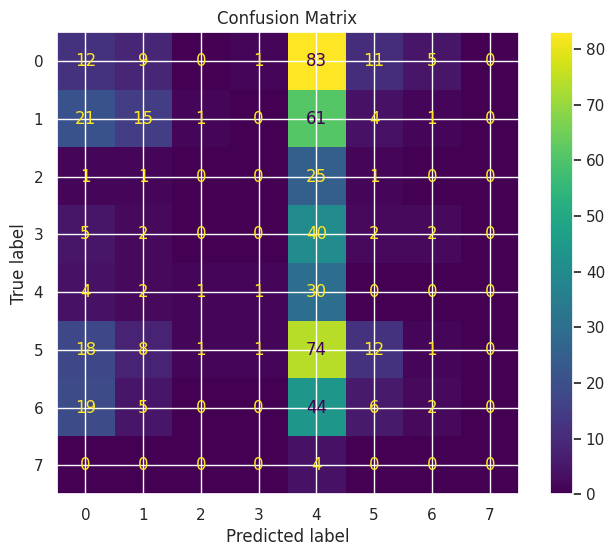

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_50_alpha1e-5_sgd
------------------------------
TRAIN
Accuracy: 0.4508
Precision: 0.4987
Recall: 0.4508
F1: 0.4269
Kappa: 0.3229
Error Rate: 0.5492

TEST
Accuracy: 0.1325
Precision: 0.2057
Recall: 0.1325
F1: 0.1180
Kappa: 0.0201
Error Rate: 0.8675
Gap (overfitting): 0.3183

CV
Mean: 0.2930
Std: 0.0412
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50,), 'learning_rate': 'adaptive', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'sgd', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



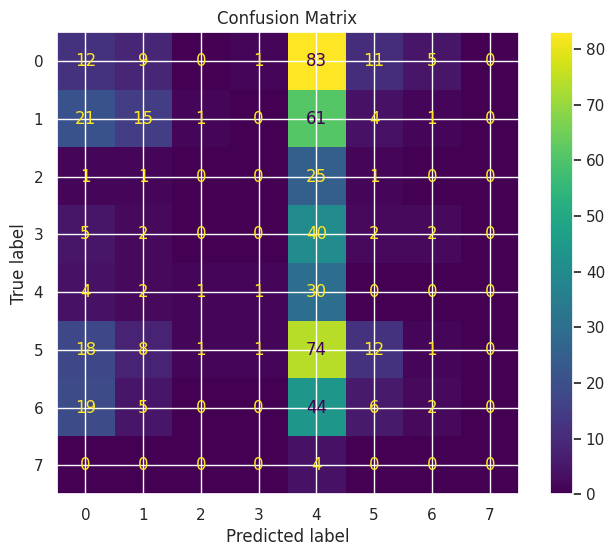

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_50_25_alpha1e-4_sgd
------------------------------
TRAIN
Accuracy: 0.4700
Precision: 0.4867
Recall: 0.4700
F1: 0.4469
Kappa: 0.3461
Error Rate: 0.5300

TEST
Accuracy: 0.1213
Precision: 0.1748
Recall: 0.1213
F1: 0.0997
Kappa: 0.0170
Error Rate: 0.8787
Gap (overfitting): 0.3487

CV
Mean: 0.2146
Std: 0.0042
------------------------------
Model params:
{'activation': 'relu', 'alpha': 0.0001, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50, 25), 'learning_rate': 'adaptive', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'sgd', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



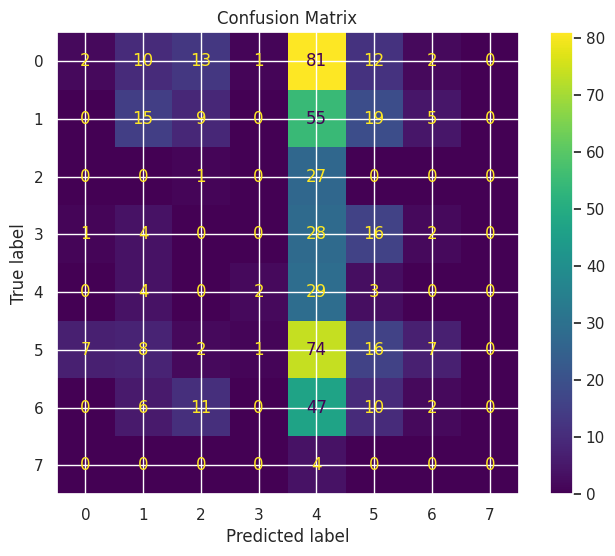

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_50_25_alpha1e-6_sgd
------------------------------
TRAIN
Accuracy: 0.4700
Precision: 0.4867
Recall: 0.4700
F1: 0.4469
Kappa: 0.3461
Error Rate: 0.5300

TEST
Accuracy: 0.1213
Precision: 0.1748
Recall: 0.1213
F1: 0.0997
Kappa: 0.0170
Error Rate: 0.8787
Gap (overfitting): 0.3487

CV
Mean: 0.2146
Std: 0.0042
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-06, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50, 25), 'learning_rate': 'adaptive', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'sgd', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



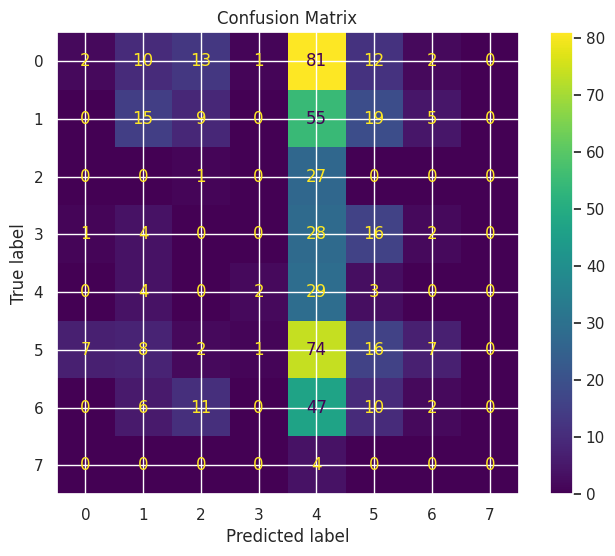

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_50_25_alpha1e-5_sgd
------------------------------
TRAIN
Accuracy: 0.4700
Precision: 0.4867
Recall: 0.4700
F1: 0.4469
Kappa: 0.3461
Error Rate: 0.5300

TEST
Accuracy: 0.1213
Precision: 0.1748
Recall: 0.1213
F1: 0.0997
Kappa: 0.0170
Error Rate: 0.8787
Gap (overfitting): 0.3487

CV
Mean: 0.2146
Std: 0.0042
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50, 25), 'learning_rate': 'adaptive', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'sgd', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



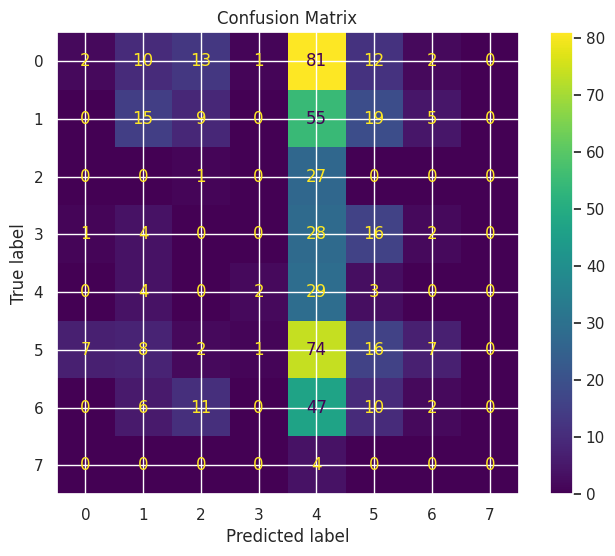

In [ ]:
models_f4 = {}

models_f4['F3_30_alpha1e-4_adam'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-4,
    random_state=42,
    max_iter=500
)

models_f4['F3_30_alpha1e-6_adam'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-6,
    random_state=42,
    max_iter=500
)

models_f4['F3_30_alpha1e-5_adam'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-5,
    random_state=42,
    max_iter=500
)

models_f4['F3_50_alpha1e-4_adam'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(50,),
    alpha=1e-4,
    random_state=42,
    max_iter=500
)

models_f4['F3_50_alpha1e-6_adam'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(50,),
    alpha=1e-6,
    random_state=42,
    max_iter=500
)

models_f4['F3_50_alpha1e-5_adam'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(50,),
    alpha=1e-5,
    random_state=42,
    max_iter=500
)

models_f4['F3_50_25_alpha1e-4_adam'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(50, 25),
    alpha=1e-4,
    random_state=42,
    max_iter=500
)

models_f4['F3_50_25_alpha1e-6_adam'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(50, 25),
    alpha=1e-6,
    random_state=42,
    max_iter=500
)

models_f4['F3_50_25_alpha1e-5_adam'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(50, 25),
    alpha=1e-5,
    random_state=42,
    max_iter=500
)

models_f4['F3_30_alpha1e-4_sgd'] = MLPClassifier(
    solver='sgd',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-4,
    momentum=0.9,
    learning_rate='adaptive',
    random_state=42,
    max_iter=500
)

models_f4['F3_30_alpha1e-6_sgd'] = MLPClassifier(
    solver='sgd',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-6,
    momentum=0.9,
    learning_rate='adaptive',
    random_state=42,
    max_iter=500
)

models_f4['F3_30_alpha1e-5_sgd'] = MLPClassifier(
    solver='sgd',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-5,
    momentum=0.9,
    learning_rate='adaptive',
    random_state=42,
    max_iter=500
)

models_f4['F3_50_alpha1e-4_sgd'] = MLPClassifier(
    solver='sgd',
    activation='relu',
    hidden_layer_sizes=(50,),
    alpha=1e-4,
    momentum=0.9,
    learning_rate='adaptive',
    random_state=42,
    max_iter=500
)

models_f4['F3_50_alpha1e-6_sgd'] = MLPClassifier(
    solver='sgd',
    activation='relu',
    hidden_layer_sizes=(50,),
    alpha=1e-6,
    momentum=0.9,
    learning_rate='adaptive',
    random_state=42,
    max_iter=500
)

models_f4['F3_50_alpha1e-5_sgd'] = MLPClassifier(
    solver='sgd',
    activation='relu',
    hidden_layer_sizes=(50,),
    alpha=1e-5,
    momentum=0.9,
    learning_rate='adaptive',
    random_state=42,
    max_iter=500
)

models_f4['F3_50_25_alpha1e-4_sgd'] = MLPClassifier(
    solver='sgd',
    activation='relu',
    hidden_layer_sizes=(50, 25),
    alpha=1e-4,
    momentum=0.9,
    learning_rate='adaptive',
    random_state=42,
    max_iter=500
)

models_f4['F3_50_25_alpha1e-6_sgd'] = MLPClassifier(
    solver='sgd',
    activation='relu',
    hidden_layer_sizes=(50, 25),
    alpha=1e-6,
    momentum=0.9,
    learning_rate='adaptive',
    random_state=42,
    max_iter=500
)

models_f4['F3_50_25_alpha1e-5_sgd'] = MLPClassifier(
    solver='sgd',
    activation='relu',
    hidden_layer_sizes=(50, 25),
    alpha=1e-5,
    momentum=0.9,
    learning_rate='adaptive',
    random_state=42,
    max_iter=500
)

main(models_f4, "fase_4")

# Validar melhor MLP
#  MUDA SEMNTE, MUDA NUMERO DE TIRACOES - VER ESTABILIDADE
# Escerver processo pra fazer igual para todos
# Fazer outra NN
# Organizr codigo

In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, cohen_kappa_score
from sklearn.model_selection import cross_val_score
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.preprocessing import LabelEncoder

# LSTM

In [17]:
class LSTMClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self,
                 hidden_size=32,
                 num_layers=1,
                 dropout=0.2,
                 fc_hidden_layers=(16,),
                 input_size=None,
                 output_size=8,
                 solver='adam',
                 learning_rate=0.001,
                 momentum=0.9,
                 epochs=100,
                 batch_size=32,
                 random_state=42,
                 device='cpu'):

        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.dropout = dropout
        self.fc_hidden_layers = fc_hidden_layers
        self.input_size = input_size
        self.output_size = output_size
        self.solver = solver
        self.learning_rate = learning_rate
        self.momentum = momentum
        self.epochs = epochs
        self.batch_size = batch_size
        self.random_state = random_state
        self.device = device if torch.cuda.is_available() else 'cpu'

        self.model = None
        self.optimizer = None
        self.criterion = None
        self.label_encoder = LabelEncoder()
        self.scaler = MinMaxScaler()

    def _build_model(self):
        class LSTMModel(nn.Module):
            def __init__(self, input_size, hidden_size, num_layers, dropout, fc_hiddens, output_size):
                super(LSTMModel, self).__init__()

                # LSTM: input_size = número de features
                self.lstm = nn.LSTM(
                    input_size=input_size,
                    hidden_size=hidden_size,
                    num_layers=num_layers,
                    batch_first=True,
                    dropout=dropout if num_layers > 1 else 0
                )

                self.dropout = nn.Dropout(dropout)

                # Camadas fully connected
                fc_layers = []
                prev_size = hidden_size

                for hidden in fc_hiddens:
                    fc_layers.append(nn.Linear(prev_size, hidden))
                    fc_layers.append(nn.ReLU())
                    fc_layers.append(nn.Dropout(dropout))
                    prev_size = hidden

                fc_layers.append(nn.Linear(prev_size, output_size))
                self.fc = nn.Sequential(*fc_layers)

            def forward(self, x):
                # x já deve ter shape (batch, seq_len, features)
                # NÃO fazer unsqueeze aqui!
                lstm_out, (hidden, cell) = self.lstm(x)
                last_hidden = hidden[-1]
                out = self.dropout(last_hidden)
                out = self.fc(out)
                return out

        return LSTMModel(
            input_size=self.input_size,
            hidden_size=self.hidden_size,
            num_layers=self.num_layers,
            dropout=self.dropout,
            fc_hiddens=self.fc_hidden_layers,
            output_size=self.output_size
        )

    def fit(self, X, y):
        # Converter DataFrame para numpy se necessário
        if isinstance(X, pd.DataFrame):
            X = X.values
        if isinstance(y, (pd.Series, pd.DataFrame)):
            y = y.values

        # Salvar input_size
        if self.input_size is None:
            self.input_size = X.shape[1]

        # Escalar os dados
        X_scaled = self.scaler.fit_transform(X)

        # Codificar labels
        y_encoded = self.label_encoder.fit_transform(y)
        self.output_size = len(self.label_encoder.classes_)

        # Construir modelo
        torch.manual_seed(self.random_state)
        self.model = self._build_model().to(self.device)

        # Escolher o otimizador
        if self.solver == 'adam':
            self.optimizer = optim.Adam(self.model.parameters(), lr=self.learning_rate)
        elif self.solver == 'sgd':
            self.optimizer = optim.SGD(self.model.parameters(), lr=self.learning_rate, momentum=self.momentum)
        elif self.solver == 'rmsprop':
            self.optimizer = optim.RMSprop(self.model.parameters(), lr=self.learning_rate)
        else:
            self.optimizer = optim.Adam(self.model.parameters(), lr=self.learning_rate)

        self.criterion = nn.CrossEntropyLoss()

        # CORRIGIDO: Adicionar dimensão de sequência (seq_len=1)
        # Shape original: (batch, features)
        # Shape para LSTM: (batch, seq_len=1, features)
        X_tensor = torch.FloatTensor(X_scaled).unsqueeze(1).to(self.device)
        y_tensor = torch.LongTensor(y_encoded).to(self.device)

        dataset = TensorDataset(X_tensor, y_tensor)
        dataloader = DataLoader(dataset, batch_size=self.batch_size, shuffle=True)

        # Treinamento
        self.model.train()
        for epoch in range(self.epochs):
            total_loss = 0
            for batch_X, batch_y in dataloader:
                self.optimizer.zero_grad()
                outputs = self.model(batch_X)  # batch_X já tem shape (batch, 1, features)
                loss = self.criterion(outputs, batch_y)
                loss.backward()
                self.optimizer.step()
                total_loss += loss.item()

            if (epoch + 1) % 20 == 0:
                print(f"Epoch {epoch+1}/{self.epochs}, Loss: {total_loss/len(dataloader):.4f}")

        return self

    def predict(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).unsqueeze(1).to(self.device)

        with torch.no_grad():
            outputs = self.model(X_tensor)
            _, predicted = torch.max(outputs, 1)

        return self.label_encoder.inverse_transform(predicted.cpu().numpy())

    def predict_proba(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).unsqueeze(1).to(self.device)

        with torch.no_grad():
            outputs = torch.softmax(self.model(X_tensor), dim=1)

        return outputs.cpu().numpy()

    def get_params(self, deep=True):
        return {
            'hidden_size': self.hidden_size,
            'num_layers': self.num_layers,
            'dropout': self.dropout,
            'fc_hidden_layers': self.fc_hidden_layers,
            'input_size': self.input_size,
            'output_size': self.output_size,
            'solver': self.solver,
            'learning_rate': self.learning_rate,
            'momentum': self.momentum,
            'epochs': self.epochs,
            'batch_size': self.batch_size,
            'random_state': self.random_state
        }

    def set_params(self, **params):
        for key, value in params.items():
            setattr(self, key, value)
        return self

/tmp/ipykernel_21399/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)


Epoch 20/500, Loss: 1.5419
Epoch 40/500, Loss: 1.3695
Epoch 60/500, Loss: 1.2811
Epoch 80/500, Loss: 1.1911
Epoch 100/500, Loss: 1.0826
Epoch 120/500, Loss: 1.0056
Epoch 140/500, Loss: 0.9548
Epoch 160/500, Loss: 0.8423
Epoch 180/500, Loss: 0.8471
Epoch 200/500, Loss: 0.7265
Epoch 220/500, Loss: 0.6633
Epoch 240/500, Loss: 0.6060
Epoch 260/500, Loss: 0.5621
Epoch 280/500, Loss: 0.5226
Epoch 300/500, Loss: 0.4902
Epoch 320/500, Loss: 0.4512
Epoch 340/500, Loss: 0.4195
Epoch 360/500, Loss: 0.4322
Epoch 380/500, Loss: 0.3561
Epoch 400/500, Loss: 0.3448
Epoch 420/500, Loss: 0.3102
Epoch 440/500, Loss: 0.2863
Epoch 460/500, Loss: 0.2947
Epoch 480/500, Loss: 0.2541
Epoch 500/500, Loss: 0.2340
Epoch 20/500, Loss: 1.4617
Epoch 40/500, Loss: 1.2922
Epoch 60/500, Loss: 1.1568
Epoch 80/500, Loss: 1.0317
Epoch 100/500, Loss: 0.9097
Epoch 120/500, Loss: 0.8040
Epoch 140/500, Loss: 0.7117
Epoch 160/500, Loss: 0.6292
Epoch 180/500, Loss: 0.5583
Epoch 200/500, Loss: 0.4975
Epoch 220/500, Loss: 0.4469


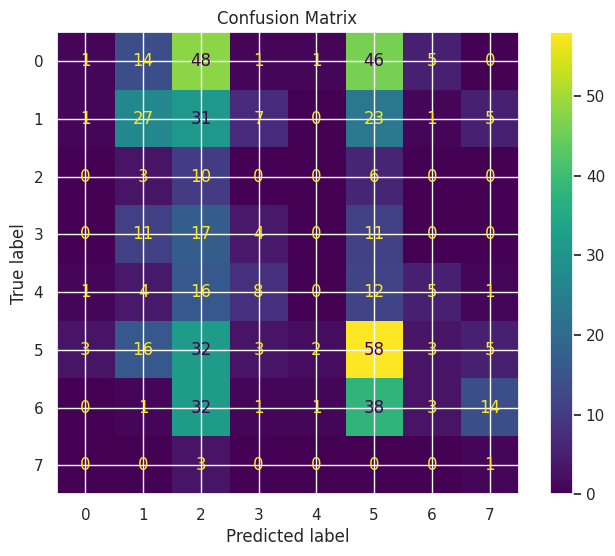

Epoch 20/500, Loss: 1.5480
Epoch 40/500, Loss: 1.3650
Epoch 60/500, Loss: 1.2774
Epoch 80/500, Loss: 1.1932
Epoch 100/500, Loss: 1.0930
Epoch 120/500, Loss: 1.0298
Epoch 140/500, Loss: 0.9939
Epoch 160/500, Loss: 0.8718
Epoch 180/500, Loss: 0.8888
Epoch 200/500, Loss: 0.7577
Epoch 220/500, Loss: 0.6988
Epoch 240/500, Loss: 0.6404
Epoch 260/500, Loss: 0.6013
Epoch 280/500, Loss: 0.5555
Epoch 300/500, Loss: 0.5261
Epoch 320/500, Loss: 0.4846
Epoch 340/500, Loss: 0.4539
Epoch 360/500, Loss: 0.4798
Epoch 380/500, Loss: 0.3881
Epoch 400/500, Loss: 0.3779
Epoch 420/500, Loss: 0.3501
Epoch 440/500, Loss: 0.3212
Epoch 460/500, Loss: 0.3315
Epoch 480/500, Loss: 0.2851
Epoch 500/500, Loss: 0.2754
Epoch 20/500, Loss: 1.4607
Epoch 40/500, Loss: 1.2759
Epoch 60/500, Loss: 1.1335
Epoch 80/500, Loss: 1.0124
Epoch 100/500, Loss: 0.8965
Epoch 120/500, Loss: 0.7935
Epoch 140/500, Loss: 0.7085
Epoch 160/500, Loss: 0.6311
Epoch 180/500, Loss: 0.5660
Epoch 200/500, Loss: 0.5109
Epoch 220/500, Loss: 0.4651


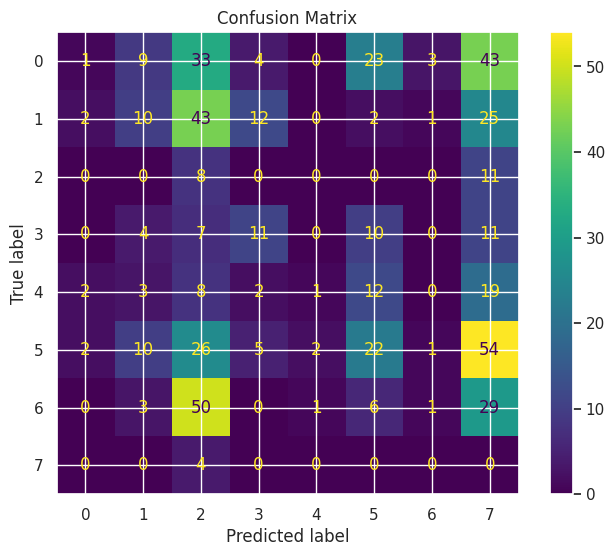

Epoch 20/500, Loss: 1.9252
Epoch 40/500, Loss: 1.8825
Epoch 60/500, Loss: 1.8803
Epoch 80/500, Loss: 1.8651
Epoch 100/500, Loss: 1.8751
Epoch 120/500, Loss: 1.8564
Epoch 140/500, Loss: 1.8662
Epoch 160/500, Loss: 1.8435
Epoch 180/500, Loss: 1.8494
Epoch 200/500, Loss: 1.8251
Epoch 220/500, Loss: 1.8155
Epoch 240/500, Loss: 1.7993
Epoch 260/500, Loss: 1.7700
Epoch 280/500, Loss: 1.7427
Epoch 300/500, Loss: 1.7155
Epoch 320/500, Loss: 1.6744
Epoch 340/500, Loss: 1.6471
Epoch 360/500, Loss: 1.6558
Epoch 380/500, Loss: 1.5793
Epoch 400/500, Loss: 1.5749
Epoch 420/500, Loss: 1.5767
Epoch 440/500, Loss: 1.5752
Epoch 460/500, Loss: 1.5015
Epoch 480/500, Loss: 1.5032
Epoch 500/500, Loss: 1.4877


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 20/500, Loss: 1.9065
Epoch 40/500, Loss: 1.8831
Epoch 60/500, Loss: 1.8722
Epoch 80/500, Loss: 1.8648
Epoch 100/500, Loss: 1.8580
Epoch 120/500, Loss: 1.8522
Epoch 140/500, Loss: 1.8450
Epoch 160/500, Loss: 1.8366
Epoch 180/500, Loss: 1.8231
Epoch 200/500, Loss: 1.8065
Epoch 220/500, Loss: 1.7874
Epoch 240/500, Loss: 1.7541
Epoch 260/500, Loss: 1.7199
Epoch 280/500, Loss: 1.6814
Epoch 300/500, Loss: 1.6485
Epoch 320/500, Loss: 1.6185
Epoch 340/500, Loss: 1.5903
Epoch 360/500, Loss: 1.5657
Epoch 380/500, Loss: 1.5449
Epoch 400/500, Loss: 1.5197
Epoch 420/500, Loss: 1.5031
Epoch 440/500, Loss: 1.4851
Epoch 460/500, Loss: 1.4652
Epoch 480/500, Loss: 1.4484
Epoch 500/500, Loss: 1.4342
Epoch 20/500, Loss: 1.9047
Epoch 40/500, Loss: 1.8808
Epoch 60/500, Loss: 1.8697
Epoch 80/500, Loss: 1.8629
Epoch 100/500, Loss: 1.8566
Epoch 120/500, Loss: 1.8510
Epoch 140/500, Loss: 1.8441
Epoch 160/500, Loss: 1.8371
Epoch 180/500, Loss: 1.8234
Epoch 200/500, Loss: 1.8079
Epoch 220/500, Loss: 1.7890


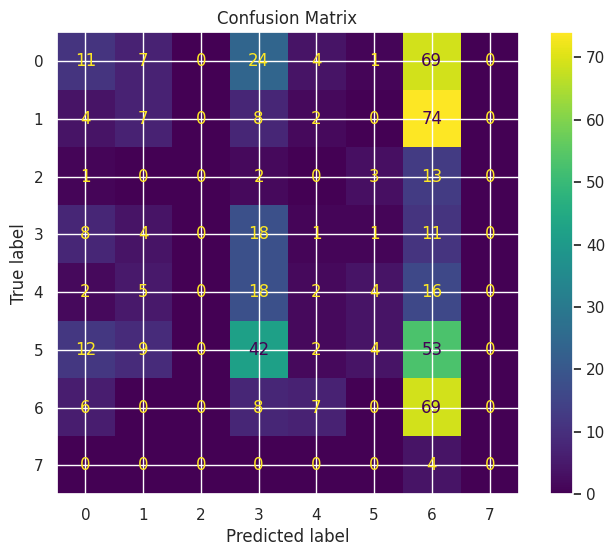

Epoch 20/500, Loss: 1.5480
Epoch 40/500, Loss: 1.3650
Epoch 60/500, Loss: 1.2774
Epoch 80/500, Loss: 1.1932
Epoch 100/500, Loss: 1.0930
Epoch 120/500, Loss: 1.0298
Epoch 140/500, Loss: 0.9939
Epoch 160/500, Loss: 0.8718
Epoch 180/500, Loss: 0.8888
Epoch 200/500, Loss: 0.7577
Epoch 220/500, Loss: 0.6988
Epoch 240/500, Loss: 0.6404
Epoch 260/500, Loss: 0.6013
Epoch 280/500, Loss: 0.5555
Epoch 300/500, Loss: 0.5261
Epoch 320/500, Loss: 0.4846
Epoch 340/500, Loss: 0.4539
Epoch 360/500, Loss: 0.4798
Epoch 380/500, Loss: 0.3881
Epoch 400/500, Loss: 0.3779
Epoch 420/500, Loss: 0.3501
Epoch 440/500, Loss: 0.3212
Epoch 460/500, Loss: 0.3315
Epoch 480/500, Loss: 0.2851
Epoch 500/500, Loss: 0.2754
Epoch 20/500, Loss: 1.4607
Epoch 40/500, Loss: 1.2759
Epoch 60/500, Loss: 1.1335
Epoch 80/500, Loss: 1.0124
Epoch 100/500, Loss: 0.8965
Epoch 120/500, Loss: 0.7935
Epoch 140/500, Loss: 0.7085
Epoch 160/500, Loss: 0.6311
Epoch 180/500, Loss: 0.5660
Epoch 200/500, Loss: 0.5109
Epoch 220/500, Loss: 0.4651


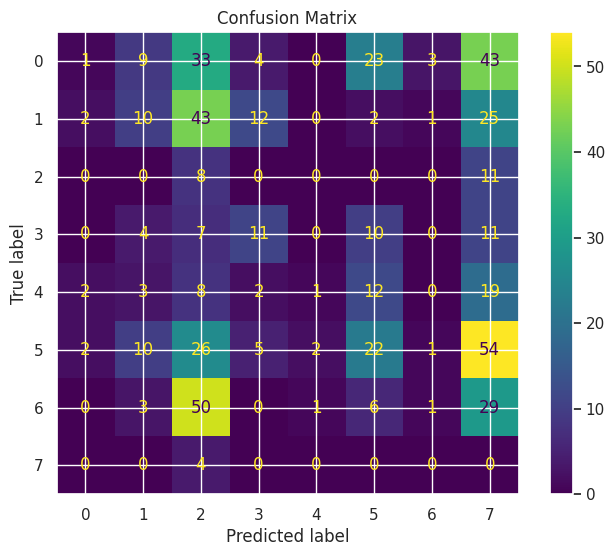

Epoch 20/500, Loss: 1.9234
Epoch 40/500, Loss: 1.8475
Epoch 60/500, Loss: 1.8103
Epoch 80/500, Loss: 1.7541
Epoch 100/500, Loss: 1.7012
Epoch 120/500, Loss: 1.6581
Epoch 140/500, Loss: 1.6426
Epoch 160/500, Loss: 1.5929
Epoch 180/500, Loss: 1.6112
Epoch 200/500, Loss: 1.5428
Epoch 220/500, Loss: 1.5176
Epoch 240/500, Loss: 1.5074
Epoch 260/500, Loss: 1.4968
Epoch 280/500, Loss: 1.4825
Epoch 300/500, Loss: 1.4657
Epoch 320/500, Loss: 1.4552
Epoch 340/500, Loss: 1.4500
Epoch 360/500, Loss: 1.4793
Epoch 380/500, Loss: 1.3940
Epoch 400/500, Loss: 1.4039
Epoch 420/500, Loss: 1.4181
Epoch 440/500, Loss: 1.4215
Epoch 460/500, Loss: 1.3470
Epoch 480/500, Loss: 1.3529
Epoch 500/500, Loss: 1.3433


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 20/500, Loss: 1.8900
Epoch 40/500, Loss: 1.8265
Epoch 60/500, Loss: 1.7557
Epoch 80/500, Loss: 1.6879
Epoch 100/500, Loss: 1.6304
Epoch 120/500, Loss: 1.5887
Epoch 140/500, Loss: 1.5551
Epoch 160/500, Loss: 1.5261
Epoch 180/500, Loss: 1.4963
Epoch 200/500, Loss: 1.4731
Epoch 220/500, Loss: 1.4533
Epoch 240/500, Loss: 1.4289
Epoch 260/500, Loss: 1.4097
Epoch 280/500, Loss: 1.3886
Epoch 300/500, Loss: 1.3714
Epoch 320/500, Loss: 1.3558
Epoch 340/500, Loss: 1.3377
Epoch 360/500, Loss: 1.3200
Epoch 380/500, Loss: 1.3057
Epoch 400/500, Loss: 1.2875
Epoch 420/500, Loss: 1.2745
Epoch 440/500, Loss: 1.2619
Epoch 460/500, Loss: 1.2467
Epoch 480/500, Loss: 1.2315
Epoch 500/500, Loss: 1.2192
Epoch 20/500, Loss: 1.8882
Epoch 40/500, Loss: 1.8226
Epoch 60/500, Loss: 1.7531
Epoch 80/500, Loss: 1.6901
Epoch 100/500, Loss: 1.6369
Epoch 120/500, Loss: 1.5996
Epoch 140/500, Loss: 1.5665
Epoch 160/500, Loss: 1.5397
Epoch 180/500, Loss: 1.5106
Epoch 200/500, Loss: 1.4886
Epoch 220/500, Loss: 1.4689


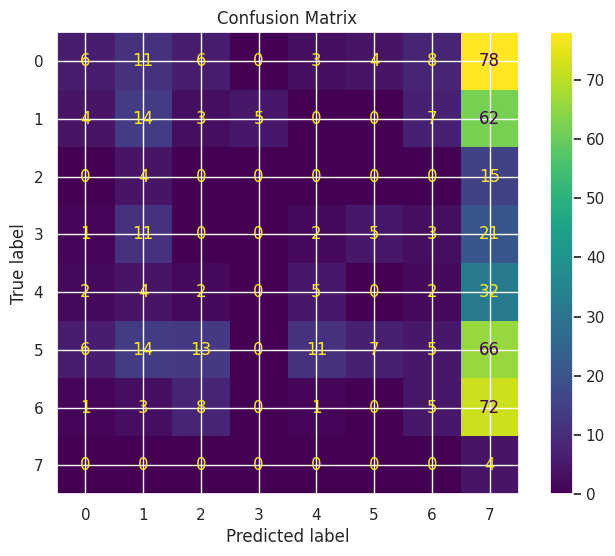

In [19]:
    # Modelos LSTM para testar (similar à Fase 2/3)
models_lstm = {}

# Modelo pequeno - melhor para 119 samples
'''models_lstm['LSTM_tiny'] = LSTMClassifier(
    hidden_size=8,
    num_layers=1,
    dropout=0.3,
    learning_rate=0.0005,
    epochs=50,
    batch_size=16,
    random_state=42
)
# Executar com seus modelos LSTM'''
models_lstm = {}

# ============================================================
# BASE: MLP_lbfgs_30 → LSTM_rmsprop_30
# ============================================================
models_lstm['LSTM_rmsprop_30'] = LSTMClassifier(
    hidden_size=30,
    num_layers=1,
    dropout=0.0,
    fc_hidden_layers=(),
    solver='rmsprop',
    learning_rate=0.001,
    epochs=500,
    batch_size=32,
    random_state=42
)

# ============================================================
# relu + adam → LSTM_adam_30
# ============================================================
models_lstm['LSTM_adam_30'] = LSTMClassifier(
    hidden_size=30,
    num_layers=1,
    dropout=0.0,
    fc_hidden_layers=(),
    solver='adam',
    learning_rate=0.001,
    epochs=500,
    batch_size=32,
    random_state=42
)

# ============================================================
# relu + sgd + momentum → LSTM_sgd_momentum_30
# ============================================================
models_lstm['LSTM_sgd_momentum_30'] = LSTMClassifier(
    hidden_size=30,
    num_layers=1,
    dropout=0.0,
    fc_hidden_layers=(),
    solver='sgd',
    learning_rate=0.001,
    momentum=0.9,
    epochs=500,
    batch_size=32,
    random_state=42
)

# ============================================================
# tanh + adam → LSTM_adam_30 (LSTM já usa tanh internamente)
# ============================================================
models_lstm['LSTM_tanh_adam_30'] = LSTMClassifier(
    hidden_size=30,
    num_layers=1,
    dropout=0.0,
    fc_hidden_layers=(),
    solver='adam',
    learning_rate=0.001,
    epochs=500,
    batch_size=32,
    random_state=42
)

# ============================================================
# relu + adam + learning rate menor → LSTM_adam_lowLR_30
# ============================================================
models_lstm['LSTM_adam_lowLR_30'] = LSTMClassifier(
    hidden_size=30,
    num_layers=1,
    dropout=0.0,
    fc_hidden_layers=(),
    solver='adam',
    learning_rate=0.0001,
    epochs=500,
    batch_size=32,
    random_state=42
)
main(models_lstm, "lstm_experiments")

/tmp/ipykernel_21399/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)


Epoch 20/500, Loss: 1.9035
Epoch 40/500, Loss: 1.8658
Epoch 60/500, Loss: 1.8549
Epoch 80/500, Loss: 1.8492
Epoch 100/500, Loss: 1.8645
Epoch 120/500, Loss: 1.8412
Epoch 140/500, Loss: 1.8570
Epoch 160/500, Loss: 1.8322
Epoch 180/500, Loss: 1.8479
Epoch 200/500, Loss: 1.8245
Epoch 220/500, Loss: 1.8196
Epoch 240/500, Loss: 1.8518
Epoch 260/500, Loss: 1.7965
Epoch 280/500, Loss: 1.7732
Epoch 300/500, Loss: 1.7570
Epoch 320/500, Loss: 1.7438
Epoch 340/500, Loss: 1.7028
Epoch 360/500, Loss: 1.6989
Epoch 380/500, Loss: 1.6455
Epoch 400/500, Loss: 1.6340
Epoch 420/500, Loss: 1.6114
Epoch 440/500, Loss: 1.5723
Epoch 460/500, Loss: 1.5448
Epoch 480/500, Loss: 1.5986
Epoch 500/500, Loss: 1.5221


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 20/500, Loss: 1.8917
Epoch 40/500, Loss: 1.8685
Epoch 60/500, Loss: 1.8576
Epoch 80/500, Loss: 1.8529
Epoch 100/500, Loss: 1.8480
Epoch 120/500, Loss: 1.8431
Epoch 140/500, Loss: 1.8389
Epoch 160/500, Loss: 1.8323
Epoch 180/500, Loss: 1.8257
Epoch 200/500, Loss: 1.8177
Epoch 220/500, Loss: 1.8063
Epoch 240/500, Loss: 1.7876
Epoch 260/500, Loss: 1.7653
Epoch 280/500, Loss: 1.7336
Epoch 300/500, Loss: 1.6983
Epoch 320/500, Loss: 1.6632
Epoch 340/500, Loss: 1.6241
Epoch 360/500, Loss: 1.5944
Epoch 380/500, Loss: 1.5713
Epoch 400/500, Loss: 1.5461
Epoch 420/500, Loss: 1.5255
Epoch 440/500, Loss: 1.5058
Epoch 460/500, Loss: 1.4892
Epoch 480/500, Loss: 1.4711
Epoch 500/500, Loss: 1.4546
Epoch 20/500, Loss: 1.8946
Epoch 40/500, Loss: 1.8717
Epoch 60/500, Loss: 1.8599
Epoch 80/500, Loss: 1.8547
Epoch 100/500, Loss: 1.8502
Epoch 120/500, Loss: 1.8456
Epoch 140/500, Loss: 1.8401
Epoch 160/500, Loss: 1.8335
Epoch 180/500, Loss: 1.8269
Epoch 200/500, Loss: 1.8194
Epoch 220/500, Loss: 1.8087


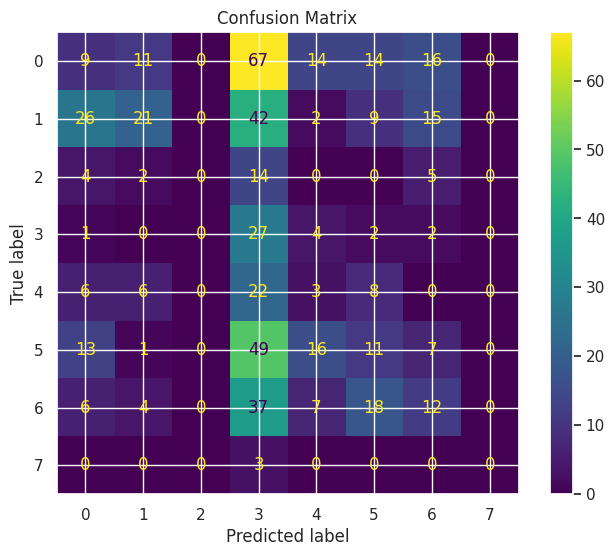

Epoch 20/500, Loss: 1.9013
Epoch 40/500, Loss: 1.8909
Epoch 60/500, Loss: 1.8553
Epoch 80/500, Loss: 1.8492
Epoch 100/500, Loss: 1.8462
Epoch 120/500, Loss: 1.8603
Epoch 140/500, Loss: 1.8366
Epoch 160/500, Loss: 1.8399
Epoch 180/500, Loss: 1.8265
Epoch 200/500, Loss: 1.8260
Epoch 220/500, Loss: 1.8136
Epoch 240/500, Loss: 1.8067
Epoch 260/500, Loss: 1.8084
Epoch 280/500, Loss: 1.7760
Epoch 300/500, Loss: 1.7532
Epoch 320/500, Loss: 1.7295
Epoch 340/500, Loss: 1.7519
Epoch 360/500, Loss: 1.6792
Epoch 380/500, Loss: 1.6759
Epoch 400/500, Loss: 1.6336
Epoch 420/500, Loss: 1.6219
Epoch 440/500, Loss: 1.6007
Epoch 460/500, Loss: 1.5764
Epoch 480/500, Loss: 1.5655
Epoch 500/500, Loss: 1.5491


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 20/500, Loss: 1.8942
Epoch 40/500, Loss: 1.8678
Epoch 60/500, Loss: 1.8575
Epoch 80/500, Loss: 1.8514
Epoch 100/500, Loss: 1.8489
Epoch 120/500, Loss: 1.8434
Epoch 140/500, Loss: 1.8365
Epoch 160/500, Loss: 1.8310
Epoch 180/500, Loss: 1.8227
Epoch 200/500, Loss: 1.8123
Epoch 220/500, Loss: 1.7979
Epoch 240/500, Loss: 1.7822
Epoch 260/500, Loss: 1.7585
Epoch 280/500, Loss: 1.7282
Epoch 300/500, Loss: 1.6976
Epoch 320/500, Loss: 1.6681
Epoch 340/500, Loss: 1.6392
Epoch 360/500, Loss: 1.6143
Epoch 380/500, Loss: 1.5957
Epoch 400/500, Loss: 1.5750
Epoch 420/500, Loss: 1.5566
Epoch 440/500, Loss: 1.5397
Epoch 460/500, Loss: 1.5217
Epoch 480/500, Loss: 1.5071
Epoch 500/500, Loss: 1.4922
Epoch 20/500, Loss: 1.8979
Epoch 40/500, Loss: 1.8708
Epoch 60/500, Loss: 1.8604
Epoch 80/500, Loss: 1.8531
Epoch 100/500, Loss: 1.8503
Epoch 120/500, Loss: 1.8444
Epoch 140/500, Loss: 1.8380
Epoch 160/500, Loss: 1.8330
Epoch 180/500, Loss: 1.8231
Epoch 200/500, Loss: 1.8135
Epoch 220/500, Loss: 1.8013


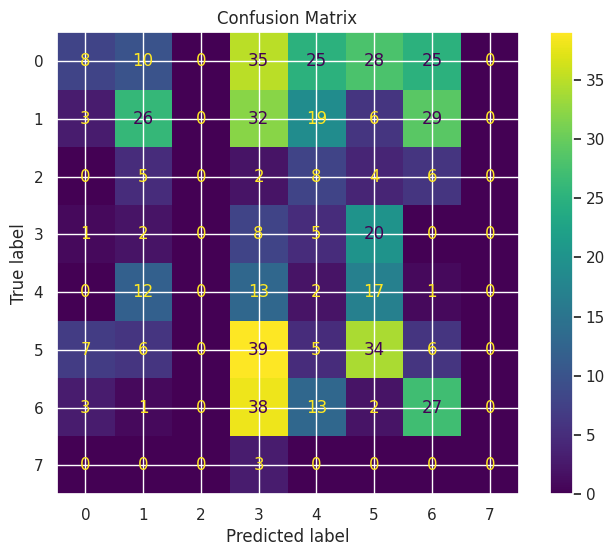

Epoch 20/500, Loss: 1.8965
Epoch 40/500, Loss: 1.8738
Epoch 60/500, Loss: 1.8798
Epoch 80/500, Loss: 1.8543
Epoch 100/500, Loss: 1.8621
Epoch 120/500, Loss: 1.8529
Epoch 140/500, Loss: 1.8622
Epoch 160/500, Loss: 1.8724
Epoch 180/500, Loss: 1.8762
Epoch 200/500, Loss: 1.8726
Epoch 220/500, Loss: 1.8523
Epoch 240/500, Loss: 1.8518
Epoch 260/500, Loss: 1.8548
Epoch 280/500, Loss: 1.8757
Epoch 300/500, Loss: 1.8554
Epoch 320/500, Loss: 1.8527
Epoch 340/500, Loss: 1.8523
Epoch 360/500, Loss: 1.8971
Epoch 380/500, Loss: 1.8756
Epoch 400/500, Loss: 1.8515
Epoch 420/500, Loss: 1.8518
Epoch 440/500, Loss: 1.8524
Epoch 460/500, Loss: 1.8717
Epoch 480/500, Loss: 1.8611
Epoch 500/500, Loss: 1.8508


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 20/500, Loss: 1.8920
Epoch 40/500, Loss: 1.8662
Epoch 60/500, Loss: 1.8602
Epoch 80/500, Loss: 1.8579
Epoch 100/500, Loss: 1.8596
Epoch 120/500, Loss: 1.8591
Epoch 140/500, Loss: 1.8578
Epoch 160/500, Loss: 1.8563
Epoch 180/500, Loss: 1.8566
Epoch 200/500, Loss: 1.8583
Epoch 220/500, Loss: 1.8573
Epoch 240/500, Loss: 1.8576
Epoch 260/500, Loss: 1.8591
Epoch 280/500, Loss: 1.8567
Epoch 300/500, Loss: 1.8563
Epoch 320/500, Loss: 1.8588
Epoch 340/500, Loss: 1.8559
Epoch 360/500, Loss: 1.8563
Epoch 380/500, Loss: 1.8580
Epoch 400/500, Loss: 1.8583
Epoch 420/500, Loss: 1.8562
Epoch 440/500, Loss: 1.8576
Epoch 460/500, Loss: 1.8606
Epoch 480/500, Loss: 1.8571
Epoch 500/500, Loss: 1.8574
Epoch 20/500, Loss: 1.8950
Epoch 40/500, Loss: 1.8677
Epoch 60/500, Loss: 1.8621
Epoch 80/500, Loss: 1.8611
Epoch 100/500, Loss: 1.8610
Epoch 120/500, Loss: 1.8601
Epoch 140/500, Loss: 1.8597
Epoch 160/500, Loss: 1.8588
Epoch 180/500, Loss: 1.8588
Epoch 200/500, Loss: 1.8606
Epoch 220/500, Loss: 1.8602


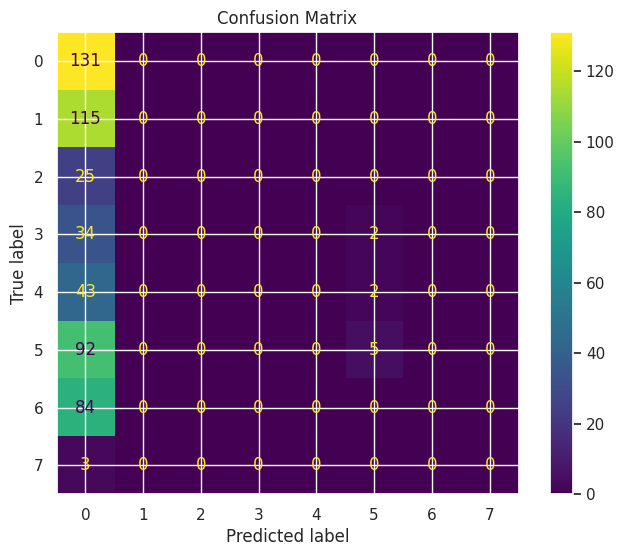

Epoch 20/500, Loss: 1.8999
Epoch 40/500, Loss: 1.8676
Epoch 60/500, Loss: 1.8580
Epoch 80/500, Loss: 1.8601
Epoch 100/500, Loss: 1.8646
Epoch 120/500, Loss: 1.8624
Epoch 140/500, Loss: 1.8389
Epoch 160/500, Loss: 1.8359
Epoch 180/500, Loss: 1.8329
Epoch 200/500, Loss: 1.8234
Epoch 220/500, Loss: 1.8111
Epoch 240/500, Loss: 1.8021
Epoch 260/500, Loss: 1.7930
Epoch 280/500, Loss: 1.8249
Epoch 300/500, Loss: 1.7600
Epoch 320/500, Loss: 1.7579
Epoch 340/500, Loss: 1.7136
Epoch 360/500, Loss: 1.6922
Epoch 380/500, Loss: 1.6720
Epoch 400/500, Loss: 1.6586
Epoch 420/500, Loss: 1.6261
Epoch 440/500, Loss: 1.6249
Epoch 460/500, Loss: 1.5998
Epoch 480/500, Loss: 1.5782
Epoch 500/500, Loss: 1.5735


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 20/500, Loss: 1.8958
Epoch 40/500, Loss: 1.8669
Epoch 60/500, Loss: 1.8587
Epoch 80/500, Loss: 1.8544
Epoch 100/500, Loss: 1.8497
Epoch 120/500, Loss: 1.8445
Epoch 140/500, Loss: 1.8380
Epoch 160/500, Loss: 1.8327
Epoch 180/500, Loss: 1.8243
Epoch 200/500, Loss: 1.8123
Epoch 220/500, Loss: 1.8006
Epoch 240/500, Loss: 1.7827
Epoch 260/500, Loss: 1.7609
Epoch 280/500, Loss: 1.7350
Epoch 300/500, Loss: 1.7033
Epoch 320/500, Loss: 1.6836
Epoch 340/500, Loss: 1.6523
Epoch 360/500, Loss: 1.6370
Epoch 380/500, Loss: 1.6141
Epoch 400/500, Loss: 1.5976
Epoch 420/500, Loss: 1.5715
Epoch 440/500, Loss: 1.5709
Epoch 460/500, Loss: 1.5496
Epoch 480/500, Loss: 1.5245
Epoch 500/500, Loss: 1.5282
Epoch 20/500, Loss: 1.8991
Epoch 40/500, Loss: 1.8692
Epoch 60/500, Loss: 1.8614
Epoch 80/500, Loss: 1.8567
Epoch 100/500, Loss: 1.8506
Epoch 120/500, Loss: 1.8449
Epoch 140/500, Loss: 1.8405
Epoch 160/500, Loss: 1.8340
Epoch 180/500, Loss: 1.8259
Epoch 200/500, Loss: 1.8151
Epoch 220/500, Loss: 1.8031


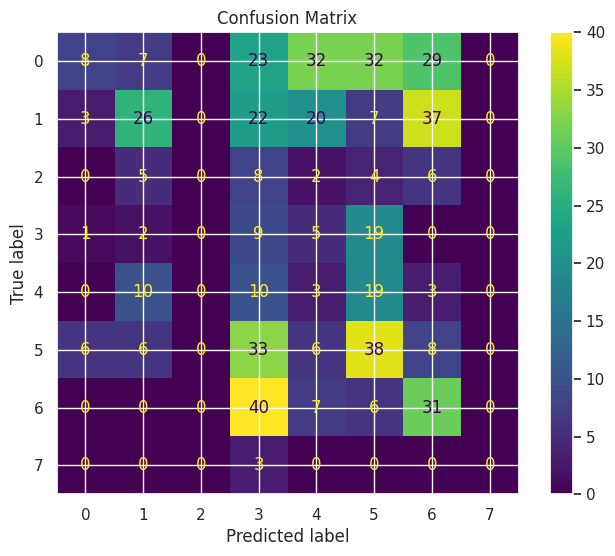

Epoch 20/500, Loss: 1.9000
Epoch 40/500, Loss: 1.8688
Epoch 60/500, Loss: 1.8571
Epoch 80/500, Loss: 1.8612
Epoch 100/500, Loss: 1.8642
Epoch 120/500, Loss: 1.8616
Epoch 140/500, Loss: 1.8384
Epoch 160/500, Loss: 1.8374
Epoch 180/500, Loss: 1.8312
Epoch 200/500, Loss: 1.8239
Epoch 220/500, Loss: 1.8121
Epoch 240/500, Loss: 1.8037
Epoch 260/500, Loss: 1.7958
Epoch 280/500, Loss: 1.8285
Epoch 300/500, Loss: 1.7660
Epoch 320/500, Loss: 1.7660
Epoch 340/500, Loss: 1.7247
Epoch 360/500, Loss: 1.6993
Epoch 380/500, Loss: 1.6811
Epoch 400/500, Loss: 1.6715
Epoch 420/500, Loss: 1.6473
Epoch 440/500, Loss: 1.6428
Epoch 460/500, Loss: 1.6204
Epoch 480/500, Loss: 1.6036
Epoch 500/500, Loss: 1.6086


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 20/500, Loss: 1.8961
Epoch 40/500, Loss: 1.8669
Epoch 60/500, Loss: 1.8601
Epoch 80/500, Loss: 1.8547
Epoch 100/500, Loss: 1.8516
Epoch 120/500, Loss: 1.8454
Epoch 140/500, Loss: 1.8378
Epoch 160/500, Loss: 1.8341
Epoch 180/500, Loss: 1.8266
Epoch 200/500, Loss: 1.8141
Epoch 220/500, Loss: 1.8047
Epoch 240/500, Loss: 1.7869
Epoch 260/500, Loss: 1.7692
Epoch 280/500, Loss: 1.7387
Epoch 300/500, Loss: 1.7159
Epoch 320/500, Loss: 1.6964
Epoch 340/500, Loss: 1.6674
Epoch 360/500, Loss: 1.6516
Epoch 380/500, Loss: 1.6370
Epoch 400/500, Loss: 1.6265
Epoch 420/500, Loss: 1.5988
Epoch 440/500, Loss: 1.5885
Epoch 460/500, Loss: 1.5746
Epoch 480/500, Loss: 1.5542
Epoch 500/500, Loss: 1.5540
Epoch 20/500, Loss: 1.8995
Epoch 40/500, Loss: 1.8686
Epoch 60/500, Loss: 1.8629
Epoch 80/500, Loss: 1.8572
Epoch 100/500, Loss: 1.8506
Epoch 120/500, Loss: 1.8472
Epoch 140/500, Loss: 1.8404
Epoch 160/500, Loss: 1.8357
Epoch 180/500, Loss: 1.8277
Epoch 200/500, Loss: 1.8164
Epoch 220/500, Loss: 1.8067


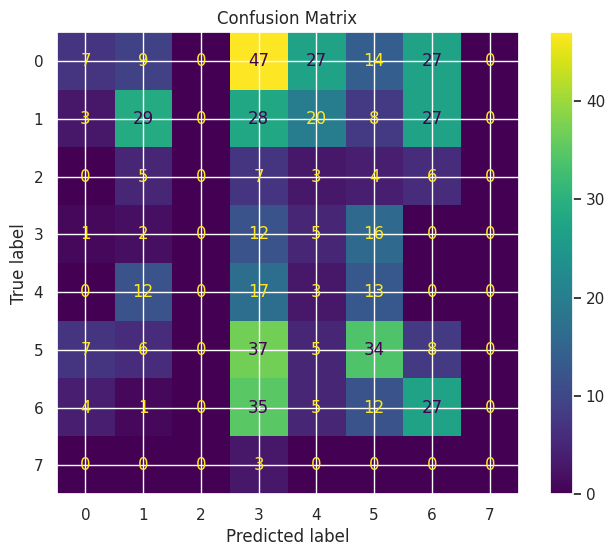

Epoch 20/500, Loss: 1.8688
Epoch 40/500, Loss: 1.8513
Epoch 60/500, Loss: 1.8439
Epoch 80/500, Loss: 1.8428
Epoch 100/500, Loss: 1.8405
Epoch 120/500, Loss: 1.8232
Epoch 140/500, Loss: 1.7790
Epoch 160/500, Loss: 1.7398
Epoch 180/500, Loss: 1.7166
Epoch 200/500, Loss: 1.6475
Epoch 220/500, Loss: 1.6131
Epoch 240/500, Loss: 1.5696
Epoch 260/500, Loss: 1.5596
Epoch 280/500, Loss: 1.5796
Epoch 300/500, Loss: 1.5150
Epoch 320/500, Loss: 1.5040
Epoch 340/500, Loss: 1.4600
Epoch 360/500, Loss: 1.4455
Epoch 380/500, Loss: 1.4169
Epoch 400/500, Loss: 1.4258
Epoch 420/500, Loss: 1.3730
Epoch 440/500, Loss: 1.4036
Epoch 460/500, Loss: 1.3608
Epoch 480/500, Loss: 1.3375
Epoch 500/500, Loss: 1.3136


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 20/500, Loss: 1.8688
Epoch 40/500, Loss: 1.8520
Epoch 60/500, Loss: 1.8434
Epoch 80/500, Loss: 1.8340
Epoch 100/500, Loss: 1.8177
Epoch 120/500, Loss: 1.7875
Epoch 140/500, Loss: 1.7398
Epoch 160/500, Loss: 1.6825
Epoch 180/500, Loss: 1.6338
Epoch 200/500, Loss: 1.5974
Epoch 220/500, Loss: 1.5654
Epoch 240/500, Loss: 1.5392
Epoch 260/500, Loss: 1.5054
Epoch 280/500, Loss: 1.4780
Epoch 300/500, Loss: 1.4469
Epoch 320/500, Loss: 1.4368
Epoch 340/500, Loss: 1.4066
Epoch 360/500, Loss: 1.3974
Epoch 380/500, Loss: 1.3788
Epoch 400/500, Loss: 1.3559
Epoch 420/500, Loss: 1.3313
Epoch 440/500, Loss: 1.3245
Epoch 460/500, Loss: 1.3086
Epoch 480/500, Loss: 1.2701
Epoch 500/500, Loss: 1.2762
Epoch 20/500, Loss: 1.8721
Epoch 40/500, Loss: 1.8535
Epoch 60/500, Loss: 1.8454
Epoch 80/500, Loss: 1.8352
Epoch 100/500, Loss: 1.8183
Epoch 120/500, Loss: 1.7893
Epoch 140/500, Loss: 1.7504
Epoch 160/500, Loss: 1.6949
Epoch 180/500, Loss: 1.6493
Epoch 200/500, Loss: 1.6066
Epoch 220/500, Loss: 1.5757


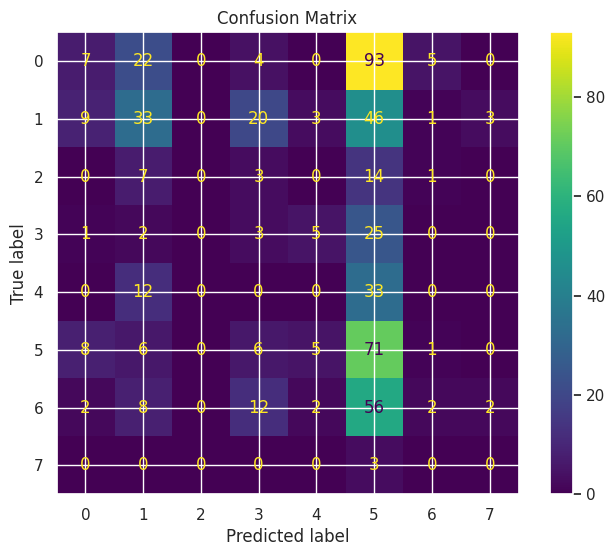

Epoch 20/500, Loss: 1.5339
Epoch 40/500, Loss: 1.4054
Epoch 60/500, Loss: 1.3111
Epoch 80/500, Loss: 1.2222
Epoch 100/500, Loss: 1.1066
Epoch 120/500, Loss: 1.0264
Epoch 140/500, Loss: 0.9824
Epoch 160/500, Loss: 0.8743
Epoch 180/500, Loss: 0.8118
Epoch 200/500, Loss: 0.7254
Epoch 220/500, Loss: 0.6618
Epoch 240/500, Loss: 0.6514
Epoch 260/500, Loss: 0.5698
Epoch 280/500, Loss: 0.5011
Epoch 300/500, Loss: 0.4782
Epoch 320/500, Loss: 0.4331
Epoch 340/500, Loss: 0.4019
Epoch 360/500, Loss: 0.4427
Epoch 380/500, Loss: 0.3513
Epoch 400/500, Loss: 0.3299
Epoch 420/500, Loss: 0.3364
Epoch 440/500, Loss: 0.3238
Epoch 460/500, Loss: 0.2839
Epoch 480/500, Loss: 0.2688
Epoch 500/500, Loss: 0.2550


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 20/500, Loss: 1.4753
Epoch 40/500, Loss: 1.3189
Epoch 60/500, Loss: 1.1982
Epoch 80/500, Loss: 1.0895
Epoch 100/500, Loss: 0.9757
Epoch 120/500, Loss: 0.8722
Epoch 140/500, Loss: 0.7769
Epoch 160/500, Loss: 0.6898
Epoch 180/500, Loss: 0.6110
Epoch 200/500, Loss: 0.5405
Epoch 220/500, Loss: 0.4868
Epoch 240/500, Loss: 0.4404
Epoch 260/500, Loss: 0.4039
Epoch 280/500, Loss: 0.3718
Epoch 300/500, Loss: 0.3461
Epoch 320/500, Loss: 0.3270
Epoch 340/500, Loss: 0.3061
Epoch 360/500, Loss: 0.2898
Epoch 380/500, Loss: 0.2787
Epoch 400/500, Loss: 0.2645
Epoch 420/500, Loss: 0.2510
Epoch 440/500, Loss: 0.2384
Epoch 460/500, Loss: 0.2278
Epoch 480/500, Loss: 0.2198
Epoch 500/500, Loss: 0.2086
Epoch 20/500, Loss: 1.4826
Epoch 40/500, Loss: 1.3153
Epoch 60/500, Loss: 1.1924
Epoch 80/500, Loss: 1.0834
Epoch 100/500, Loss: 0.9705
Epoch 120/500, Loss: 0.8714
Epoch 140/500, Loss: 0.7803
Epoch 160/500, Loss: 0.6950
Epoch 180/500, Loss: 0.6239
Epoch 200/500, Loss: 0.5544
Epoch 220/500, Loss: 0.5021


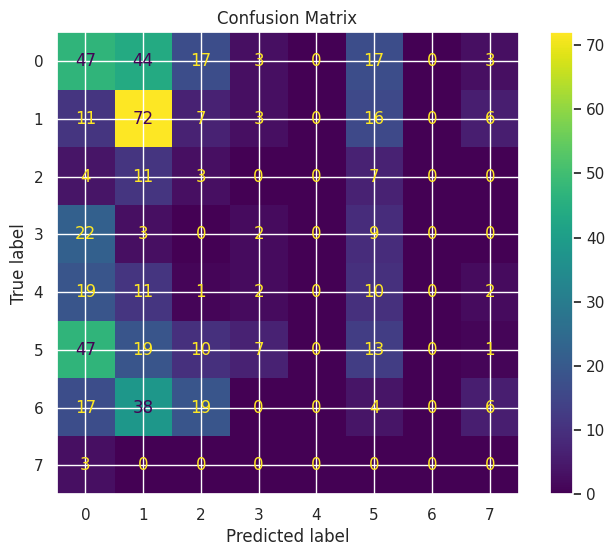

Epoch 20/500, Loss: 1.5185
Epoch 40/500, Loss: 1.3557
Epoch 60/500, Loss: 1.2467
Epoch 80/500, Loss: 1.1541
Epoch 100/500, Loss: 1.0916
Epoch 120/500, Loss: 0.9949
Epoch 140/500, Loss: 0.8663
Epoch 160/500, Loss: 0.7666
Epoch 180/500, Loss: 0.6828
Epoch 200/500, Loss: 0.6021
Epoch 220/500, Loss: 0.5422
Epoch 240/500, Loss: 0.4950
Epoch 260/500, Loss: 0.4410
Epoch 280/500, Loss: 0.4118
Epoch 300/500, Loss: 0.3732
Epoch 320/500, Loss: 0.3363
Epoch 340/500, Loss: 0.3221
Epoch 360/500, Loss: 0.2909
Epoch 380/500, Loss: 0.2952
Epoch 400/500, Loss: 0.2541
Epoch 420/500, Loss: 0.2384
Epoch 440/500, Loss: 0.2271
Epoch 460/500, Loss: 0.2149
Epoch 480/500, Loss: 0.2053
Epoch 500/500, Loss: 0.1967


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 20/500, Loss: 1.4375
Epoch 40/500, Loss: 1.2537
Epoch 60/500, Loss: 1.1306
Epoch 80/500, Loss: 1.0112
Epoch 100/500, Loss: 0.8739
Epoch 120/500, Loss: 0.7477
Epoch 140/500, Loss: 0.6352
Epoch 160/500, Loss: 0.5489
Epoch 180/500, Loss: 0.4754
Epoch 200/500, Loss: 0.4187
Epoch 220/500, Loss: 0.3733
Epoch 240/500, Loss: 0.3356
Epoch 260/500, Loss: 0.3078
Epoch 280/500, Loss: 0.2815
Epoch 300/500, Loss: 0.2646
Epoch 320/500, Loss: 0.2464
Epoch 340/500, Loss: 0.2312
Epoch 360/500, Loss: 0.2216
Epoch 380/500, Loss: 0.2096
Epoch 400/500, Loss: 0.1977
Epoch 420/500, Loss: 0.1892
Epoch 440/500, Loss: 0.1831
Epoch 460/500, Loss: 0.1738
Epoch 480/500, Loss: 0.1674
Epoch 500/500, Loss: 0.1601
Epoch 20/500, Loss: 1.4342
Epoch 40/500, Loss: 1.2476
Epoch 60/500, Loss: 1.1215
Epoch 80/500, Loss: 1.0147
Epoch 100/500, Loss: 0.8932
Epoch 120/500, Loss: 0.7723
Epoch 140/500, Loss: 0.6583
Epoch 160/500, Loss: 0.5689
Epoch 180/500, Loss: 0.4929
Epoch 200/500, Loss: 0.4395
Epoch 220/500, Loss: 0.3948


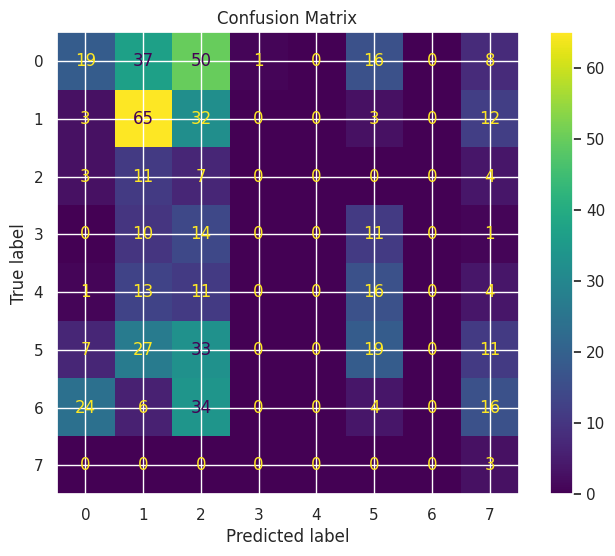

Epoch 20/500, Loss: 1.5407
Epoch 40/500, Loss: 1.3621
Epoch 60/500, Loss: 1.1453
Epoch 80/500, Loss: 0.8802
Epoch 100/500, Loss: 0.6263
Epoch 120/500, Loss: 0.4669
Epoch 140/500, Loss: 0.3256
Epoch 160/500, Loss: 0.2184
Epoch 180/500, Loss: 0.1556
Epoch 200/500, Loss: 0.1093
Epoch 220/500, Loss: 0.0966
Epoch 240/500, Loss: 0.0792
Epoch 260/500, Loss: 0.0691
Epoch 280/500, Loss: 0.0478
Epoch 300/500, Loss: 0.0338
Epoch 320/500, Loss: 0.0451
Epoch 340/500, Loss: 0.0273
Epoch 360/500, Loss: 0.0351
Epoch 380/500, Loss: 0.0194
Epoch 400/500, Loss: 0.0234
Epoch 420/500, Loss: 0.0095
Epoch 440/500, Loss: 0.0157
Epoch 460/500, Loss: 0.0139
Epoch 480/500, Loss: 0.0188
Epoch 500/500, Loss: 0.0313


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 20/500, Loss: 1.4873
Epoch 40/500, Loss: 1.2274
Epoch 60/500, Loss: 0.8708
Epoch 80/500, Loss: 0.5537
Epoch 100/500, Loss: 0.3720
Epoch 120/500, Loss: 0.2674
Epoch 140/500, Loss: 0.1860
Epoch 160/500, Loss: 0.1348
Epoch 180/500, Loss: 0.1222
Epoch 200/500, Loss: 0.0785
Epoch 220/500, Loss: 0.0704
Epoch 240/500, Loss: 0.0583
Epoch 260/500, Loss: 0.0384
Epoch 280/500, Loss: 0.0302
Epoch 300/500, Loss: 0.0263
Epoch 320/500, Loss: 0.0262
Epoch 340/500, Loss: 0.0176
Epoch 360/500, Loss: 0.0115
Epoch 380/500, Loss: 0.0189
Epoch 400/500, Loss: 0.0167
Epoch 420/500, Loss: 0.0130
Epoch 440/500, Loss: 0.0167
Epoch 460/500, Loss: 0.0128
Epoch 480/500, Loss: 0.0035
Epoch 500/500, Loss: 0.0069
Epoch 20/500, Loss: 1.4661
Epoch 40/500, Loss: 1.0952
Epoch 60/500, Loss: 0.7762
Epoch 80/500, Loss: 0.5039
Epoch 100/500, Loss: 0.3371
Epoch 120/500, Loss: 0.2466
Epoch 140/500, Loss: 0.1946
Epoch 160/500, Loss: 0.1552
Epoch 180/500, Loss: 0.1546
Epoch 200/500, Loss: 0.0855
Epoch 220/500, Loss: 0.0667


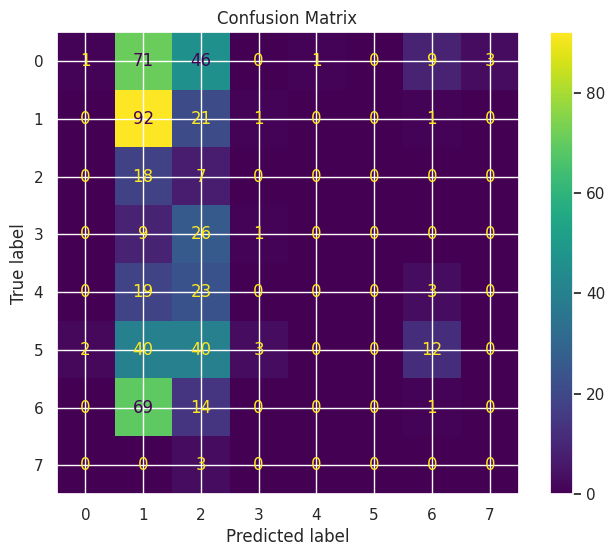

Epoch 20/500, Loss: 1.5559
Epoch 40/500, Loss: 1.4177
Epoch 60/500, Loss: 1.3279
Epoch 80/500, Loss: 1.2630
Epoch 100/500, Loss: 1.2465
Epoch 120/500, Loss: 1.1654
Epoch 140/500, Loss: 1.1194
Epoch 160/500, Loss: 0.9994
Epoch 180/500, Loss: 0.9801
Epoch 200/500, Loss: 0.8794
Epoch 220/500, Loss: 0.8097
Epoch 240/500, Loss: 0.7429
Epoch 260/500, Loss: 0.6893
Epoch 280/500, Loss: 0.6678
Epoch 300/500, Loss: 0.6404
Epoch 320/500, Loss: 0.6048
Epoch 340/500, Loss: 0.5521
Epoch 360/500, Loss: 0.5634
Epoch 380/500, Loss: 0.5186
Epoch 400/500, Loss: 0.5220
Epoch 420/500, Loss: 0.4635
Epoch 440/500, Loss: 0.4605
Epoch 460/500, Loss: 0.4335
Epoch 480/500, Loss: 0.4177
Epoch 500/500, Loss: 0.4068


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 20/500, Loss: 1.5016
Epoch 40/500, Loss: 1.3270
Epoch 60/500, Loss: 1.2342
Epoch 80/500, Loss: 1.1513
Epoch 100/500, Loss: 1.0803
Epoch 120/500, Loss: 0.9885
Epoch 140/500, Loss: 0.9089
Epoch 160/500, Loss: 0.8228
Epoch 180/500, Loss: 0.7653
Epoch 200/500, Loss: 0.7098
Epoch 220/500, Loss: 0.6499
Epoch 240/500, Loss: 0.6065
Epoch 260/500, Loss: 0.5809
Epoch 280/500, Loss: 0.5457
Epoch 300/500, Loss: 0.4891
Epoch 320/500, Loss: 0.4733
Epoch 340/500, Loss: 0.4644
Epoch 360/500, Loss: 0.4579
Epoch 380/500, Loss: 0.4328
Epoch 400/500, Loss: 0.4216
Epoch 420/500, Loss: 0.3945
Epoch 440/500, Loss: 0.3780
Epoch 460/500, Loss: 0.3613
Epoch 480/500, Loss: 0.3484
Epoch 500/500, Loss: 0.3601
Epoch 20/500, Loss: 1.4978
Epoch 40/500, Loss: 1.3146
Epoch 60/500, Loss: 1.2211
Epoch 80/500, Loss: 1.1446
Epoch 100/500, Loss: 1.0676
Epoch 120/500, Loss: 0.9682
Epoch 140/500, Loss: 0.8899
Epoch 160/500, Loss: 0.8205
Epoch 180/500, Loss: 0.7468
Epoch 200/500, Loss: 0.6751
Epoch 220/500, Loss: 0.6361


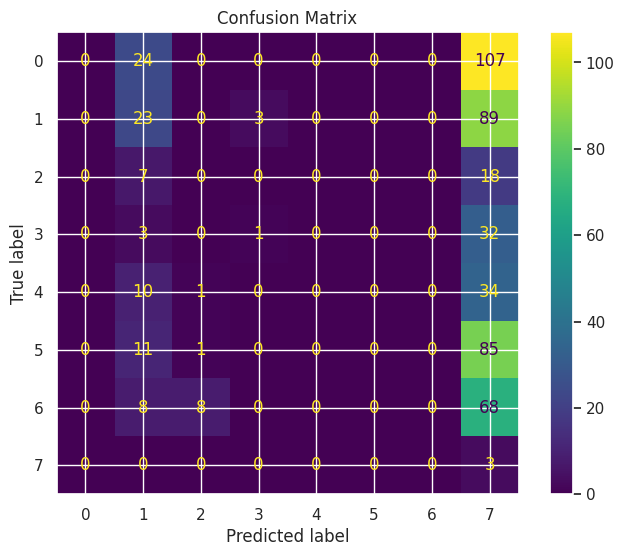

Epoch 20/500, Loss: 1.6024
Epoch 40/500, Loss: 1.4891
Epoch 60/500, Loss: 1.3877
Epoch 80/500, Loss: 1.3366
Epoch 100/500, Loss: 1.3131
Epoch 120/500, Loss: 1.2626
Epoch 140/500, Loss: 1.2404
Epoch 160/500, Loss: 1.1333
Epoch 180/500, Loss: 1.0998
Epoch 200/500, Loss: 1.0309
Epoch 220/500, Loss: 0.9776
Epoch 240/500, Loss: 0.9161
Epoch 260/500, Loss: 0.8793
Epoch 280/500, Loss: 0.8542
Epoch 300/500, Loss: 0.8406
Epoch 320/500, Loss: 0.8044
Epoch 340/500, Loss: 0.7790
Epoch 360/500, Loss: 0.7507
Epoch 380/500, Loss: 0.7273
Epoch 400/500, Loss: 0.6881
Epoch 420/500, Loss: 0.6630
Epoch 440/500, Loss: 0.6855
Epoch 460/500, Loss: 0.6354
Epoch 480/500, Loss: 0.6358
Epoch 500/500, Loss: 0.5837


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 20/500, Loss: 1.5572
Epoch 40/500, Loss: 1.3869
Epoch 60/500, Loss: 1.3213
Epoch 80/500, Loss: 1.2390
Epoch 100/500, Loss: 1.1980
Epoch 120/500, Loss: 1.1511
Epoch 140/500, Loss: 1.0758
Epoch 160/500, Loss: 0.9885
Epoch 180/500, Loss: 0.9545
Epoch 200/500, Loss: 0.9018
Epoch 220/500, Loss: 0.8587
Epoch 240/500, Loss: 0.8142
Epoch 260/500, Loss: 0.7885
Epoch 280/500, Loss: 0.7400
Epoch 300/500, Loss: 0.6949
Epoch 320/500, Loss: 0.6634
Epoch 340/500, Loss: 0.6662
Epoch 360/500, Loss: 0.6408
Epoch 380/500, Loss: 0.5984
Epoch 400/500, Loss: 0.5918
Epoch 420/500, Loss: 0.5649
Epoch 440/500, Loss: 0.5339
Epoch 460/500, Loss: 0.5391
Epoch 480/500, Loss: 0.4950
Epoch 500/500, Loss: 0.5079
Epoch 20/500, Loss: 1.5572
Epoch 40/500, Loss: 1.3847
Epoch 60/500, Loss: 1.3093
Epoch 80/500, Loss: 1.2325
Epoch 100/500, Loss: 1.1801
Epoch 120/500, Loss: 1.1359
Epoch 140/500, Loss: 1.0724
Epoch 160/500, Loss: 0.9914
Epoch 180/500, Loss: 0.9321
Epoch 200/500, Loss: 0.8816
Epoch 220/500, Loss: 0.8577


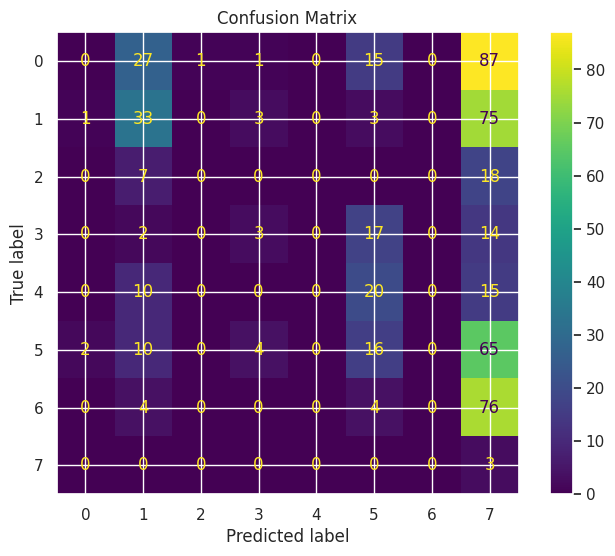

Epoch 20/500, Loss: 1.9008
Epoch 40/500, Loss: 1.8353
Epoch 60/500, Loss: 1.8008
Epoch 80/500, Loss: 1.7581
Epoch 100/500, Loss: 1.7095
Epoch 120/500, Loss: 1.6690
Epoch 140/500, Loss: 1.6585
Epoch 160/500, Loss: 1.6093
Epoch 180/500, Loss: 1.6208
Epoch 200/500, Loss: 1.5671
Epoch 220/500, Loss: 1.5410
Epoch 240/500, Loss: 1.5827
Epoch 260/500, Loss: 1.5241
Epoch 280/500, Loss: 1.4962
Epoch 300/500, Loss: 1.4809
Epoch 320/500, Loss: 1.4705
Epoch 340/500, Loss: 1.4639
Epoch 360/500, Loss: 1.4922
Epoch 380/500, Loss: 1.4461
Epoch 400/500, Loss: 1.4387
Epoch 420/500, Loss: 1.4348
Epoch 440/500, Loss: 1.4179
Epoch 460/500, Loss: 1.3706
Epoch 480/500, Loss: 1.3877
Epoch 500/500, Loss: 1.3811


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 20/500, Loss: 1.8763
Epoch 40/500, Loss: 1.8183
Epoch 60/500, Loss: 1.7518
Epoch 80/500, Loss: 1.6896
Epoch 100/500, Loss: 1.6373
Epoch 120/500, Loss: 1.5975
Epoch 140/500, Loss: 1.5642
Epoch 160/500, Loss: 1.5358
Epoch 180/500, Loss: 1.5113
Epoch 200/500, Loss: 1.4900
Epoch 220/500, Loss: 1.4692
Epoch 240/500, Loss: 1.4497
Epoch 260/500, Loss: 1.4321
Epoch 280/500, Loss: 1.4129
Epoch 300/500, Loss: 1.4003
Epoch 320/500, Loss: 1.3862
Epoch 340/500, Loss: 1.3662
Epoch 360/500, Loss: 1.3510
Epoch 380/500, Loss: 1.3403
Epoch 400/500, Loss: 1.3236
Epoch 420/500, Loss: 1.3114
Epoch 440/500, Loss: 1.2968
Epoch 460/500, Loss: 1.2863
Epoch 480/500, Loss: 1.2713
Epoch 500/500, Loss: 1.2560
Epoch 20/500, Loss: 1.8816
Epoch 40/500, Loss: 1.8211
Epoch 60/500, Loss: 1.7533
Epoch 80/500, Loss: 1.6945
Epoch 100/500, Loss: 1.6456
Epoch 120/500, Loss: 1.6078
Epoch 140/500, Loss: 1.5731
Epoch 160/500, Loss: 1.5445
Epoch 180/500, Loss: 1.5184
Epoch 200/500, Loss: 1.4962
Epoch 220/500, Loss: 1.4735


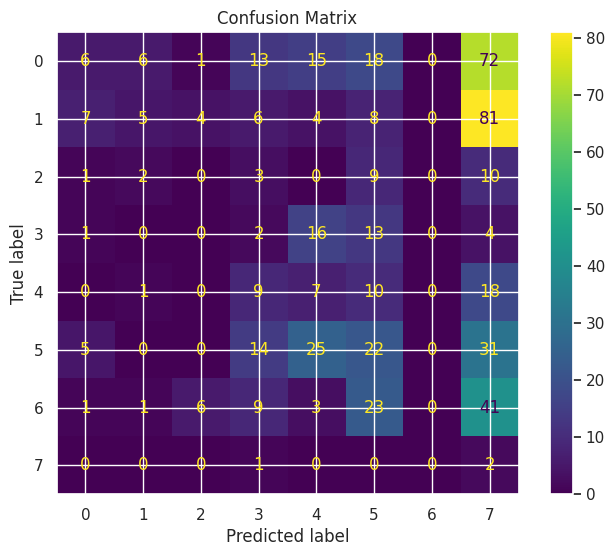

Epoch 20/500, Loss: 1.8895
Epoch 40/500, Loss: 1.8569
Epoch 60/500, Loss: 1.7975
Epoch 80/500, Loss: 1.7513
Epoch 100/500, Loss: 1.7106
Epoch 120/500, Loss: 1.6828
Epoch 140/500, Loss: 1.6334
Epoch 160/500, Loss: 1.5965
Epoch 180/500, Loss: 1.5813
Epoch 200/500, Loss: 1.5478
Epoch 220/500, Loss: 1.5294
Epoch 240/500, Loss: 1.5027
Epoch 260/500, Loss: 1.4814
Epoch 280/500, Loss: 1.4758
Epoch 300/500, Loss: 1.4471
Epoch 320/500, Loss: 1.4298
Epoch 340/500, Loss: 1.4500
Epoch 360/500, Loss: 1.3910
Epoch 380/500, Loss: 1.3985
Epoch 400/500, Loss: 1.3509
Epoch 420/500, Loss: 1.3742
Epoch 440/500, Loss: 1.3346
Epoch 460/500, Loss: 1.3161
Epoch 480/500, Loss: 1.3122
Epoch 500/500, Loss: 1.3026


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 20/500, Loss: 1.8644
Epoch 40/500, Loss: 1.8094
Epoch 60/500, Loss: 1.7410
Epoch 80/500, Loss: 1.6749
Epoch 100/500, Loss: 1.6244
Epoch 120/500, Loss: 1.5823
Epoch 140/500, Loss: 1.5439
Epoch 160/500, Loss: 1.5125
Epoch 180/500, Loss: 1.4821
Epoch 200/500, Loss: 1.4526
Epoch 220/500, Loss: 1.4252
Epoch 240/500, Loss: 1.4025
Epoch 260/500, Loss: 1.3772
Epoch 280/500, Loss: 1.3550
Epoch 300/500, Loss: 1.3353
Epoch 320/500, Loss: 1.3188
Epoch 340/500, Loss: 1.3011
Epoch 360/500, Loss: 1.2828
Epoch 380/500, Loss: 1.2687
Epoch 400/500, Loss: 1.2514
Epoch 420/500, Loss: 1.2393
Epoch 440/500, Loss: 1.2242
Epoch 460/500, Loss: 1.2117
Epoch 480/500, Loss: 1.2012
Epoch 500/500, Loss: 1.1906
Epoch 20/500, Loss: 1.8705
Epoch 40/500, Loss: 1.8097
Epoch 60/500, Loss: 1.7434
Epoch 80/500, Loss: 1.6810
Epoch 100/500, Loss: 1.6342
Epoch 120/500, Loss: 1.5929
Epoch 140/500, Loss: 1.5540
Epoch 160/500, Loss: 1.5201
Epoch 180/500, Loss: 1.4849
Epoch 200/500, Loss: 1.4531
Epoch 220/500, Loss: 1.4260


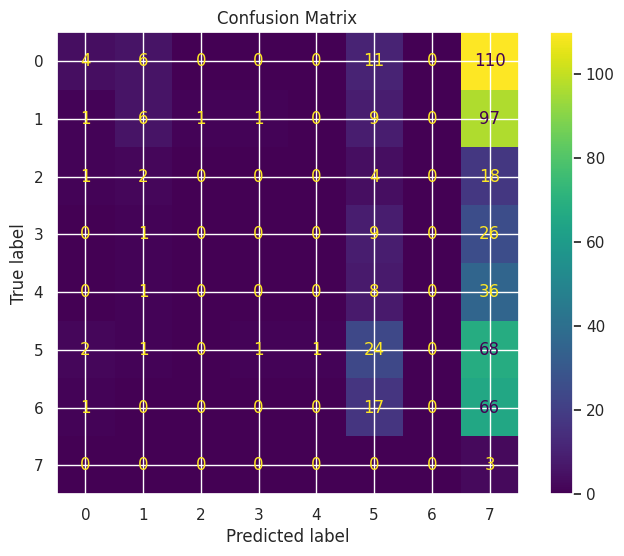

Epoch 20/500, Loss: 1.8623
Epoch 40/500, Loss: 1.8498
Epoch 60/500, Loss: 1.7963
Epoch 80/500, Loss: 1.6725
Epoch 100/500, Loss: 1.6524
Epoch 120/500, Loss: 1.6185
Epoch 140/500, Loss: 1.6195
Epoch 160/500, Loss: 1.5853
Epoch 180/500, Loss: 1.5803
Epoch 200/500, Loss: 1.6037
Epoch 220/500, Loss: 1.5242
Epoch 240/500, Loss: 1.5170
Epoch 260/500, Loss: 1.4821
Epoch 280/500, Loss: 1.4747
Epoch 300/500, Loss: 1.4508
Epoch 320/500, Loss: 1.4238
Epoch 340/500, Loss: 1.4006
Epoch 360/500, Loss: 1.4342
Epoch 380/500, Loss: 1.3957
Epoch 400/500, Loss: 1.3530
Epoch 420/500, Loss: 1.3354
Epoch 440/500, Loss: 1.3134
Epoch 460/500, Loss: 1.3145
Epoch 480/500, Loss: 1.2616
Epoch 500/500, Loss: 1.2634


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 20/500, Loss: 1.8575
Epoch 40/500, Loss: 1.8097
Epoch 60/500, Loss: 1.6644
Epoch 80/500, Loss: 1.6122
Epoch 100/500, Loss: 1.5850
Epoch 120/500, Loss: 1.5565
Epoch 140/500, Loss: 1.5274
Epoch 160/500, Loss: 1.4938
Epoch 180/500, Loss: 1.4657
Epoch 200/500, Loss: 1.4426
Epoch 220/500, Loss: 1.4206
Epoch 240/500, Loss: 1.4011
Epoch 260/500, Loss: 1.3780
Epoch 280/500, Loss: 1.3579
Epoch 300/500, Loss: 1.3321
Epoch 320/500, Loss: 1.3103
Epoch 340/500, Loss: 1.2808
Epoch 360/500, Loss: 1.2509
Epoch 380/500, Loss: 1.2183
Epoch 400/500, Loss: 1.1839
Epoch 420/500, Loss: 1.1426
Epoch 440/500, Loss: 1.1011
Epoch 460/500, Loss: 1.0633
Epoch 480/500, Loss: 1.0248
Epoch 500/500, Loss: 0.9861
Epoch 20/500, Loss: 1.8618
Epoch 40/500, Loss: 1.8043
Epoch 60/500, Loss: 1.6707
Epoch 80/500, Loss: 1.6238
Epoch 100/500, Loss: 1.5948
Epoch 120/500, Loss: 1.5674
Epoch 140/500, Loss: 1.5360
Epoch 160/500, Loss: 1.5076
Epoch 180/500, Loss: 1.4803
Epoch 200/500, Loss: 1.4561
Epoch 220/500, Loss: 1.4312


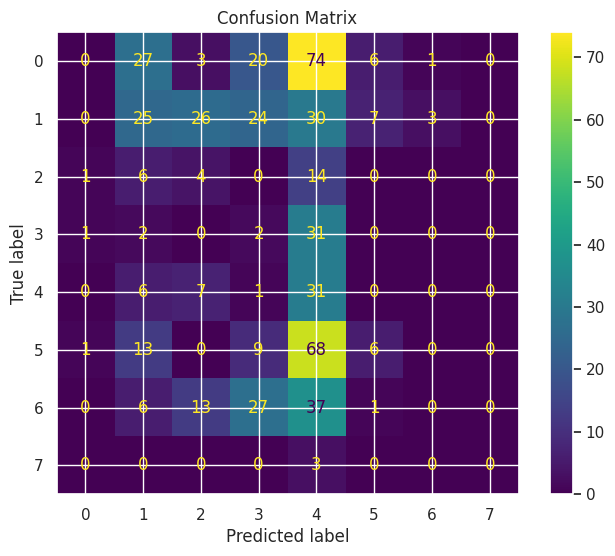

Epoch 20/500, Loss: 1.9004
Epoch 40/500, Loss: 1.8487
Epoch 60/500, Loss: 1.8227
Epoch 80/500, Loss: 1.7984
Epoch 100/500, Loss: 1.7693
Epoch 120/500, Loss: 1.7357
Epoch 140/500, Loss: 1.6706
Epoch 160/500, Loss: 1.6459
Epoch 180/500, Loss: 1.6331
Epoch 200/500, Loss: 1.5889
Epoch 220/500, Loss: 1.5684
Epoch 240/500, Loss: 1.5363
Epoch 260/500, Loss: 1.5432
Epoch 280/500, Loss: 1.5350
Epoch 300/500, Loss: 1.5155
Epoch 320/500, Loss: 1.4964
Epoch 340/500, Loss: 1.4667
Epoch 360/500, Loss: 1.4559
Epoch 380/500, Loss: 1.4350
Epoch 400/500, Loss: 1.4490
Epoch 420/500, Loss: 1.3979
Epoch 440/500, Loss: 1.4219
Epoch 460/500, Loss: 1.3920
Epoch 480/500, Loss: 1.3759
Epoch 500/500, Loss: 1.3666


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 20/500, Loss: 1.8754
Epoch 40/500, Loss: 1.8232
Epoch 60/500, Loss: 1.7719
Epoch 80/500, Loss: 1.7167
Epoch 100/500, Loss: 1.6646
Epoch 120/500, Loss: 1.6291
Epoch 140/500, Loss: 1.5959
Epoch 160/500, Loss: 1.5593
Epoch 180/500, Loss: 1.5337
Epoch 200/500, Loss: 1.5145
Epoch 220/500, Loss: 1.4857
Epoch 240/500, Loss: 1.4628
Epoch 260/500, Loss: 1.4379
Epoch 280/500, Loss: 1.4149
Epoch 300/500, Loss: 1.3944
Epoch 320/500, Loss: 1.3912
Epoch 340/500, Loss: 1.3704
Epoch 360/500, Loss: 1.3581
Epoch 380/500, Loss: 1.3489
Epoch 400/500, Loss: 1.3309
Epoch 420/500, Loss: 1.3127
Epoch 440/500, Loss: 1.3106
Epoch 460/500, Loss: 1.2901
Epoch 480/500, Loss: 1.2747
Epoch 500/500, Loss: 1.2773
Epoch 20/500, Loss: 1.8832
Epoch 40/500, Loss: 1.8242
Epoch 60/500, Loss: 1.7767
Epoch 80/500, Loss: 1.7234
Epoch 100/500, Loss: 1.6772
Epoch 120/500, Loss: 1.6342
Epoch 140/500, Loss: 1.6076
Epoch 160/500, Loss: 1.5735
Epoch 180/500, Loss: 1.5456
Epoch 200/500, Loss: 1.5170
Epoch 220/500, Loss: 1.4931


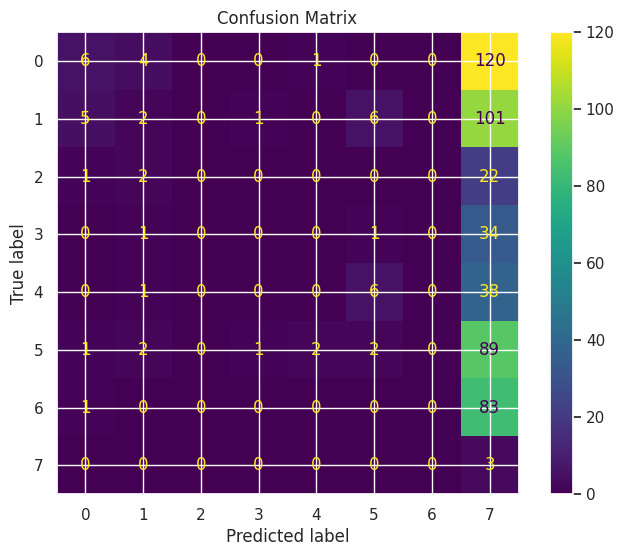

Epoch 20/500, Loss: 1.9147
Epoch 40/500, Loss: 1.8589
Epoch 60/500, Loss: 1.8315
Epoch 80/500, Loss: 1.8193
Epoch 100/500, Loss: 1.8002
Epoch 120/500, Loss: 1.7702
Epoch 140/500, Loss: 1.7096
Epoch 160/500, Loss: 1.6924
Epoch 180/500, Loss: 1.6659
Epoch 200/500, Loss: 1.6303
Epoch 220/500, Loss: 1.6108
Epoch 240/500, Loss: 1.5769
Epoch 260/500, Loss: 1.5849
Epoch 280/500, Loss: 1.5818
Epoch 300/500, Loss: 1.5682
Epoch 320/500, Loss: 1.5467
Epoch 340/500, Loss: 1.5218
Epoch 360/500, Loss: 1.5118
Epoch 380/500, Loss: 1.4944
Epoch 400/500, Loss: 1.5007
Epoch 420/500, Loss: 1.4621
Epoch 440/500, Loss: 1.4789
Epoch 460/500, Loss: 1.4549
Epoch 480/500, Loss: 1.4378
Epoch 500/500, Loss: 1.4312


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 20/500, Loss: 1.8874
Epoch 40/500, Loss: 1.8368
Epoch 60/500, Loss: 1.8049
Epoch 80/500, Loss: 1.7542
Epoch 100/500, Loss: 1.7110
Epoch 120/500, Loss: 1.6777
Epoch 140/500, Loss: 1.6412
Epoch 160/500, Loss: 1.6069
Epoch 180/500, Loss: 1.5799
Epoch 200/500, Loss: 1.5640
Epoch 220/500, Loss: 1.5462
Epoch 240/500, Loss: 1.5214
Epoch 260/500, Loss: 1.4939
Epoch 280/500, Loss: 1.4689
Epoch 300/500, Loss: 1.4616
Epoch 320/500, Loss: 1.4573
Epoch 340/500, Loss: 1.4355
Epoch 360/500, Loss: 1.4259
Epoch 380/500, Loss: 1.4104
Epoch 400/500, Loss: 1.4072
Epoch 420/500, Loss: 1.3819
Epoch 440/500, Loss: 1.3662
Epoch 460/500, Loss: 1.3594
Epoch 480/500, Loss: 1.3527
Epoch 500/500, Loss: 1.3527
Epoch 20/500, Loss: 1.8952
Epoch 40/500, Loss: 1.8358
Epoch 60/500, Loss: 1.8066
Epoch 80/500, Loss: 1.7600
Epoch 100/500, Loss: 1.7169
Epoch 120/500, Loss: 1.6879
Epoch 140/500, Loss: 1.6496
Epoch 160/500, Loss: 1.6235
Epoch 180/500, Loss: 1.5915
Epoch 200/500, Loss: 1.5669
Epoch 220/500, Loss: 1.5542


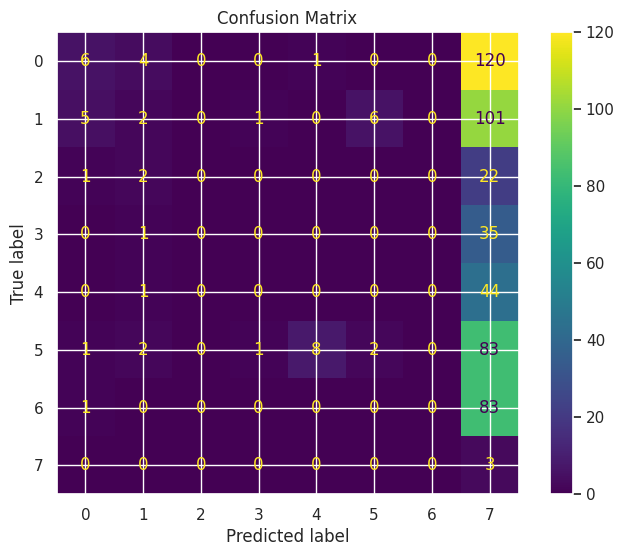

Epoch 20/1000, Loss: 1.5339
Epoch 40/1000, Loss: 1.4054
Epoch 60/1000, Loss: 1.3111
Epoch 80/1000, Loss: 1.2222
Epoch 100/1000, Loss: 1.1066
Epoch 120/1000, Loss: 1.0264
Epoch 140/1000, Loss: 0.9824
Epoch 160/1000, Loss: 0.8743
Epoch 180/1000, Loss: 0.8118
Epoch 200/1000, Loss: 0.7254
Epoch 220/1000, Loss: 0.6618
Epoch 240/1000, Loss: 0.6514
Epoch 260/1000, Loss: 0.5698
Epoch 280/1000, Loss: 0.5011
Epoch 300/1000, Loss: 0.4782
Epoch 320/1000, Loss: 0.4331
Epoch 340/1000, Loss: 0.4019
Epoch 360/1000, Loss: 0.4427
Epoch 380/1000, Loss: 0.3513
Epoch 400/1000, Loss: 0.3299
Epoch 420/1000, Loss: 0.3364
Epoch 440/1000, Loss: 0.3238
Epoch 460/1000, Loss: 0.2839
Epoch 480/1000, Loss: 0.2688
Epoch 500/1000, Loss: 0.2550
Epoch 520/1000, Loss: 0.2395
Epoch 540/1000, Loss: 0.2293
Epoch 560/1000, Loss: 0.2376
Epoch 580/1000, Loss: 0.2088
Epoch 600/1000, Loss: 0.2010
Epoch 620/1000, Loss: 0.1924
Epoch 640/1000, Loss: 0.1875
Epoch 660/1000, Loss: 0.1781
Epoch 680/1000, Loss: 0.1954
Epoch 700/1000, Lo

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 20/1000, Loss: 1.4753
Epoch 40/1000, Loss: 1.3189
Epoch 60/1000, Loss: 1.1982
Epoch 80/1000, Loss: 1.0895
Epoch 100/1000, Loss: 0.9757
Epoch 120/1000, Loss: 0.8722
Epoch 140/1000, Loss: 0.7769
Epoch 160/1000, Loss: 0.6898
Epoch 180/1000, Loss: 0.6110
Epoch 200/1000, Loss: 0.5405
Epoch 220/1000, Loss: 0.4868
Epoch 240/1000, Loss: 0.4404
Epoch 260/1000, Loss: 0.4039
Epoch 280/1000, Loss: 0.3718
Epoch 300/1000, Loss: 0.3461
Epoch 320/1000, Loss: 0.3270
Epoch 340/1000, Loss: 0.3061
Epoch 360/1000, Loss: 0.2898
Epoch 380/1000, Loss: 0.2787
Epoch 400/1000, Loss: 0.2645
Epoch 420/1000, Loss: 0.2510
Epoch 440/1000, Loss: 0.2384
Epoch 460/1000, Loss: 0.2278
Epoch 480/1000, Loss: 0.2198
Epoch 500/1000, Loss: 0.2086
Epoch 520/1000, Loss: 0.1990
Epoch 540/1000, Loss: 0.1916
Epoch 560/1000, Loss: 0.1847
Epoch 580/1000, Loss: 0.1762
Epoch 600/1000, Loss: 0.1666
Epoch 620/1000, Loss: 0.1612
Epoch 640/1000, Loss: 0.1560
Epoch 660/1000, Loss: 0.1485
Epoch 680/1000, Loss: 0.1450
Epoch 700/1000, Lo

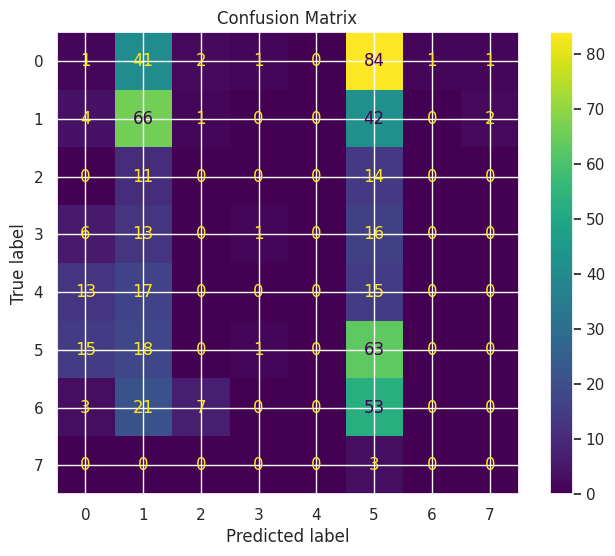

Epoch 20/1000, Loss: 1.5559
Epoch 40/1000, Loss: 1.4177
Epoch 60/1000, Loss: 1.3279
Epoch 80/1000, Loss: 1.2630
Epoch 100/1000, Loss: 1.2465
Epoch 120/1000, Loss: 1.1654
Epoch 140/1000, Loss: 1.1194
Epoch 160/1000, Loss: 0.9994
Epoch 180/1000, Loss: 0.9801
Epoch 200/1000, Loss: 0.8794
Epoch 220/1000, Loss: 0.8097
Epoch 240/1000, Loss: 0.7429
Epoch 260/1000, Loss: 0.6893
Epoch 280/1000, Loss: 0.6678
Epoch 300/1000, Loss: 0.6404
Epoch 320/1000, Loss: 0.6048
Epoch 340/1000, Loss: 0.5521
Epoch 360/1000, Loss: 0.5634
Epoch 380/1000, Loss: 0.5186
Epoch 400/1000, Loss: 0.5220
Epoch 420/1000, Loss: 0.4635
Epoch 440/1000, Loss: 0.4605
Epoch 460/1000, Loss: 0.4335
Epoch 480/1000, Loss: 0.4177
Epoch 500/1000, Loss: 0.4068
Epoch 520/1000, Loss: 0.4083
Epoch 540/1000, Loss: 0.3959
Epoch 560/1000, Loss: 0.3700
Epoch 580/1000, Loss: 0.3921
Epoch 600/1000, Loss: 0.3620
Epoch 620/1000, Loss: 0.3532
Epoch 640/1000, Loss: 0.3571
Epoch 660/1000, Loss: 0.3372
Epoch 680/1000, Loss: 0.3199
Epoch 700/1000, Lo

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 20/1000, Loss: 1.5016
Epoch 40/1000, Loss: 1.3270
Epoch 60/1000, Loss: 1.2342
Epoch 80/1000, Loss: 1.1513
Epoch 100/1000, Loss: 1.0803
Epoch 120/1000, Loss: 0.9885
Epoch 140/1000, Loss: 0.9089
Epoch 160/1000, Loss: 0.8228
Epoch 180/1000, Loss: 0.7653
Epoch 200/1000, Loss: 0.7098
Epoch 220/1000, Loss: 0.6499
Epoch 240/1000, Loss: 0.6065
Epoch 260/1000, Loss: 0.5809
Epoch 280/1000, Loss: 0.5457
Epoch 300/1000, Loss: 0.4891
Epoch 320/1000, Loss: 0.4733
Epoch 340/1000, Loss: 0.4644
Epoch 360/1000, Loss: 0.4579
Epoch 380/1000, Loss: 0.4328
Epoch 400/1000, Loss: 0.4216
Epoch 420/1000, Loss: 0.3945
Epoch 440/1000, Loss: 0.3780
Epoch 460/1000, Loss: 0.3613
Epoch 480/1000, Loss: 0.3484
Epoch 500/1000, Loss: 0.3601
Epoch 520/1000, Loss: 0.3301
Epoch 540/1000, Loss: 0.3439
Epoch 560/1000, Loss: 0.3349
Epoch 580/1000, Loss: 0.3191
Epoch 600/1000, Loss: 0.3186
Epoch 620/1000, Loss: 0.2992
Epoch 640/1000, Loss: 0.2986
Epoch 660/1000, Loss: 0.2940
Epoch 680/1000, Loss: 0.2904
Epoch 700/1000, Lo

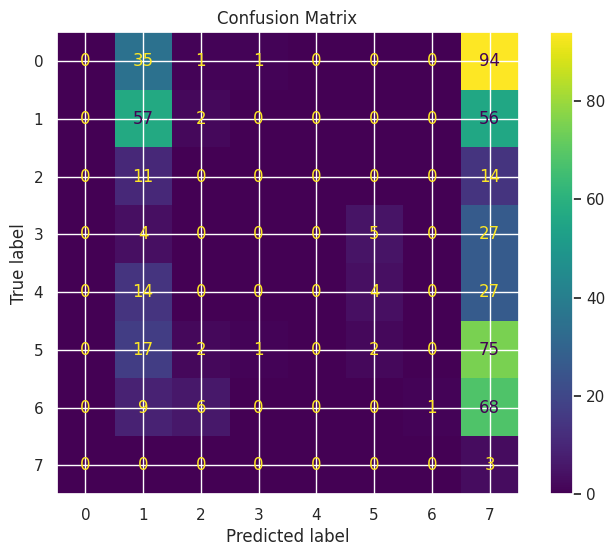

In [20]:
models_lstm_f1 = {}

# ============================================================
# 1º MELHOR: LSTM_sgd_momentum_30
# Expansões: tamanhos, regularização, learning_rate adaptive
# ============================================================

# Mantém (30,)
models_lstm_f1['LSTM_sgd_momentum_30'] = LSTMClassifier(
    hidden_size=30, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500,
    batch_size=32, random_state=42
)

# Expansão: (50,)
models_lstm_f1['LSTM_sgd_momentum_50'] = LSTMClassifier(
    hidden_size=50, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500,
    batch_size=32, random_state=42
)

# Expansão: (50, 25) - 2 camadas
models_lstm_f1['LSTM_sgd_momentum_50_25'] = LSTMClassifier(
    hidden_size=50, num_layers=2, dropout=0.0, fc_hidden_layers=(25,),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500,
    batch_size=32, random_state=42
)

# Expansão: regularização (dropout) - equivalente ao alpha
models_lstm_f1['LSTM_sgd_momentum_reg1e3'] = LSTMClassifier(
    hidden_size=50, num_layers=1, dropout=0.3, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500,
    batch_size=32, random_state=42
)

models_lstm_f1['LSTM_sgd_momentum_reg5e3'] = LSTMClassifier(
    hidden_size=50, num_layers=1, dropout=0.5, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500,
    batch_size=32, random_state=42
)

# Expansão: learning_rate adaptive
models_lstm_f1['LSTM_sgd_adaptive'] = LSTMClassifier(
    hidden_size=50, num_layers=1, dropout=0.3, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.95, epochs=500,
    batch_size=32, random_state=42
)

# ============================================================
# 2º MELHOR: LSTM_rmsprop_30
# Expansões: tamanhos e regularização
# ============================================================

models_lstm_f1['LSTM_rmsprop_30'] = LSTMClassifier(
    hidden_size=30, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    solver='rmsprop', learning_rate=0.001, epochs=500,
    batch_size=32, random_state=42
)

models_lstm_f1['LSTM_rmsprop_50'] = LSTMClassifier(
    hidden_size=50, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    solver='rmsprop', learning_rate=0.001, epochs=500,
    batch_size=32, random_state=42
)

models_lstm_f1['LSTM_rmsprop_50_25'] = LSTMClassifier(
    hidden_size=50, num_layers=2, dropout=0.0, fc_hidden_layers=(25,),
    solver='rmsprop', learning_rate=0.001, epochs=500,
    batch_size=32, random_state=42
)

models_lstm_f1['LSTM_rmsprop_reg1e3'] = LSTMClassifier(
    hidden_size=50, num_layers=1, dropout=0.3, fc_hidden_layers=(),
    solver='rmsprop', learning_rate=0.001, epochs=500,
    batch_size=32, random_state=42
)

models_lstm_f1['LSTM_rmsprop_reg5e3'] = LSTMClassifier(
    hidden_size=50, num_layers=1, dropout=0.5, fc_hidden_layers=(),
    solver='rmsprop', learning_rate=0.001, epochs=500,
    batch_size=32, random_state=42
)

# ============================================================
# 3º MELHOR: LSTM_adam_30 (já tem lowLR)
# Expansões: tamanhos e regularização
# ============================================================

models_lstm_f1['LSTM_adam_lowLR_30'] = LSTMClassifier(
    hidden_size=30, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500,
    batch_size=32, random_state=42
)

models_lstm_f1['LSTM_adam_lowLR_50'] = LSTMClassifier(
    hidden_size=50, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500,
    batch_size=32, random_state=42
)

models_lstm_f1['LSTM_adam_lowLR_50_25'] = LSTMClassifier(
    hidden_size=50, num_layers=2, dropout=0.0, fc_hidden_layers=(25,),
    solver='adam', learning_rate=0.0001, epochs=500,
    batch_size=32, random_state=42
)

models_lstm_f1['LSTM_adam_lowLR_reg1e3'] = LSTMClassifier(
    hidden_size=50, num_layers=1, dropout=0.3, fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500,
    batch_size=32, random_state=42
)

models_lstm_f1['LSTM_adam_lowLR_reg5e3'] = LSTMClassifier(
    hidden_size=50, num_layers=1, dropout=0.5, fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500,
    batch_size=32, random_state=42
)

# ============================================================
# EXTRA: LBFGS equivalente (usando rmsprop com max_iter maior)
# ============================================================
models_lstm_f1['LSTM_rmsprop_30_lbfgs'] = LSTMClassifier(
    hidden_size=30, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    solver='rmsprop', learning_rate=0.001, epochs=1000,
    batch_size=32, random_state=42
)

models_lstm_f1['LSTM_rmsprop_50_lbfgs'] = LSTMClassifier(
    hidden_size=50, num_layers=1, dropout=0.3, fc_hidden_layers=(),
    solver='rmsprop', learning_rate=0.001, epochs=1000,
    batch_size=32, random_state=42
)

main(models_lstm_f1, "lstm_fase_1")

/tmp/ipykernel_21399/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)


Epoch 20/500, Loss: 1.8988
Epoch 40/500, Loss: 1.8278
Epoch 60/500, Loss: 1.7867
Epoch 80/500, Loss: 1.7383
Epoch 100/500, Loss: 1.6828
Epoch 120/500, Loss: 1.6564
Epoch 140/500, Loss: 1.6613
Epoch 160/500, Loss: 1.6103
Epoch 180/500, Loss: 1.5829
Epoch 200/500, Loss: 1.5681
Epoch 220/500, Loss: 1.5363
Epoch 240/500, Loss: 1.5224
Epoch 260/500, Loss: 1.5231
Epoch 280/500, Loss: 1.5131
Epoch 300/500, Loss: 1.4852
Epoch 320/500, Loss: 1.4785
Epoch 340/500, Loss: 1.4690
Epoch 360/500, Loss: 1.4851
Epoch 380/500, Loss: 1.4354
Epoch 400/500, Loss: 1.4279
Epoch 420/500, Loss: 1.4214
Epoch 440/500, Loss: 1.4085
Epoch 460/500, Loss: 1.3935
Epoch 480/500, Loss: 1.3929
Epoch 500/500, Loss: 1.3816


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 20/500, Loss: 1.8897
Epoch 40/500, Loss: 1.8085
Epoch 60/500, Loss: 1.7413
Epoch 80/500, Loss: 1.6859
Epoch 100/500, Loss: 1.6389
Epoch 120/500, Loss: 1.6015
Epoch 140/500, Loss: 1.5696
Epoch 160/500, Loss: 1.5415
Epoch 180/500, Loss: 1.5135
Epoch 200/500, Loss: 1.4928
Epoch 220/500, Loss: 1.4713
Epoch 240/500, Loss: 1.4538
Epoch 260/500, Loss: 1.4348
Epoch 280/500, Loss: 1.4185
Epoch 300/500, Loss: 1.4046
Epoch 320/500, Loss: 1.3942
Epoch 340/500, Loss: 1.3755
Epoch 360/500, Loss: 1.3619
Epoch 380/500, Loss: 1.3531
Epoch 400/500, Loss: 1.3396
Epoch 420/500, Loss: 1.3267
Epoch 440/500, Loss: 1.3133
Epoch 460/500, Loss: 1.3006
Epoch 480/500, Loss: 1.2879
Epoch 500/500, Loss: 1.2767
Epoch 20/500, Loss: 1.8924
Epoch 40/500, Loss: 1.8161
Epoch 60/500, Loss: 1.7491
Epoch 80/500, Loss: 1.6923
Epoch 100/500, Loss: 1.6451
Epoch 120/500, Loss: 1.6096
Epoch 140/500, Loss: 1.5790
Epoch 160/500, Loss: 1.5525
Epoch 180/500, Loss: 1.5274
Epoch 200/500, Loss: 1.5071
Epoch 220/500, Loss: 1.4869


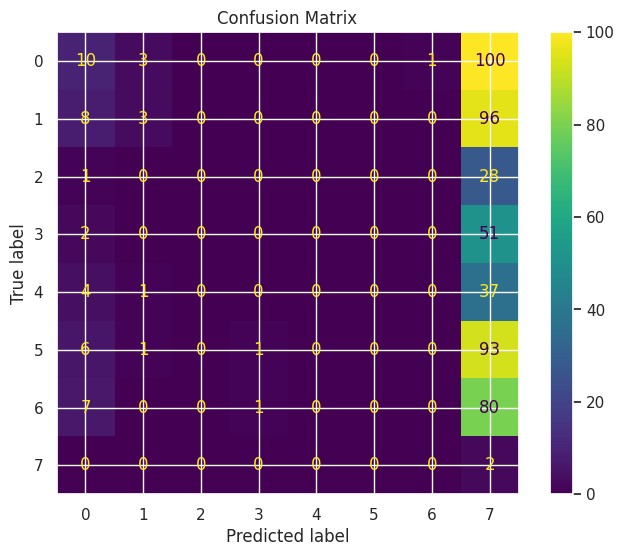

Epoch 20/500, Loss: 1.8929
Epoch 40/500, Loss: 1.8628
Epoch 60/500, Loss: 1.8547
Epoch 80/500, Loss: 1.8464
Epoch 100/500, Loss: 1.8612
Epoch 120/500, Loss: 1.8380
Epoch 140/500, Loss: 1.8557
Epoch 160/500, Loss: 1.8315
Epoch 180/500, Loss: 1.8246
Epoch 200/500, Loss: 1.8195
Epoch 220/500, Loss: 1.8159
Epoch 240/500, Loss: 1.8056
Epoch 260/500, Loss: 1.7912
Epoch 280/500, Loss: 1.7739
Epoch 300/500, Loss: 1.7534
Epoch 320/500, Loss: 1.7320
Epoch 340/500, Loss: 1.7129
Epoch 360/500, Loss: 1.7069
Epoch 380/500, Loss: 1.6728
Epoch 400/500, Loss: 1.6494
Epoch 420/500, Loss: 1.6361
Epoch 440/500, Loss: 1.6197
Epoch 460/500, Loss: 1.6061
Epoch 480/500, Loss: 1.5952
Epoch 500/500, Loss: 1.5800


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 20/500, Loss: 1.9022
Epoch 40/500, Loss: 1.8768
Epoch 60/500, Loss: 1.8676
Epoch 80/500, Loss: 1.8624
Epoch 100/500, Loss: 1.8555
Epoch 120/500, Loss: 1.8495
Epoch 140/500, Loss: 1.8440
Epoch 160/500, Loss: 1.8359
Epoch 180/500, Loss: 1.8262
Epoch 200/500, Loss: 1.8154
Epoch 220/500, Loss: 1.7994
Epoch 240/500, Loss: 1.7790
Epoch 260/500, Loss: 1.7567
Epoch 280/500, Loss: 1.7331
Epoch 300/500, Loss: 1.7076
Epoch 320/500, Loss: 1.6849
Epoch 340/500, Loss: 1.6583
Epoch 360/500, Loss: 1.6367
Epoch 380/500, Loss: 1.6215
Epoch 400/500, Loss: 1.6009
Epoch 420/500, Loss: 1.5860
Epoch 440/500, Loss: 1.5674
Epoch 460/500, Loss: 1.5499
Epoch 480/500, Loss: 1.5332
Epoch 500/500, Loss: 1.5172
Epoch 20/500, Loss: 1.9025
Epoch 40/500, Loss: 1.8789
Epoch 60/500, Loss: 1.8687
Epoch 80/500, Loss: 1.8633
Epoch 100/500, Loss: 1.8576
Epoch 120/500, Loss: 1.8523
Epoch 140/500, Loss: 1.8468
Epoch 160/500, Loss: 1.8398
Epoch 180/500, Loss: 1.8319
Epoch 200/500, Loss: 1.8225
Epoch 220/500, Loss: 1.8098


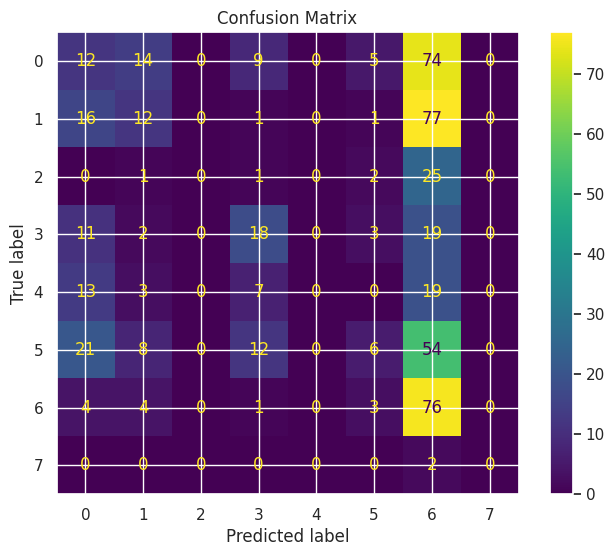

Epoch 20/500, Loss: 1.5540
Epoch 40/500, Loss: 1.4017
Epoch 60/500, Loss: 1.3366
Epoch 80/500, Loss: 1.2429
Epoch 100/500, Loss: 1.1335
Epoch 120/500, Loss: 1.0606
Epoch 140/500, Loss: 1.0414
Epoch 160/500, Loss: 0.9494
Epoch 180/500, Loss: 0.8734
Epoch 200/500, Loss: 0.8288
Epoch 220/500, Loss: 0.7551
Epoch 240/500, Loss: 0.7049
Epoch 260/500, Loss: 0.6632
Epoch 280/500, Loss: 0.6410
Epoch 300/500, Loss: 0.6218
Epoch 320/500, Loss: 0.6057
Epoch 340/500, Loss: 0.5602
Epoch 360/500, Loss: 0.6083
Epoch 380/500, Loss: 0.5123
Epoch 400/500, Loss: 0.5146
Epoch 420/500, Loss: 0.5065
Epoch 440/500, Loss: 0.4924
Epoch 460/500, Loss: 0.4629
Epoch 480/500, Loss: 0.4767
Epoch 500/500, Loss: 0.4571


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 20/500, Loss: 1.4788
Epoch 40/500, Loss: 1.3354
Epoch 60/500, Loss: 1.2213
Epoch 80/500, Loss: 1.1178
Epoch 100/500, Loss: 1.0178
Epoch 120/500, Loss: 0.9288
Epoch 140/500, Loss: 0.8465
Epoch 160/500, Loss: 0.7754
Epoch 180/500, Loss: 0.7154
Epoch 200/500, Loss: 0.6661
Epoch 220/500, Loss: 0.6205
Epoch 240/500, Loss: 0.5847
Epoch 260/500, Loss: 0.5519
Epoch 280/500, Loss: 0.5262
Epoch 300/500, Loss: 0.5043
Epoch 320/500, Loss: 0.4830
Epoch 340/500, Loss: 0.4590
Epoch 360/500, Loss: 0.4475
Epoch 380/500, Loss: 0.4315
Epoch 400/500, Loss: 0.4224
Epoch 420/500, Loss: 0.4077
Epoch 440/500, Loss: 0.3941
Epoch 460/500, Loss: 0.3831
Epoch 480/500, Loss: 0.3768
Epoch 500/500, Loss: 0.3649
Epoch 20/500, Loss: 1.4929
Epoch 40/500, Loss: 1.3500
Epoch 60/500, Loss: 1.2287
Epoch 80/500, Loss: 1.1270
Epoch 100/500, Loss: 1.0260
Epoch 120/500, Loss: 0.9350
Epoch 140/500, Loss: 0.8515
Epoch 160/500, Loss: 0.7694
Epoch 180/500, Loss: 0.7021
Epoch 200/500, Loss: 0.6467
Epoch 220/500, Loss: 0.6019


In [ ]:
models_lstm_f2 = {}

# ============================================================
# OTIMIZADORES (3 solvers)
# ============================================================

# solver = adam
models_lstm_f2['LSTM_solver_adam'] = LSTMClassifier(
    hidden_size=30, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500,
    batch_size=32, random_state=42
)

# solver = sgd (com momentum)
models_lstm_f2['LSTM_solver_sgd'] = LSTMClassifier(
    hidden_size=30, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500,
    batch_size=32, random_state=42
)

# solver = rmsprop (equivalente ao lbfgs do MLP)
models_lstm_f2['LSTM_solver_rmsprop'] = LSTMClassifier(
    hidden_size=30, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    solver='rmsprop', learning_rate=0.001, epochs=500,
    batch_size=32, random_state=42
)

# ============================================================
# ARQUITETURAS (diferentes tamanhos)
# ============================================================

# hidden_size = 10
models_lstm_f2['LSTM_arch_10'] = LSTMClassifier(
    hidden_size=10, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500,
    batch_size=32, random_state=42
)

# hidden_size = 30
models_lstm_f2['LSTM_arch_30'] = LSTMClassifier(
    hidden_size=30, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500,
    batch_size=32, random_state=42
)

# hidden_size = 50
models_lstm_f2['LSTM_arch_50'] = LSTMClassifier(
    hidden_size=50, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500,
    batch_size=32, random_state=42
)

# hidden_size = 50 com 2 camadas + FC (50_25)
models_lstm_f2['LSTM_arch_50_25'] = LSTMClassifier(
    hidden_size=50, num_layers=2, dropout=0.0, fc_hidden_layers=(25,),
    solver='adam', learning_rate=0.0001, epochs=500,
    batch_size=32, random_state=42
)

# ============================================================
# REGULARIZAÇÃO (dropout equivalente ao alpha)
# ============================================================

# dropout = 0.0 (equivalente alpha 1e-6)
models_lstm_f2['LSTM_dropout_0'] = LSTMClassifier(
    hidden_size=30, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500,
    batch_size=32, random_state=42
)

# dropout = 0.1 (equivalente alpha 1e-5)
models_lstm_f2['LSTM_dropout_1e-1'] = LSTMClassifier(
    hidden_size=30, num_layers=1, dropout=0.1, fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500,
    batch_size=32, random_state=42
)

# dropout = 0.2 (equivalente alpha 1e-4)
models_lstm_f2['LSTM_dropout_1e-1.5'] = LSTMClassifier(
    hidden_size=30, num_layers=1, dropout=0.2, fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500,
    batch_size=32, random_state=42
)

# dropout = 0.3 (equivalente alpha 1e-3)
models_lstm_f2['LSTM_dropout_1e-1.8'] = LSTMClassifier(
    hidden_size=30, num_layers=1, dropout=0.3, fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500,
    batch_size=32, random_state=42
)

main(models_lstm_f2, "lstm_fase_2")

verficart o codigo acima,
entender cada passo
fazs a validcao dos hiermatepros][link text](https://)

In [ ]:
class HybridLSTM_MLP(BaseEstimator, ClassifierMixin):
    def __init__(self,
                 lstm_hidden_size=32,
                 lstm_num_layers=1,
                 lstm_dropout=0.2,
                 mlp_hidden_layers=(16,),
                 mlp_dropout=0.2,
                 input_size=None,
                 output_size=8,
                 learning_rate=0.001,
                 epochs=100,
                 batch_size=32,
                 random_state=42,
                 device='cpu'):

        self.lstm_hidden_size = lstm_hidden_size
        self.lstm_num_layers = lstm_num_layers
        self.lstm_dropout = lstm_dropout
        self.mlp_hidden_layers = mlp_hidden_layers
        self.mlp_dropout = mlp_dropout
        self.input_size = input_size
        self.output_size = output_size
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.batch_size = batch_size
        self.random_state = random_state
        self.device = device if torch.cuda.is_available() else 'cpu'

        self.model = None
        self.optimizer = None
        self.criterion = None
        self.label_encoder = LabelEncoder()
        self.scaler = MinMaxScaler()

    def _build_model(self):
        class HybridModel(nn.Module):
            def __init__(self, input_size, lstm_hidden, lstm_layers, lstm_dropout,
                         mlp_hiddens, mlp_dropout, output_size):
                super(HybridModel, self).__init__()

                # Camada LSTM
                self.lstm = nn.LSTM(
                    input_size=input_size,
                    hidden_size=lstm_hidden,
                    num_layers=lstm_layers,
                    batch_first=True,
                    dropout=lstm_dropout if lstm_layers > 1 else 0
                )

                # Dropout após LSTM
                self.lstm_dropout = nn.Dropout(lstm_dropout)

                # Camadas MLP
                mlp_layers = []
                prev_size = lstm_hidden

                for hidden_size in mlp_hiddens:
                    mlp_layers.append(nn.Linear(prev_size, hidden_size))
                    mlp_layers.append(nn.ReLU())
                    mlp_layers.append(nn.Dropout(mlp_dropout))
                    prev_size = hidden_size

                # Camada de saída
                mlp_layers.append(nn.Linear(prev_size, output_size))

                self.mlp = nn.Sequential(*mlp_layers)

            def forward(self, x):
                # LSTM forward
                lstm_out, (hidden, cell) = self.lstm(x)

                # Pegar o último hidden state
                last_hidden = hidden[-1]  # (batch, lstm_hidden)

                # Dropout
                out = self.lstm_dropout(last_hidden)

                # MLP forward
                out = self.mlp(out)

                return out

        return HybridModel(
            input_size=self.input_size,
            lstm_hidden=self.lstm_hidden_size,
            lstm_layers=self.lstm_num_layers,
            lstm_dropout=self.lstm_dropout,
            mlp_hiddens=self.mlp_hidden_layers,
            mlp_dropout=self.mlp_dropout,
            output_size=self.output_size
        )

    def fit(self, X, y):
        # Converter para numpy
        if isinstance(X, pd.DataFrame):
            X = X.values
        if isinstance(y, (pd.Series, pd.DataFrame)):
            y = y.values

        # Salvar input_size
        if self.input_size is None:
            self.input_size = X.shape[1]

        # Escalar dados
        X_scaled = self.scaler.fit_transform(X)

        # Codificar labels
        y_encoded = self.label_encoder.fit_transform(y)
        self.output_size = len(self.label_encoder.classes_)

        # Construir modelo
        torch.manual_seed(self.random_state)
        self.model = self._build_model().to(self.device)

        # Configurar otimizador e loss
        self.optimizer = optim.Adam(self.model.parameters(), lr=self.learning_rate)
        self.criterion = nn.CrossEntropyLoss()

        # Preparar dados
        X_tensor = torch.FloatTensor(X_scaled).unsqueeze(1).to(self.device)
        y_tensor = torch.LongTensor(y_encoded).to(self.device)

        dataset = TensorDataset(X_tensor, y_tensor)
        dataloader = DataLoader(dataset, batch_size=self.batch_size, shuffle=True)

        # Treinamento
        self.model.train()
        for epoch in range(self.epochs):
            total_loss = 0
            for batch_X, batch_y in dataloader:
                self.optimizer.zero_grad()
                outputs = self.model(batch_X)
                loss = self.criterion(outputs, batch_y)
                loss.backward()
                self.optimizer.step()
                total_loss += loss.item()

            if (epoch + 1) % 20 == 0:
                print(f"Epoch {epoch+1}/{self.epochs}, Loss: {total_loss/len(dataloader):.4f}")

        return self

    def predict(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).unsqueeze(1).to(self.device)

        with torch.no_grad():
            outputs = self.model(X_tensor)
            _, predicted = torch.max(outputs, 1)

        return self.label_encoder.inverse_transform(predicted.cpu().numpy())

    def predict_proba(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).unsqueeze(1).to(self.device)

        with torch.no_grad():
            outputs = torch.softmax(self.model(X_tensor), dim=1)

        return outputs.cpu().numpy()

    def get_params(self, deep=True):
        return {
            'lstm_hidden_size': self.lstm_hidden_size,
            'lstm_num_layers': self.lstm_num_layers,
            'lstm_dropout': self.lstm_dropout,
            'mlp_hidden_layers': self.mlp_hidden_layers,
            'mlp_dropout': self.mlp_dropout,
            'input_size': self.input_size,
            'output_size': self.output_size,
            'learning_rate': self.learning_rate,
            'epochs': self.epochs,
            'batch_size': self.batch_size,
            'random_state': self.random_state
        }

    def set_params(self, **params):
        for key, value in params.items():
            setattr(self, key, value)
        return self

/tmp/ipykernel_5383/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)


Epoch 20/30, Loss: 1.8017


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 20/30, Loss: 1.8083
Epoch 20/30, Loss: 1.7946
Epoch 20/30, Loss: 1.7840
Epoch 20/30, Loss: 1.7953
Epoch 20/30, Loss: 1.7863

Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: Hybrid_test
------------------------------
TRAIN
Accuracy: 0.3939
Precision: 0.2816
Recall: 0.3939
F1: 0.3124
Kappa: 0.2424
Error Rate: 0.6061

TEST
Accuracy: 0.2015
Precision: 0.0877
Recall: 0.2015
F1: 0.0848
Kappa: 0.0086
Error Rate: 0.7985
Gap (overfitting): 0.1924

CV
Mean: 0.3714
Std: 0.0100
------------------------------
Model params:
{'lstm_hidden_size': 8, 'lstm_num_layers': 1, 'lstm_dropout': 0.3, 'mlp_hidden_layers': (8,), 'mlp_dropout': 0.2, 'input_size': 21, 'output_size': 8, 'learning_rate': 0.0005, 'epochs': 30, 'batch_size': 16, 'random_state': 42}



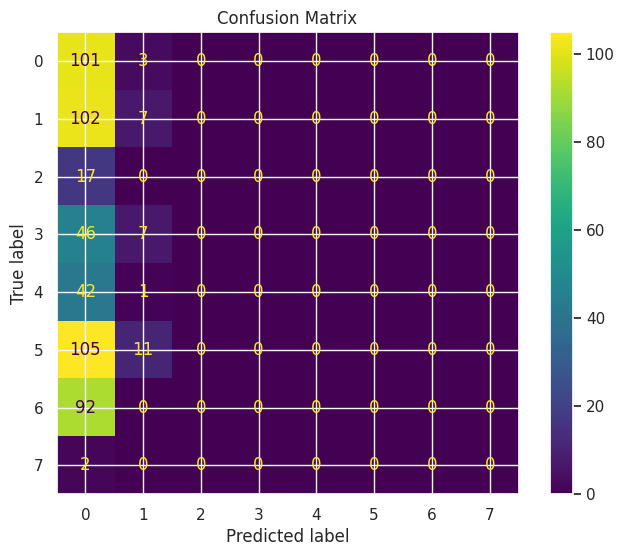

In [ ]:
# Testar um modelo híbrido primeiro
modelo_hibrido_teste = {
    'Hybrid_test': HybridLSTM_MLP(
        lstm_hidden_size=8,
        lstm_num_layers=1,
        lstm_dropout=0.3,
        mlp_hidden_layers=(8,),
        mlp_dropout=0.2,
        learning_rate=0.0005,
        epochs=30,
        batch_size=16,
        random_state=42
    )
}

main(modelo_hibrido_teste, "hybrid_test")

# Depois testar todos
# main(models_hybrid, "hybrid_experiments")

verficart o codigo acima,
entender cada passo
fazs a validcao dos hiermatepros][link text](https://)**bold text**

In [ ]:
class CNN1DClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self,
                 num_filters=[32, 64],
                 kernel_sizes=[3, 3],
                 dropout=0.2,
                 fc_hidden_layers=(32,),
                 input_size=None,
                 output_size=8,
                 learning_rate=0.001,
                 epochs=100,
                 batch_size=32,
                 random_state=42,
                 device='cpu'):

        self.num_filters = num_filters
        self.kernel_sizes = kernel_sizes
        self.dropout = dropout
        self.fc_hidden_layers = fc_hidden_layers
        self.input_size = input_size
        self.output_size = output_size
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.batch_size = batch_size
        self.random_state = random_state
        self.device = device if torch.cuda.is_available() else 'cpu'

        self.model = None
        self.optimizer = None
        self.criterion = None
        self.label_encoder = LabelEncoder()
        self.scaler = MinMaxScaler()

    def _build_model(self):
        class CNN1DModel(nn.Module):
            def __init__(self, input_size, num_filters, kernel_sizes, dropout,
                         fc_hiddens, output_size):
                super(CNN1DModel, self).__init__()

                # Camadas Convolucionais 1D
                conv_layers = []
                prev_channels = 1  # 1 canal de entrada

                for i, (filters, kernel) in enumerate(zip(num_filters, kernel_sizes)):
                    conv_layers.append(
                        nn.Conv1d(in_channels=prev_channels,
                                 out_channels=filters,
                                 kernel_size=kernel,
                                 padding='same')
                    )
                    conv_layers.append(nn.BatchNorm1d(filters))
                    conv_layers.append(nn.ReLU())
                    conv_layers.append(nn.MaxPool1d(kernel_size=2))
                    conv_layers.append(nn.Dropout(dropout))
                    prev_channels = filters

                self.conv_layers = nn.Sequential(*conv_layers)

                # Calcular tamanho após convoluções
                conv_out_size = self._get_conv_output_size(input_size)

                # Fully connected layers
                fc_layers = []
                prev_size = conv_out_size

                for hidden_size in fc_hiddens:
                    fc_layers.append(nn.Linear(prev_size, hidden_size))
                    fc_layers.append(nn.ReLU())
                    fc_layers.append(nn.Dropout(dropout))
                    prev_size = hidden_size

                fc_layers.append(nn.Linear(prev_size, output_size))
                self.fc_layers = nn.Sequential(*fc_layers)

            def _get_conv_output_size(self, input_size):
                # Simular uma passada para calcular o tamanho de saída
                with torch.no_grad():
                    x = torch.zeros(1, 1, input_size)
                    x = self.conv_layers(x)
                    return x.view(1, -1).size(1)

            def forward(self, x):
                # x shape: (batch, channels, features)
                # Precisamos de (batch, 1, features)
                x = x.unsqueeze(1)  # Adiciona canal
                x = self.conv_layers(x)
                x = x.view(x.size(0), -1)  # Flatten
                x = self.fc_layers(x)
                return x

        return CNN1DModel(
            input_size=self.input_size,
            num_filters=self.num_filters,
            kernel_sizes=self.kernel_sizes,
            dropout=self.dropout,
            fc_hiddens=self.fc_hidden_layers,
            output_size=self.output_size
        )

    def fit(self, X, y):
        # Converter para numpy
        if isinstance(X, pd.DataFrame):
            X = X.values
        if isinstance(y, (pd.Series, pd.DataFrame)):
            y = y.values

        # Salvar input_size
        if self.input_size is None:
            self.input_size = X.shape[1]

        # Escalar dados
        X_scaled = self.scaler.fit_transform(X)

        # Codificar labels
        y_encoded = self.label_encoder.fit_transform(y)
        self.output_size = len(self.label_encoder.classes_)

        # Construir modelo
        torch.manual_seed(self.random_state)
        self.model = self._build_model().to(self.device)

        # Configurar otimizador e loss
        self.optimizer = optim.Adam(self.model.parameters(), lr=self.learning_rate)
        self.criterion = nn.CrossEntropyLoss()

        # Preparar dados - CNN espera (batch, channels, features)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)
        y_tensor = torch.LongTensor(y_encoded).to(self.device)

        dataset = TensorDataset(X_tensor, y_tensor)
        dataloader = DataLoader(dataset, batch_size=self.batch_size, shuffle=True)

        # Treinamento
        self.model.train()
        for epoch in range(self.epochs):
            total_loss = 0
            for batch_X, batch_y in dataloader:
                self.optimizer.zero_grad()
                outputs = self.model(batch_X)
                loss = self.criterion(outputs, batch_y)
                loss.backward()
                self.optimizer.step()
                total_loss += loss.item()

            if (epoch + 1) % 20 == 0:
                print(f"Epoch {epoch+1}/{self.epochs}, Loss: {total_loss/len(dataloader):.4f}")

        return self

    def predict(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = self.model(X_tensor)
            _, predicted = torch.max(outputs, 1)

        return self.label_encoder.inverse_transform(predicted.cpu().numpy())

    def predict_proba(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = torch.softmax(self.model(X_tensor), dim=1)

        return outputs.cpu().numpy()

    def get_params(self, deep=True):
        return {
            'num_filters': self.num_filters,
            'kernel_sizes': self.kernel_sizes,
            'dropout': self.dropout,
            'fc_hidden_layers': self.fc_hidden_layers,
            'input_size': self.input_size,
            'output_size': self.output_size,
            'learning_rate': self.learning_rate,
            'epochs': self.epochs,
            'batch_size': self.batch_size,
            'random_state': self.random_state
        }

    def set_params(self, **params):
        for key, value in params.items():
            setattr(self, key, value)
        return self

/tmp/ipykernel_5383/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)


Epoch 20/30, Loss: 1.6409


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 20/30, Loss: 1.6437
Epoch 20/30, Loss: 1.6402
Epoch 20/30, Loss: 1.6378
Epoch 20/30, Loss: 1.6240
Epoch 20/30, Loss: 1.5775

Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_test
------------------------------
TRAIN
Accuracy: 0.4956
Precision: 0.4436
Recall: 0.4956
F1: 0.4506
Kappa: 0.3742
Error Rate: 0.5044

TEST
Accuracy: 0.2966
Precision: 0.2152
Recall: 0.2966
F1: 0.2116
Kappa: 0.1015
Error Rate: 0.7034
Gap (overfitting): 0.1990

CV
Mean: 0.4863
Std: 0.0301
------------------------------
Model params:
{'num_filters': [8], 'kernel_sizes': [3], 'dropout': 0.3, 'fc_hidden_layers': (8,), 'input_size': 21, 'output_size': 8, 'learning_rate': 0.0005, 'epochs': 30, 'batch_size': 16, 'random_state': 42}



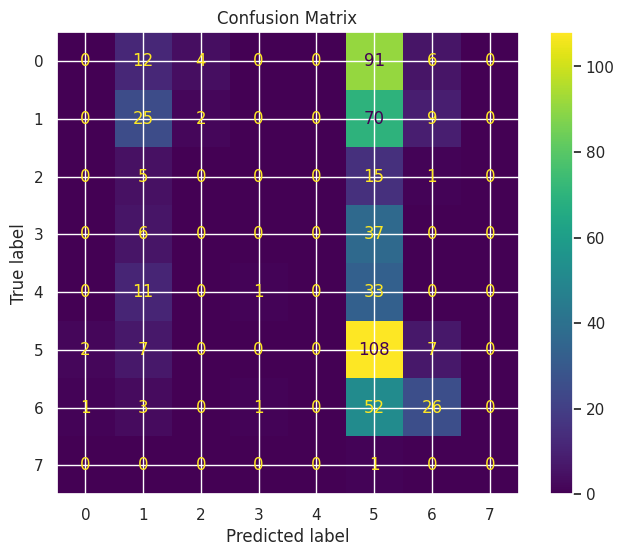

In [ ]:
# Teste CNN simples primeiro
modelo_cnn_teste = {
    'CNN_test': CNN1DClassifier(
        num_filters=[8],
        kernel_sizes=[3],
        dropout=0.3,
        fc_hidden_layers=(8,),
        learning_rate=0.0005,
        epochs=30,
        batch_size=16,
        random_state=42
    )
}

main(modelo_cnn_teste, "cnn_test")

verficart o codigo acima,
entender cada passo
fazs a validcao dos hiermatepros][link text](https://)**bold text**

In [ ]:
class CNN_LSTM_Hybrid(BaseEstimator, ClassifierMixin):
    """CNN para extrair features locais + LSTM para capturar dependências"""

    def __init__(self,
                 cnn_filters=[16, 32],
                 cnn_kernels=[3, 3],
                 cnn_dropout=0.2,
                 lstm_hidden=32,
                 lstm_layers=1,
                 lstm_dropout=0.2,
                 fc_hidden=(16,),
                 input_size=None,
                 output_size=8,
                 learning_rate=0.001,
                 epochs=100,
                 batch_size=32,
                 random_state=42,
                 device='cpu'):

        self.cnn_filters = cnn_filters
        self.cnn_kernels = cnn_kernels
        self.cnn_dropout = cnn_dropout
        self.lstm_hidden = lstm_hidden
        self.lstm_layers = lstm_layers
        self.lstm_dropout = lstm_dropout
        self.fc_hidden = fc_hidden
        self.input_size = input_size
        self.output_size = output_size
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.batch_size = batch_size
        self.random_state = random_state
        self.device = device if torch.cuda.is_available() else 'cpu'

        self.model = None
        self.optimizer = None
        self.criterion = None
        self.label_encoder = LabelEncoder()
        self.scaler = MinMaxScaler()

    def _build_model(self):
        class CNN_LSTM_Model(nn.Module):
            def __init__(self, input_size, cnn_filters, cnn_kernels, cnn_dropout,
                         lstm_hidden, lstm_layers, lstm_dropout, fc_hidden, output_size):
                super(CNN_LSTM_Model, self).__init__()

                # CNN Layers
                conv_layers = []
                prev_channels = 1

                for filters, kernel in zip(cnn_filters, cnn_kernels):
                    conv_layers.append(
                        nn.Conv1d(prev_channels, filters, kernel, padding='same')
                    )
                    conv_layers.append(nn.BatchNorm1d(filters))
                    conv_layers.append(nn.ReLU())
                    conv_layers.append(nn.MaxPool1d(2))
                    conv_layers.append(nn.Dropout(cnn_dropout))
                    prev_channels = filters

                self.conv_layers = nn.Sequential(*conv_layers)

                # Calcular tamanho após CNN
                cnn_out_size = input_size // (2 ** len(cnn_filters))

                # LSTM
                self.lstm = nn.LSTM(
                    input_size=prev_channels,
                    hidden_size=lstm_hidden,
                    num_layers=lstm_layers,
                    batch_first=True,
                    dropout=lstm_dropout if lstm_layers > 1 else 0
                )

                self.lstm_dropout = nn.Dropout(lstm_dropout)

                # Fully connected
                fc_layers = []
                prev_size = lstm_hidden

                for hidden in fc_hidden:
                    fc_layers.append(nn.Linear(prev_size, hidden))
                    fc_layers.append(nn.ReLU())
                    fc_layers.append(nn.Dropout(cnn_dropout))
                    prev_size = hidden

                fc_layers.append(nn.Linear(prev_size, output_size))
                self.fc_layers = nn.Sequential(*fc_layers)

            def forward(self, x):
                # CNN forward
                x = x.unsqueeze(1)  # (batch, 1, features)
                x = self.conv_layers(x)  # (batch, channels, features_cnn)

                # Reshape para LSTM: (batch, seq_len, features)
                x = x.permute(0, 2, 1)  # (batch, features_cnn, channels)

                # LSTM forward
                lstm_out, (hidden, cell) = self.lstm(x)
                last_hidden = hidden[-1]
                x = self.lstm_dropout(last_hidden)

                # Fully connected
                x = self.fc_layers(x)
                return x

        return CNN_LSTM_Model(
            input_size=self.input_size,
            cnn_filters=self.cnn_filters,
            cnn_kernels=self.cnn_kernels,
            cnn_dropout=self.cnn_dropout,
            lstm_hidden=self.lstm_hidden,
            lstm_layers=self.lstm_layers,
            lstm_dropout=self.lstm_dropout,
            fc_hidden=self.fc_hidden,
            output_size=self.output_size
        )

    def fit(self, X, y):
        # Converter para numpy
        if isinstance(X, pd.DataFrame):
            X = X.values
        if isinstance(y, (pd.Series, pd.DataFrame)):
            y = y.values

        # Salvar input_size
        if self.input_size is None:
            self.input_size = X.shape[1]

        # Escalar dados
        X_scaled = self.scaler.fit_transform(X)

        # Codificar labels
        y_encoded = self.label_encoder.fit_transform(y)
        self.output_size = len(self.label_encoder.classes_)

        # Construir modelo
        torch.manual_seed(self.random_state)
        self.model = self._build_model().to(self.device)

        # Configurar otimizador e loss
        self.optimizer = optim.Adam(self.model.parameters(), lr=self.learning_rate)
        self.criterion = nn.CrossEntropyLoss()

        # Preparar dados
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)
        y_tensor = torch.LongTensor(y_encoded).to(self.device)

        dataset = TensorDataset(X_tensor, y_tensor)
        dataloader = DataLoader(dataset, batch_size=self.batch_size, shuffle=True)

        # Treinamento
        self.model.train()
        for epoch in range(self.epochs):
            total_loss = 0
            for batch_X, batch_y in dataloader:
                self.optimizer.zero_grad()
                outputs = self.model(batch_X)
                loss = self.criterion(outputs, batch_y)
                loss.backward()
                self.optimizer.step()
                total_loss += loss.item()

            if (epoch + 1) % 20 == 0:
                print(f"Epoch {epoch+1}/{self.epochs}, Loss: {total_loss/len(dataloader):.4f}")

        return self

    def predict(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = self.model(X_tensor)
            _, predicted = torch.max(outputs, 1)

        return self.label_encoder.inverse_transform(predicted.cpu().numpy())

    def predict_proba(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = torch.softmax(self.model(X_tensor), dim=1)

        return outputs.cpu().numpy()

    def get_params(self, deep=True):
        return {
            'cnn_filters': self.cnn_filters,
            'cnn_kernels': self.cnn_kernels,
            'cnn_dropout': self.cnn_dropout,
            'lstm_hidden': self.lstm_hidden,
            'lstm_layers': self.lstm_layers,
            'lstm_dropout': self.lstm_dropout,
            'fc_hidden': self.fc_hidden,
            'input_size': self.input_size,
            'output_size': self.output_size,
            'learning_rate': self.learning_rate,
            'epochs': self.epochs,
            'batch_size': self.batch_size,
            'random_state': self.random_state
        }

    def set_params(self, **params):
        for key, value in params.items():
            setattr(self, key, value)
        return self

/tmp/ipykernel_5383/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)


Epoch 20/30, Loss: 1.7887


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 20/30, Loss: 1.7857
Epoch 20/30, Loss: 1.7892
Epoch 20/30, Loss: 1.7922
Epoch 20/30, Loss: 1.7953
Epoch 20/30, Loss: 1.7884

Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_LSTM_test
------------------------------
TRAIN
Accuracy: 0.3163
Precision: 0.2070
Recall: 0.3163
F1: 0.2406
Kappa: 0.1301
Error Rate: 0.6837

TEST
Accuracy: 0.2183
Precision: 0.0731
Recall: 0.2183
F1: 0.0984
Kappa: -0.0161
Error Rate: 0.7817
Gap (overfitting): 0.0980

CV
Mean: 0.3053
Std: 0.0186
------------------------------
Model params:
{'cnn_filters': [8, 16], 'cnn_kernels': [3, 3], 'cnn_dropout': 0.3, 'lstm_hidden': 16, 'lstm_layers': 1, 'lstm_dropout': 0.2, 'fc_hidden': (8,), 'input_size': 21, 'output_size': 8, 'learning_rate': 0.0005, 'epochs': 30, 'batch_size': 16, 'random_state': 42}



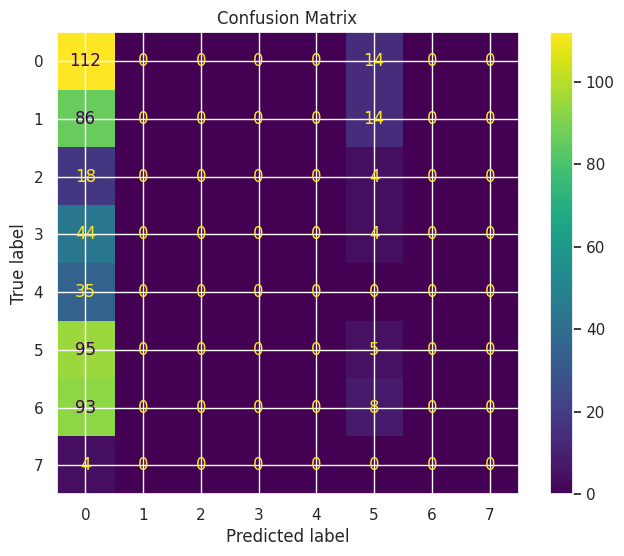

In [ ]:
modelo_cnn_lstm = {
    'CNN_LSTM_test': CNN_LSTM_Hybrid(
        cnn_filters=[8, 16],
        cnn_kernels=[3, 3],
        cnn_dropout=0.3,
        lstm_hidden=16,
        lstm_layers=1,
        lstm_dropout=0.2,
        fc_hidden=(8,),
        learning_rate=0.0005,
        epochs=30,
        batch_size=16,
        random_state=42
    )
}

main(modelo_cnn_lstm, "cnn_lstm_test")

verficart o codigo acima,
entender cada passo
fazs a validcao dos hiermatepros][link text](https://)**bold text** *italicized text*

In [ ]:
class RNNClassifier(BaseEstimator, ClassifierMixin):
    """RNN Clássica (Elman RNN) para dados sequenciais"""

    def __init__(self,
                 hidden_size=32,
                 num_layers=1,
                 dropout=0.2,
                 fc_hidden_layers=(16,),
                 input_size=None,
                 output_size=8,
                 nonlinearity='tanh',  # 'tanh' ou 'relu'
                 learning_rate=0.001,
                 epochs=100,
                 batch_size=32,
                 random_state=42,
                 device='cpu'):

        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.dropout = dropout
        self.fc_hidden_layers = fc_hidden_layers
        self.input_size = input_size
        self.output_size = output_size
        self.nonlinearity = nonlinearity
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.batch_size = batch_size
        self.random_state = random_state
        self.device = device if torch.cuda.is_available() else 'cpu'

        self.model = None
        self.optimizer = None
        self.criterion = None
        self.label_encoder = LabelEncoder()
        self.scaler = MinMaxScaler()

    def _build_model(self):
        class RNNModel(nn.Module):
            def __init__(self, input_size, hidden_size, num_layers, dropout,
                         nonlinearity, fc_hiddens, output_size):
                super(RNNModel, self).__init__()

                # Camada RNN (mais simples que LSTM)
                self.rnn = nn.RNN(
                    input_size=input_size,
                    hidden_size=hidden_size,
                    num_layers=num_layers,
                    batch_first=True,
                    dropout=dropout if num_layers > 1 else 0,
                    nonlinearity=nonlinearity
                )

                self.rnn_dropout = nn.Dropout(dropout)

                # Fully connected layers
                fc_layers = []
                prev_size = hidden_size

                for hidden in fc_hiddens:
                    fc_layers.append(nn.Linear(prev_size, hidden))
                    fc_layers.append(nn.ReLU())
                    fc_layers.append(nn.Dropout(dropout))
                    prev_size = hidden

                fc_layers.append(nn.Linear(prev_size, output_size))
                self.fc_layers = nn.Sequential(*fc_layers)

            def forward(self, x):
                # x shape: (batch, features)
                # Para RNN, precisa de (batch, seq_len, features)
                x = x.unsqueeze(1)  # seq_len = 1

                # RNN forward
                rnn_out, hidden = self.rnn(x)  # hidden: (num_layers, batch, hidden_size)

                # Pegar último hidden state
                last_hidden = hidden[-1]  # (batch, hidden_size)

                # Dropout
                out = self.rnn_dropout(last_hidden)

                # Fully connected
                out = self.fc_layers(out)

                return out

        return RNNModel(
            input_size=self.input_size,
            hidden_size=self.hidden_size,
            num_layers=self.num_layers,
            dropout=self.dropout,
            nonlinearity=self.nonlinearity,
            fc_hiddens=self.fc_hidden_layers,
            output_size=self.output_size
        )

    def fit(self, X, y):
        # Converter para numpy
        if isinstance(X, pd.DataFrame):
            X = X.values
        if isinstance(y, (pd.Series, pd.DataFrame)):
            y = y.values

        # Salvar input_size
        if self.input_size is None:
            self.input_size = X.shape[1]

        # Escalar dados
        X_scaled = self.scaler.fit_transform(X)

        # Codificar labels
        y_encoded = self.label_encoder.fit_transform(y)
        self.output_size = len(self.label_encoder.classes_)

        # Construir modelo
        torch.manual_seed(self.random_state)
        self.model = self._build_model().to(self.device)

        # Configurar otimizador e loss
        self.optimizer = optim.Adam(self.model.parameters(), lr=self.learning_rate)
        self.criterion = nn.CrossEntropyLoss()

        # Preparar dados
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)
        y_tensor = torch.LongTensor(y_encoded).to(self.device)

        dataset = TensorDataset(X_tensor, y_tensor)
        dataloader = DataLoader(dataset, batch_size=self.batch_size, shuffle=True)

        # Treinamento
        self.model.train()
        for epoch in range(self.epochs):
            total_loss = 0
            for batch_X, batch_y in dataloader:
                self.optimizer.zero_grad()
                outputs = self.model(batch_X)
                loss = self.criterion(outputs, batch_y)
                loss.backward()
                self.optimizer.step()
                total_loss += loss.item()

            if (epoch + 1) % 20 == 0:
                print(f"Epoch {epoch+1}/{self.epochs}, Loss: {total_loss/len(dataloader):.4f}")

        return self

    def predict(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = self.model(X_tensor)
            _, predicted = torch.max(outputs, 1)

        return self.label_encoder.inverse_transform(predicted.cpu().numpy())

    def predict_proba(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = torch.softmax(self.model(X_tensor), dim=1)

        return outputs.cpu().numpy()

    def get_params(self, deep=True):
        return {
            'hidden_size': self.hidden_size,
            'num_layers': self.num_layers,
            'dropout': self.dropout,
            'fc_hidden_layers': self.fc_hidden_layers,
            'input_size': self.input_size,
            'output_size': self.output_size,
            'nonlinearity': self.nonlinearity,
            'learning_rate': self.learning_rate,
            'epochs': self.epochs,
            'batch_size': self.batch_size,
            'random_state': self.random_state
        }

    def set_params(self, **params):
        for key, value in params.items():
            setattr(self, key, value)
        return self

In [ ]:
class BiRNNClassifier(BaseEstimator, ClassifierMixin):
    """RNN Bidirecional - captura contexto passado e futuro"""

    def __init__(self,
                 hidden_size=32,
                 num_layers=1,
                 dropout=0.2,
                 fc_hidden_layers=(16,),
                 input_size=None,
                 output_size=8,
                 learning_rate=0.001,
                 epochs=100,
                 batch_size=32,
                 random_state=42,
                 device='cpu'):

        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.dropout = dropout
        self.fc_hidden_layers = fc_hidden_layers
        self.input_size = input_size
        self.output_size = output_size
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.batch_size = batch_size
        self.random_state = random_state
        self.device = device if torch.cuda.is_available() else 'cpu'

        self.model = None
        self.optimizer = None
        self.criterion = None
        self.label_encoder = LabelEncoder()
        self.scaler = MinMaxScaler()

    def _build_model(self):
        class BiRNNModel(nn.Module):
            def __init__(self, input_size, hidden_size, num_layers, dropout,
                         fc_hiddens, output_size):
                super(BiRNNModel, self).__init__()

                # RNN Bidirecional
                self.rnn = nn.RNN(
                    input_size=input_size,
                    hidden_size=hidden_size,
                    num_layers=num_layers,
                    batch_first=True,
                    dropout=dropout if num_layers > 1 else 0,
                    bidirectional=True
                )

                self.rnn_dropout = nn.Dropout(dropout)

                # Bidirecional: 2 * hidden_size
                fc_layers = []
                prev_size = hidden_size * 2

                for hidden in fc_hiddens:
                    fc_layers.append(nn.Linear(prev_size, hidden))
                    fc_layers.append(nn.ReLU())
                    fc_layers.append(nn.Dropout(dropout))
                    prev_size = hidden

                fc_layers.append(nn.Linear(prev_size, output_size))
                self.fc_layers = nn.Sequential(*fc_layers)

            def forward(self, x):
                # x shape: (batch, features)
                x = x.unsqueeze(1)  # (batch, seq_len=1, features)

                # RNN forward
                rnn_out, hidden = self.rnn(x)
                # hidden: (num_layers * 2, batch, hidden_size)

                # Pegar últimas camadas forward e backward
                # hidden[-2] = forward, hidden[-1] = backward
                hidden_combined = torch.cat((hidden[-2], hidden[-1]), dim=1)

                out = self.rnn_dropout(hidden_combined)
                out = self.fc_layers(out)
                return out

        return BiRNNModel(
            input_size=self.input_size,
            hidden_size=self.hidden_size,
            num_layers=self.num_layers,
            dropout=self.dropout,
            fc_hiddens=self.fc_hidden_layers,
            output_size=self.output_size
        )

    def fit(self, X, y):
        # Converter para numpy
        if isinstance(X, pd.DataFrame):
            X = X.values
        if isinstance(y, (pd.Series, pd.DataFrame)):
            y = y.values

        # Salvar input_size
        if self.input_size is None:
            self.input_size = X.shape[1]

        # Escalar dados
        X_scaled = self.scaler.fit_transform(X)

        # Codificar labels
        y_encoded = self.label_encoder.fit_transform(y)
        self.output_size = len(self.label_encoder.classes_)

        # Construir modelo
        torch.manual_seed(self.random_state)
        self.model = self._build_model().to(self.device)

        # Configurar otimizador e loss
        self.optimizer = optim.Adam(self.model.parameters(), lr=self.learning_rate)
        self.criterion = nn.CrossEntropyLoss()

        # Preparar dados
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)
        y_tensor = torch.LongTensor(y_encoded).to(self.device)

        dataset = TensorDataset(X_tensor, y_tensor)
        dataloader = DataLoader(dataset, batch_size=self.batch_size, shuffle=True)

        # Treinamento
        self.model.train()
        for epoch in range(self.epochs):
            total_loss = 0
            for batch_X, batch_y in dataloader:
                self.optimizer.zero_grad()
                outputs = self.model(batch_X)
                loss = self.criterion(outputs, batch_y)
                loss.backward()
                self.optimizer.step()
                total_loss += loss.item()

            if (epoch + 1) % 20 == 0:
                print(f"Epoch {epoch+1}/{self.epochs}, Loss: {total_loss/len(dataloader):.4f}")

        return self

    def predict(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = self.model(X_tensor)
            _, predicted = torch.max(outputs, 1)

        return self.label_encoder.inverse_transform(predicted.cpu().numpy())

    def predict_proba(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = torch.softmax(self.model(X_tensor), dim=1)

        return outputs.cpu().numpy()

    def get_params(self, deep=True):
        return {
            'hidden_size': self.hidden_size,
            'num_layers': self.num_layers,
            'dropout': self.dropout,
            'fc_hidden_layers': self.fc_hidden_layers,
            'input_size': self.input_size,
            'output_size': self.output_size,
            'learning_rate': self.learning_rate,
            'epochs': self.epochs,
            'batch_size': self.batch_size,
            'random_state': self.random_state
        }

    def set_params(self, **params):
        for key, value in params.items():
            setattr(self, key, value)
        return self

In [ ]:
models_rnn = {}

# RNN pequena - recomendada para começar
models_rnn['RNN_tiny'] = RNNClassifier(
    hidden_size=8,
    num_layers=1,
    dropout=0.3,
    fc_hidden_layers=(8,),
    nonlinearity='tanh',
    learning_rate=0.0005,
    epochs=30,
    batch_size=16,
    random_state=42
)


/tmp/ipykernel_5383/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)


Epoch 20/30, Loss: 1.8483


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 20/30, Loss: 1.8381
Epoch 20/30, Loss: 1.8358
Epoch 20/30, Loss: 1.8532
Epoch 20/30, Loss: 1.8548
Epoch 20/30, Loss: 1.8478

Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_tiny
------------------------------
TRAIN
Accuracy: 0.3211
Precision: 0.2082
Recall: 0.3211
F1: 0.2382
Kappa: 0.1370
Error Rate: 0.6789

TEST
Accuracy: 0.1791
Precision: 0.3065
Recall: 0.1791
F1: 0.1080
Kappa: 0.0153
Error Rate: 0.8209
Gap (overfitting): 0.1420

CV
Mean: 0.3412
Std: 0.0320
------------------------------
Model params:
{'hidden_size': 8, 'num_layers': 1, 'dropout': 0.3, 'fc_hidden_layers': (8,), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'learning_rate': 0.0005, 'epochs': 30, 'batch_size': 16, 'random_state': 42}



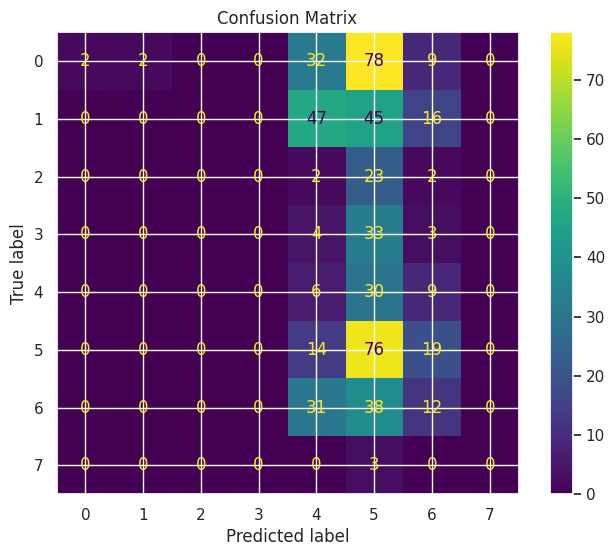

In [ ]:
main(models_rnn, "rnn_test")

In [ ]:
class GRUClassifier(BaseEstimator, ClassifierMixin):
    """GRU (Gated Recurrent Unit) - Meio termo entre RNN e LSTM"""

    def __init__(self,
                 hidden_size=32,
                 num_layers=1,
                 dropout=0.2,
                 fc_hidden_layers=(16,),
                 input_size=None,
                 output_size=8,
                 learning_rate=0.001,
                 epochs=100,
                 batch_size=32,
                 random_state=42,
                 device='cpu'):

        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.dropout = dropout
        self.fc_hidden_layers = fc_hidden_layers
        self.input_size = input_size
        self.output_size = output_size
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.batch_size = batch_size
        self.random_state = random_state
        self.device = device if torch.cuda.is_available() else 'cpu'

        self.model = None
        self.optimizer = None
        self.criterion = None
        self.label_encoder = LabelEncoder()
        self.scaler = MinMaxScaler()

    def _build_model(self):
        class GRUModel(nn.Module):
            def __init__(self, input_size, hidden_size, num_layers, dropout,
                         fc_hiddens, output_size):
                super(GRUModel, self).__init__()

                self.gru = nn.GRU(
                    input_size=input_size,
                    hidden_size=hidden_size,
                    num_layers=num_layers,
                    batch_first=True,
                    dropout=dropout if num_layers > 1 else 0
                )

                self.gru_dropout = nn.Dropout(dropout)

                fc_layers = []
                prev_size = hidden_size

                for hidden in fc_hiddens:
                    fc_layers.append(nn.Linear(prev_size, hidden))
                    fc_layers.append(nn.ReLU())
                    fc_layers.append(nn.Dropout(dropout))
                    prev_size = hidden

                fc_layers.append(nn.Linear(prev_size, output_size))
                self.fc_layers = nn.Sequential(*fc_layers)

            def forward(self, x):
                x = x.unsqueeze(1)  # (batch, seq_len=1, features)
                gru_out, hidden = self.gru(x)
                last_hidden = hidden[-1]  # (batch, hidden_size)
                out = self.gru_dropout(last_hidden)
                out = self.fc_layers(out)
                return out

        return GRUModel(
            input_size=self.input_size,
            hidden_size=self.hidden_size,
            num_layers=self.num_layers,
            dropout=self.dropout,
            fc_hiddens=self.fc_hidden_layers,
            output_size=self.output_size
        )

    def fit(self, X, y):
        # Converter para numpy
        if isinstance(X, pd.DataFrame):
            X = X.values
        if isinstance(y, (pd.Series, pd.DataFrame)):
            y = y.values

        # Salvar input_size
        if self.input_size is None:
            self.input_size = X.shape[1]

        # Escalar dados
        X_scaled = self.scaler.fit_transform(X)

        # Codificar labels
        y_encoded = self.label_encoder.fit_transform(y)
        self.output_size = len(self.label_encoder.classes_)

        # Construir modelo
        torch.manual_seed(self.random_state)
        self.model = self._build_model().to(self.device)

        # Configurar otimizador e loss
        self.optimizer = optim.Adam(self.model.parameters(), lr=self.learning_rate)
        self.criterion = nn.CrossEntropyLoss()

        # Preparar dados
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)
        y_tensor = torch.LongTensor(y_encoded).to(self.device)

        dataset = TensorDataset(X_tensor, y_tensor)
        dataloader = DataLoader(dataset, batch_size=self.batch_size, shuffle=True)

        # Treinamento
        self.model.train()
        for epoch in range(self.epochs):
            total_loss = 0
            for batch_X, batch_y in dataloader:
                self.optimizer.zero_grad()
                outputs = self.model(batch_X)
                loss = self.criterion(outputs, batch_y)
                loss.backward()
                self.optimizer.step()
                total_loss += loss.item()

            if (epoch + 1) % 20 == 0:
                print(f"Epoch {epoch+1}/{self.epochs}, Loss: {total_loss/len(dataloader):.4f}")

        return self

    def predict(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = self.model(X_tensor)
            _, predicted = torch.max(outputs, 1)

        return self.label_encoder.inverse_transform(predicted.cpu().numpy())

    def predict_proba(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = torch.softmax(self.model(X_tensor), dim=1)

        return outputs.cpu().numpy()

    def get_params(self, deep=True):
        return {
            'hidden_size': self.hidden_size,
            'num_layers': self.num_layers,
            'dropout': self.dropout,
            'fc_hidden_layers': self.fc_hidden_layers,
            'input_size': self.input_size,
            'output_size': self.output_size,
            'learning_rate': self.learning_rate,
            'epochs': self.epochs,
            'batch_size': self.batch_size,
            'random_state': self.random_state
        }

    def set_params(self, **params):
        for key, value in params.items():
            setattr(self, key, value)
        return self

/tmp/ipykernel_5383/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)


Epoch 20/30, Loss: 1.7860


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 20/30, Loss: 1.7348
Epoch 20/30, Loss: 1.7298
Epoch 20/30, Loss: 1.7418
Epoch 20/30, Loss: 1.7489
Epoch 20/30, Loss: 1.7388

Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: BiRNN_tiny
------------------------------
TRAIN
Accuracy: 0.3859
Precision: 0.2894
Recall: 0.3859
F1: 0.3010
Kappa: 0.2210
Error Rate: 0.6141

TEST
Accuracy: 0.1959
Precision: 0.1410
Recall: 0.1959
F1: 0.0970
Kappa: 0.0063
Error Rate: 0.8041
Gap (overfitting): 0.1900

CV
Mean: 0.4050
Std: 0.0352
------------------------------
Model params:
{'hidden_size': 8, 'num_layers': 1, 'dropout': 0.3, 'fc_hidden_layers': (8,), 'input_size': 21, 'output_size': 8, 'learning_rate': 0.0005, 'epochs': 30, 'batch_size': 16, 'random_state': 42}



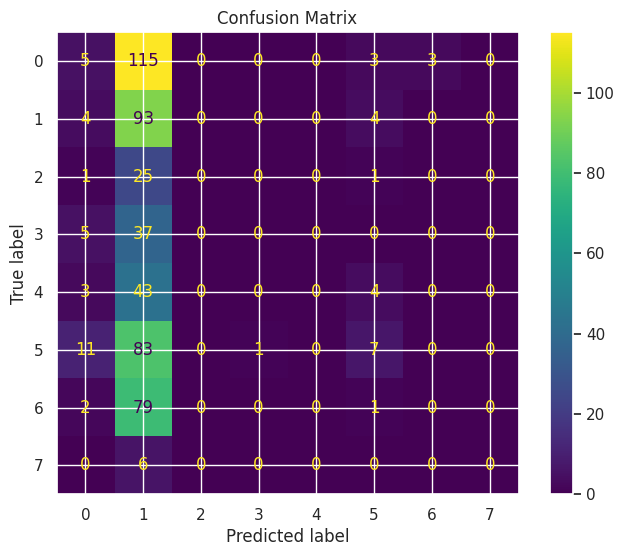

/tmp/ipykernel_5383/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)


Epoch 20/30, Loss: 1.7953


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 20/30, Loss: 1.7699
Epoch 20/30, Loss: 1.7696
Epoch 20/30, Loss: 1.7645
Epoch 20/30, Loss: 1.7647
Epoch 20/30, Loss: 1.7733

Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: GRU_tiny
------------------------------
TRAIN
Accuracy: 0.2858
Precision: 0.1231
Recall: 0.2858
F1: 0.1701
Kappa: 0.0935
Error Rate: 0.7142

TEST
Accuracy: 0.1549
Precision: 0.1890
Recall: 0.1549
F1: 0.0756
Kappa: -0.0412
Error Rate: 0.8451
Gap (overfitting): 0.1310

CV
Mean: 0.2908
Std: 0.0228
------------------------------
Model params:
{'hidden_size': 8, 'num_layers': 1, 'dropout': 0.3, 'fc_hidden_layers': (8,), 'input_size': 21, 'output_size': 8, 'learning_rate': 0.0005, 'epochs': 30, 'batch_size': 16, 'random_state': 42}



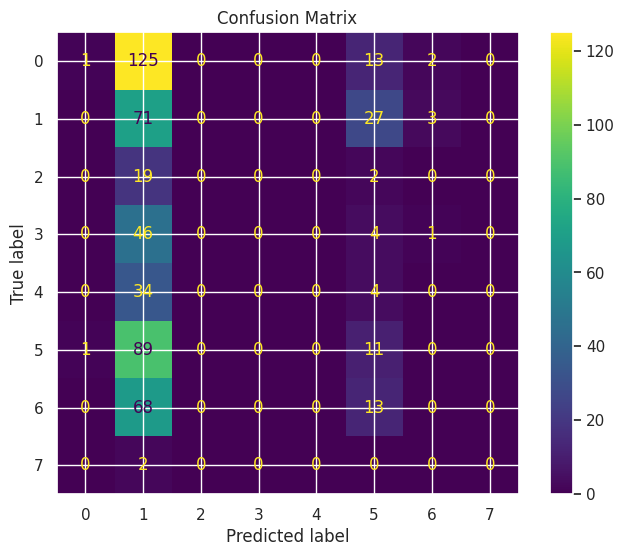

In [ ]:
# RNN Bidirecional pequena
models_birnn = {
    'BiRNN_tiny': BiRNNClassifier(
        hidden_size=8,
        num_layers=1,
        dropout=0.3,
        fc_hidden_layers=(8,),
        learning_rate=0.0005,
        epochs=30,
        batch_size=16,
        random_state=42
    )
}

# GRU pequena
models_gru = {
    'GRU_tiny': GRUClassifier(
        hidden_size=8,
        num_layers=1,
        dropout=0.3,
        fc_hidden_layers=(8,),
        learning_rate=0.0005,
        epochs=30,
        batch_size=16,
        random_state=42
    )
}

# Testar
main(models_birnn, "birnn_test")
main(models_gru, "gru_test")

verficart o codigo acima,
entender cada passo
fazs a validcao dos hiermatepros][link text](https://)**bold text** *italicized text*

In [ ]:
class MLP_GRU_Hybrid(BaseEstimator, ClassifierMixin):
    """MLP para extrair features + GRU para capturar dependências"""

    def __init__(self,
                 mlp_hidden_layers=(32, 16),
                 mlp_dropout=0.2,
                 gru_hidden=32,
                 gru_layers=1,
                 gru_dropout=0.2,
                 fc_hidden=(16,),
                 input_size=None,
                 output_size=8,
                 learning_rate=0.001,
                 epochs=100,
                 batch_size=32,
                 random_state=42,
                 device='cpu'):

        self.mlp_hidden_layers = mlp_hidden_layers
        self.mlp_dropout = mlp_dropout
        self.gru_hidden = gru_hidden
        self.gru_layers = gru_layers
        self.gru_dropout = gru_dropout
        self.fc_hidden = fc_hidden
        self.input_size = input_size
        self.output_size = output_size
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.batch_size = batch_size
        self.random_state = random_state
        self.device = device if torch.cuda.is_available() else 'cpu'

        self.model = None
        self.optimizer = None
        self.criterion = None
        self.label_encoder = LabelEncoder()
        self.scaler = MinMaxScaler()

    def _build_model(self):
        class MLP_GRU_Model(nn.Module):
            def __init__(self, input_size, mlp_hiddens, mlp_dropout,
                         gru_hidden, gru_layers, gru_dropout, fc_hidden, output_size):
                super(MLP_GRU_Model, self).__init__()

                # MLP para transformar features
                mlp_layers = []
                prev_size = input_size

                for hidden in mlp_hiddens:
                    mlp_layers.append(nn.Linear(prev_size, hidden))
                    mlp_layers.append(nn.ReLU())
                    mlp_layers.append(nn.Dropout(mlp_dropout))
                    prev_size = hidden

                self.mlp = nn.Sequential(*mlp_layers)

                # GRU
                self.gru = nn.GRU(
                    input_size=prev_size,
                    hidden_size=gru_hidden,
                    num_layers=gru_layers,
                    batch_first=True,
                    dropout=gru_dropout if gru_layers > 1 else 0
                )

                self.gru_dropout = nn.Dropout(gru_dropout)

                # Fully connected final
                fc_layers = []
                prev_size = gru_hidden

                for hidden in fc_hidden:
                    fc_layers.append(nn.Linear(prev_size, hidden))
                    fc_layers.append(nn.ReLU())
                    fc_layers.append(nn.Dropout(mlp_dropout))
                    prev_size = hidden

                fc_layers.append(nn.Linear(prev_size, output_size))
                self.fc = nn.Sequential(*fc_layers)

            def forward(self, x):
                # MLP
                x = self.mlp(x)

                # Reshape para GRU
                x = x.unsqueeze(1)  # (batch, seq_len=1, features)

                # GRU
                gru_out, hidden = self.gru(x)
                last_hidden = hidden[-1]

                # Dropout e FC
                x = self.gru_dropout(last_hidden)
                x = self.fc(x)
                return x

        return MLP_GRU_Model(
            input_size=self.input_size,
            mlp_hiddens=self.mlp_hidden_layers,
            mlp_dropout=self.mlp_dropout,
            gru_hidden=self.gru_hidden,
            gru_layers=self.gru_layers,
            gru_dropout=self.gru_dropout,
            fc_hidden=self.fc_hidden,
            output_size=self.output_size
        )

    def fit(self, X, y):
        if isinstance(X, pd.DataFrame):
            X = X.values
        if isinstance(y, (pd.Series, pd.DataFrame)):
            y = y.values

        if self.input_size is None:
            self.input_size = X.shape[1]

        X_scaled = self.scaler.fit_transform(X)
        y_encoded = self.label_encoder.fit_transform(y)
        self.output_size = len(self.label_encoder.classes_)

        torch.manual_seed(self.random_state)
        self.model = self._build_model().to(self.device)

        self.optimizer = optim.Adam(self.model.parameters(), lr=self.learning_rate)
        self.criterion = nn.CrossEntropyLoss()

        X_tensor = torch.FloatTensor(X_scaled).to(self.device)
        y_tensor = torch.LongTensor(y_encoded).to(self.device)

        dataset = TensorDataset(X_tensor, y_tensor)
        dataloader = DataLoader(dataset, batch_size=self.batch_size, shuffle=True)

        self.model.train()
        for epoch in range(self.epochs):
            total_loss = 0
            for batch_X, batch_y in dataloader:
                self.optimizer.zero_grad()
                outputs = self.model(batch_X)
                loss = self.criterion(outputs, batch_y)
                loss.backward()
                self.optimizer.step()
                total_loss += loss.item()

            if (epoch + 1) % 20 == 0:
                print(f"Epoch {epoch+1}/{self.epochs}, Loss: {total_loss/len(dataloader):.4f}")

        return self

    def predict(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = self.model(X_tensor)
            _, predicted = torch.max(outputs, 1)

        return self.label_encoder.inverse_transform(predicted.cpu().numpy())

    def predict_proba(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = torch.softmax(self.model(X_tensor), dim=1)

        return outputs.cpu().numpy()

    def get_params(self, deep=True):
        return {
            'mlp_hidden_layers': self.mlp_hidden_layers,
            'mlp_dropout': self.mlp_dropout,
            'gru_hidden': self.gru_hidden,
            'gru_layers': self.gru_layers,
            'gru_dropout': self.gru_dropout,
            'fc_hidden': self.fc_hidden,
            'input_size': self.input_size,
            'output_size': self.output_size,
            'learning_rate': self.learning_rate,
            'epochs': self.epochs,
            'batch_size': self.batch_size,
            'random_state': self.random_state
        }

    def set_params(self, **params):
        for key, value in params.items():
            setattr(self, key, value)
        return self

In [ ]:
class CNN_GRU_Hybrid(BaseEstimator, ClassifierMixin):
    """CNN para extrair padrões locais + GRU para dependências temporais"""

    def __init__(self,
                 cnn_filters=[16, 32],
                 cnn_kernels=[3, 3],
                 cnn_dropout=0.2,
                 gru_hidden=32,
                 gru_layers=1,
                 gru_dropout=0.2,
                 fc_hidden=(16,),
                 input_size=None,
                 output_size=8,
                 learning_rate=0.001,
                 epochs=100,
                 batch_size=32,
                 random_state=42,
                 device='cpu'):

        self.cnn_filters = cnn_filters
        self.cnn_kernels = cnn_kernels
        self.cnn_dropout = cnn_dropout
        self.gru_hidden = gru_hidden
        self.gru_layers = gru_layers
        self.gru_dropout = gru_dropout
        self.fc_hidden = fc_hidden
        self.input_size = input_size
        self.output_size = output_size
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.batch_size = batch_size
        self.random_state = random_state
        self.device = device if torch.cuda.is_available() else 'cpu'

        self.model = None
        self.optimizer = None
        self.criterion = None
        self.label_encoder = LabelEncoder()
        self.scaler = MinMaxScaler()

    def _build_model(self):
        class CNN_GRU_Model(nn.Module):
            def __init__(self, input_size, cnn_filters, cnn_kernels, cnn_dropout,
                         gru_hidden, gru_layers, gru_dropout, fc_hidden, output_size):
                super(CNN_GRU_Model, self).__init__()

                # CNN Layers
                conv_layers = []
                prev_channels = 1

                for filters, kernel in zip(cnn_filters, cnn_kernels):
                    conv_layers.append(
                        nn.Conv1d(prev_channels, filters, kernel, padding='same')
                    )
                    conv_layers.append(nn.BatchNorm1d(filters))
                    conv_layers.append(nn.ReLU())
                    conv_layers.append(nn.MaxPool1d(2))
                    conv_layers.append(nn.Dropout(cnn_dropout))
                    prev_channels = filters

                self.conv_layers = nn.Sequential(*conv_layers)

                # GRU
                self.gru = nn.GRU(
                    input_size=prev_channels,
                    hidden_size=gru_hidden,
                    num_layers=gru_layers,
                    batch_first=True,
                    dropout=gru_dropout if gru_layers > 1 else 0
                )

                self.gru_dropout = nn.Dropout(gru_dropout)

                # Fully connected
                fc_layers = []
                prev_size = gru_hidden

                for hidden in fc_hidden:
                    fc_layers.append(nn.Linear(prev_size, hidden))
                    fc_layers.append(nn.ReLU())
                    fc_layers.append(nn.Dropout(cnn_dropout))
                    prev_size = hidden

                fc_layers.append(nn.Linear(prev_size, output_size))
                self.fc = nn.Sequential(*fc_layers)

            def forward(self, x):
                # CNN
                x = x.unsqueeze(1)  # (batch, 1, features)
                x = self.conv_layers(x)  # (batch, channels, features_cnn)

                # Reshape para GRU
                x = x.permute(0, 2, 1)  # (batch, features_cnn, channels)

                # GRU
                gru_out, hidden = self.gru(x)
                last_hidden = hidden[-1]

                # Dropout e FC
                x = self.gru_dropout(last_hidden)
                x = self.fc(x)
                return x

        return CNN_GRU_Model(
            input_size=self.input_size,
            cnn_filters=self.cnn_filters,
            cnn_kernels=self.cnn_kernels,
            cnn_dropout=self.cnn_dropout,
            gru_hidden=self.gru_hidden,
            gru_layers=self.gru_layers,
            gru_dropout=self.gru_dropout,
            fc_hidden=self.fc_hidden,
            output_size=self.output_size
        )

    # fit, predict, predict_proba (mesmo padrão do MLP_GRU_Hybrid)
    def fit(self, X, y):
        if isinstance(X, pd.DataFrame):
            X = X.values
        if isinstance(y, (pd.Series, pd.DataFrame)):
            y = y.values

        if self.input_size is None:
            self.input_size = X.shape[1]

        X_scaled = self.scaler.fit_transform(X)
        y_encoded = self.label_encoder.fit_transform(y)
        self.output_size = len(self.label_encoder.classes_)

        torch.manual_seed(self.random_state)
        self.model = self._build_model().to(self.device)

        self.optimizer = optim.Adam(self.model.parameters(), lr=self.learning_rate)
        self.criterion = nn.CrossEntropyLoss()

        X_tensor = torch.FloatTensor(X_scaled).to(self.device)
        y_tensor = torch.LongTensor(y_encoded).to(self.device)

        dataset = TensorDataset(X_tensor, y_tensor)
        dataloader = DataLoader(dataset, batch_size=self.batch_size, shuffle=True)

        self.model.train()
        for epoch in range(self.epochs):
            total_loss = 0
            for batch_X, batch_y in dataloader:
                self.optimizer.zero_grad()
                outputs = self.model(batch_X)
                loss = self.criterion(outputs, batch_y)
                loss.backward()
                self.optimizer.step()
                total_loss += loss.item()

            if (epoch + 1) % 20 == 0:
                print(f"Epoch {epoch+1}/{self.epochs}, Loss: {total_loss/len(dataloader):.4f}")

        return self

    def predict(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = self.model(X_tensor)
            _, predicted = torch.max(outputs, 1)

        return self.label_encoder.inverse_transform(predicted.cpu().numpy())

    def predict_proba(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = torch.softmax(self.model(X_tensor), dim=1)

        return outputs.cpu().numpy()

    def get_params(self, deep=True):
        return {
            'cnn_filters': self.cnn_filters,
            'cnn_kernels': self.cnn_kernels,
            'cnn_dropout': self.cnn_dropout,
            'gru_hidden': self.gru_hidden,
            'gru_layers': self.gru_layers,
            'gru_dropout': self.gru_dropout,
            'fc_hidden': self.fc_hidden,
            'input_size': self.input_size,
            'output_size': self.output_size,
            'learning_rate': self.learning_rate,
            'epochs': self.epochs,
            'batch_size': self.batch_size,
            'random_state': self.random_state
        }

    def set_params(self, **params):
        for key, value in params.items():
            setattr(self, key, value)
        return self

In [ ]:
class RNN_GRU_Hybrid(BaseEstimator, ClassifierMixin):
    """RNN + GRU empilhadas (duas camadas recorrentes diferentes)"""

    def __init__(self,
                 rnn_hidden=16,
                 rnn_layers=1,
                 rnn_dropout=0.2,
                 gru_hidden=16,
                 gru_layers=1,
                 gru_dropout=0.2,
                 fc_hidden=(8,),
                 input_size=None,
                 output_size=8,
                 learning_rate=0.001,
                 epochs=100,
                 batch_size=32,
                 random_state=42,
                 device='cpu'):

        self.rnn_hidden = rnn_hidden
        self.rnn_layers = rnn_layers
        self.rnn_dropout = rnn_dropout
        self.gru_hidden = gru_hidden
        self.gru_layers = gru_layers
        self.gru_dropout = gru_dropout
        self.fc_hidden = fc_hidden
        self.input_size = input_size
        self.output_size = output_size
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.batch_size = batch_size
        self.random_state = random_state
        self.device = device if torch.cuda.is_available() else 'cpu'

        self.model = None
        self.optimizer = None
        self.criterion = None
        self.label_encoder = LabelEncoder()
        self.scaler = MinMaxScaler()

    def _build_model(self):
        class RNN_GRU_Model(nn.Module):
            def __init__(self, input_size, rnn_hidden, rnn_layers, rnn_dropout,
                         gru_hidden, gru_layers, gru_dropout, fc_hidden, output_size):
                super(RNN_GRU_Model, self).__init__()

                # Primeira camada: RNN
                self.rnn = nn.RNN(
                    input_size=input_size,
                    hidden_size=rnn_hidden,
                    num_layers=rnn_layers,
                    batch_first=True,
                    dropout=rnn_dropout if rnn_layers > 1 else 0,
                    nonlinearity='tanh'
                )

                self.rnn_dropout = nn.Dropout(rnn_dropout)

                # Segunda camada: GRU
                self.gru = nn.GRU(
                    input_size=rnn_hidden,
                    hidden_size=gru_hidden,
                    num_layers=gru_layers,
                    batch_first=True,
                    dropout=gru_dropout if gru_layers > 1 else 0
                )

                self.gru_dropout = nn.Dropout(gru_dropout)

                # Fully connected
                fc_layers = []
                prev_size = gru_hidden

                for hidden in fc_hidden:
                    fc_layers.append(nn.Linear(prev_size, hidden))
                    fc_layers.append(nn.ReLU())
                    fc_layers.append(nn.Dropout(rnn_dropout))
                    prev_size = hidden

                fc_layers.append(nn.Linear(prev_size, output_size))
                self.fc = nn.Sequential(*fc_layers)

            def forward(self, x):
                x = x.unsqueeze(1)  # (batch, seq_len=1, features)

                # RNN
                rnn_out, hidden_rnn = self.rnn(x)
                last_hidden_rnn = hidden_rnn[-1]  # (batch, rnn_hidden)
                x = self.rnn_dropout(last_hidden_rnn)

                # Reshape para GRU
                x = x.unsqueeze(1)  # (batch, 1, rnn_hidden)

                # GRU
                gru_out, hidden_gru = self.gru(x)
                last_hidden_gru = hidden_gru[-1]  # (batch, gru_hidden)

                x = self.gru_dropout(last_hidden_gru)
                x = self.fc(x)
                return x

        return RNN_GRU_Model(
            input_size=self.input_size,
            rnn_hidden=self.rnn_hidden,
            rnn_layers=self.rnn_layers,
            rnn_dropout=self.rnn_dropout,
            gru_hidden=self.gru_hidden,
            gru_layers=self.gru_layers,
            gru_dropout=self.gru_dropout,
            fc_hidden=self.fc_hidden,
            output_size=self.output_size
        )

    # fit, predict, predict_proba (mesmo padrão)
    def fit(self, X, y):
        if isinstance(X, pd.DataFrame):
            X = X.values
        if isinstance(y, (pd.Series, pd.DataFrame)):
            y = y.values

        if self.input_size is None:
            self.input_size = X.shape[1]

        X_scaled = self.scaler.fit_transform(X)
        y_encoded = self.label_encoder.fit_transform(y)
        self.output_size = len(self.label_encoder.classes_)

        torch.manual_seed(self.random_state)
        self.model = self._build_model().to(self.device)

        self.optimizer = optim.Adam(self.model.parameters(), lr=self.learning_rate)
        self.criterion = nn.CrossEntropyLoss()

        X_tensor = torch.FloatTensor(X_scaled).to(self.device)
        y_tensor = torch.LongTensor(y_encoded).to(self.device)

        dataset = TensorDataset(X_tensor, y_tensor)
        dataloader = DataLoader(dataset, batch_size=self.batch_size, shuffle=True)

        self.model.train()
        for epoch in range(self.epochs):
            total_loss = 0
            for batch_X, batch_y in dataloader:
                self.optimizer.zero_grad()
                outputs = self.model(batch_X)
                loss = self.criterion(outputs, batch_y)
                loss.backward()
                self.optimizer.step()
                total_loss += loss.item()

            if (epoch + 1) % 20 == 0:
                print(f"Epoch {epoch+1}/{self.epochs}, Loss: {total_loss/len(dataloader):.4f}")

        return self

    def predict(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = self.model(X_tensor)
            _, predicted = torch.max(outputs, 1)

        return self.label_encoder.inverse_transform(predicted.cpu().numpy())

    def predict_proba(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = torch.softmax(self.model(X_tensor), dim=1)

        return outputs.cpu().numpy()

    def get_params(self, deep=True):
        return {
            'rnn_hidden': self.rnn_hidden,
            'rnn_layers': self.rnn_layers,
            'rnn_dropout': self.rnn_dropout,
            'gru_hidden': self.gru_hidden,
            'gru_layers': self.gru_layers,
            'gru_dropout': self.gru_dropout,
            'fc_hidden': self.fc_hidden,
            'input_size': self.input_size,
            'output_size': self.output_size,
            'learning_rate': self.learning_rate,
            'epochs': self.epochs,
            'batch_size': self.batch_size,
            'random_state': self.random_state
        }

    def set_params(self, **params):
        for key, value in params.items():
            setattr(self, key, value)
        return self

In [ ]:
class RNN_LSTM_Hybrid(BaseEstimator, ClassifierMixin):
    """RNN + LSTM empilhadas (combina simplicidade da RNN com complexidade da LSTM)"""

    def __init__(self,
                 rnn_hidden=16,
                 rnn_layers=1,
                 rnn_dropout=0.2,
                 lstm_hidden=16,
                 lstm_layers=1,
                 lstm_dropout=0.2,
                 fc_hidden=(8,),
                 input_size=None,
                 output_size=8,
                 learning_rate=0.001,
                 epochs=100,
                 batch_size=32,
                 random_state=42,
                 device='cpu'):

        self.rnn_hidden = rnn_hidden
        self.rnn_layers = rnn_layers
        self.rnn_dropout = rnn_dropout
        self.lstm_hidden = lstm_hidden
        self.lstm_layers = lstm_layers
        self.lstm_dropout = lstm_dropout
        self.fc_hidden = fc_hidden
        self.input_size = input_size
        self.output_size = output_size
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.batch_size = batch_size
        self.random_state = random_state
        self.device = device if torch.cuda.is_available() else 'cpu'

        self.model = None
        self.optimizer = None
        self.criterion = None
        self.label_encoder = LabelEncoder()
        self.scaler = MinMaxScaler()

    def _build_model(self):
        class RNN_LSTM_Model(nn.Module):
            def __init__(self, input_size, rnn_hidden, rnn_layers, rnn_dropout,
                         lstm_hidden, lstm_layers, lstm_dropout, fc_hidden, output_size):
                super(RNN_LSTM_Model, self).__init__()

                # Primeira camada: RNN
                self.rnn = nn.RNN(
                    input_size=input_size,
                    hidden_size=rnn_hidden,
                    num_layers=rnn_layers,
                    batch_first=True,
                    dropout=rnn_dropout if rnn_layers > 1 else 0,
                    nonlinearity='tanh'
                )

                self.rnn_dropout = nn.Dropout(rnn_dropout)

                # Segunda camada: LSTM
                self.lstm = nn.LSTM(
                    input_size=rnn_hidden,
                    hidden_size=lstm_hidden,
                    num_layers=lstm_layers,
                    batch_first=True,
                    dropout=lstm_dropout if lstm_layers > 1 else 0
                )

                self.lstm_dropout = nn.Dropout(lstm_dropout)

                # Fully connected
                fc_layers = []
                prev_size = lstm_hidden

                for hidden in fc_hidden:
                    fc_layers.append(nn.Linear(prev_size, hidden))
                    fc_layers.append(nn.ReLU())
                    fc_layers.append(nn.Dropout(rnn_dropout))
                    prev_size = hidden

                fc_layers.append(nn.Linear(prev_size, output_size))
                self.fc = nn.Sequential(*fc_layers)

            def forward(self, x):
                x = x.unsqueeze(1)  # (batch, seq_len=1, features)

                # RNN
                rnn_out, hidden_rnn = self.rnn(x)
                last_hidden_rnn = hidden_rnn[-1]
                x = self.rnn_dropout(last_hidden_rnn)

                # Reshape para LSTM
                x = x.unsqueeze(1)  # (batch, 1, rnn_hidden)

                # LSTM
                lstm_out, (hidden_lstm, cell) = self.lstm(x)
                last_hidden_lstm = hidden_lstm[-1]

                x = self.lstm_dropout(last_hidden_lstm)
                x = self.fc(x)
                return x

        return RNN_LSTM_Model(
            input_size=self.input_size,
            rnn_hidden=self.rnn_hidden,
            rnn_layers=self.rnn_layers,
            rnn_dropout=self.rnn_dropout,
            lstm_hidden=self.lstm_hidden,
            lstm_layers=self.lstm_layers,
            lstm_dropout=self.lstm_dropout,
            fc_hidden=self.fc_hidden,
            output_size=self.output_size
        )

    # fit, predict, predict_proba (mesmo padrão)
    def fit(self, X, y):
        if isinstance(X, pd.DataFrame):
            X = X.values
        if isinstance(y, (pd.Series, pd.DataFrame)):
            y = y.values

        if self.input_size is None:
            self.input_size = X.shape[1]

        X_scaled = self.scaler.fit_transform(X)
        y_encoded = self.label_encoder.fit_transform(y)
        self.output_size = len(self.label_encoder.classes_)

        torch.manual_seed(self.random_state)
        self.model = self._build_model().to(self.device)

        self.optimizer = optim.Adam(self.model.parameters(), lr=self.learning_rate)
        self.criterion = nn.CrossEntropyLoss()

        X_tensor = torch.FloatTensor(X_scaled).to(self.device)
        y_tensor = torch.LongTensor(y_encoded).to(self.device)

        dataset = TensorDataset(X_tensor, y_tensor)
        dataloader = DataLoader(dataset, batch_size=self.batch_size, shuffle=True)

        self.model.train()
        for epoch in range(self.epochs):
            total_loss = 0
            for batch_X, batch_y in dataloader:
                self.optimizer.zero_grad()
                outputs = self.model(batch_X)
                loss = self.criterion(outputs, batch_y)
                loss.backward()
                self.optimizer.step()
                total_loss += loss.item()

            if (epoch + 1) % 20 == 0:
                print(f"Epoch {epoch+1}/{self.epochs}, Loss: {total_loss/len(dataloader):.4f}")

        return self

    def predict(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = self.model(X_tensor)
            _, predicted = torch.max(outputs, 1)

        return self.label_encoder.inverse_transform(predicted.cpu().numpy())

    def predict_proba(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = torch.softmax(self.model(X_tensor), dim=1)

        return outputs.cpu().numpy()

    def get_params(self, deep=True):
        return {
            'rnn_hidden': self.rnn_hidden,
            'rnn_layers': self.rnn_layers,
            'rnn_dropout': self.rnn_dropout,
            'lstm_hidden': self.lstm_hidden,
            'lstm_layers': self.lstm_layers,
            'lstm_dropout': self.lstm_dropout,
            'fc_hidden': self.fc_hidden,
            'input_size': self.input_size,
            'output_size': self.output_size,
            'learning_rate': self.learning_rate,
            'epochs': self.epochs,
            'batch_size': self.batch_size,
            'random_state': self.random_state
        }

    def set_params(self, **params):
        for key, value in params.items():
            setattr(self, key, value)
        return self

In [ ]:
# Todos os modelos híbridos em configuração pequena
models_hybrids = {}

# MLP + GRU
models_hybrids['MLP_GRU_tiny'] = MLP_GRU_Hybrid(
    mlp_hidden_layers=(16, 8),
    mlp_dropout=0.3,
    gru_hidden=8,
    gru_layers=1,
    gru_dropout=0.3,
    fc_hidden=(4,),
    learning_rate=0.0005,
    epochs=30,
    batch_size=16,
    random_state=42
)

# CNN + GRU
models_hybrids['CNN_GRU_tiny'] = CNN_GRU_Hybrid(
    cnn_filters=[8],
    cnn_kernels=[3],
    cnn_dropout=0.3,
    gru_hidden=8,
    gru_layers=1,
    gru_dropout=0.3,
    fc_hidden=(4,),
    learning_rate=0.0005,
    epochs=30,
    batch_size=16,
    random_state=42
)

# RNN + GRU
models_hybrids['RNN_GRU_tiny'] = RNN_GRU_Hybrid(
    rnn_hidden=8,
    rnn_layers=1,
    rnn_dropout=0.3,
    gru_hidden=8,
    gru_layers=1,
    gru_dropout=0.3,
    fc_hidden=(4,),
    learning_rate=0.0005,
    epochs=30,
    batch_size=16,
    random_state=42
)

# RNN + LSTM
models_hybrids['RNN_LSTM_tiny'] = RNN_LSTM_Hybrid(
    rnn_hidden=8,
    rnn_layers=1,
    rnn_dropout=0.3,
    lstm_hidden=8,
    lstm_layers=1,
    lstm_dropout=0.3,
    fc_hidden=(4,),
    learning_rate=0.0005,
    epochs=30,
    batch_size=16,
    random_state=42
)

# Testar um por um

/tmp/ipykernel_5383/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)


Epoch 20/30, Loss: 1.8840


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 20/30, Loss: 1.8462
Epoch 20/30, Loss: 1.8405
Epoch 20/30, Loss: 1.8614
Epoch 20/30, Loss: 1.8530
Epoch 20/30, Loss: 1.8520

Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_GRU_test
------------------------------
TRAIN
Accuracy: 0.2386
Precision: 0.1923
Recall: 0.2386
F1: 0.1281
Kappa: 0.0282
Error Rate: 0.7614

TEST
Accuracy: 0.2332
Precision: 0.2178
Recall: 0.2332
F1: 0.1425
Kappa: 0.0210
Error Rate: 0.7668
Gap (overfitting): 0.0054

CV
Mean: 0.2751
Std: 0.0173
------------------------------
Model params:
{'mlp_hidden_layers': (16, 8), 'mlp_dropout': 0.3, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.3, 'fc_hidden': (4,), 'input_size': 21, 'output_size': 8, 'learning_rate': 0.0005, 'epochs': 30, 'batch_size': 16, 'random_state': 42}



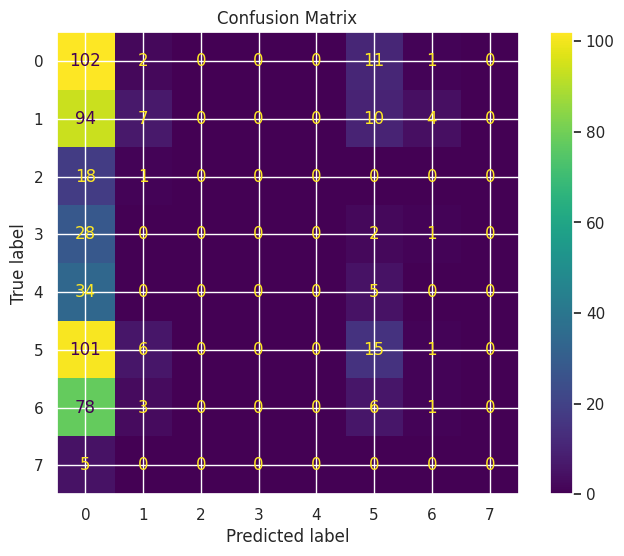

In [ ]:
main({'MLP_GRU_test': models_hybrids['MLP_GRU_tiny']}, "mlp_gru_test")

/tmp/ipykernel_5383/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)


Epoch 20/30, Loss: 1.8600


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 20/30, Loss: 1.8892
Epoch 20/30, Loss: 1.8944
Epoch 20/30, Loss: 1.8952
Epoch 20/30, Loss: 1.8922
Epoch 20/30, Loss: 1.8922

Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_GRU_test
------------------------------
TRAIN
Accuracy: 0.2674
Precision: 0.1841
Recall: 0.2674
F1: 0.1837
Kappa: 0.0648
Error Rate: 0.7326

TEST
Accuracy: 0.2071
Precision: 0.1448
Recall: 0.2071
F1: 0.0878
Kappa: -0.0016
Error Rate: 0.7929
Gap (overfitting): 0.0603

CV
Mean: 0.2711
Std: 0.0111
------------------------------
Model params:
{'cnn_filters': [8], 'cnn_kernels': [3], 'cnn_dropout': 0.3, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.3, 'fc_hidden': (4,), 'input_size': 21, 'output_size': 8, 'learning_rate': 0.0005, 'epochs': 30, 'batch_size': 16, 'random_state': 42}



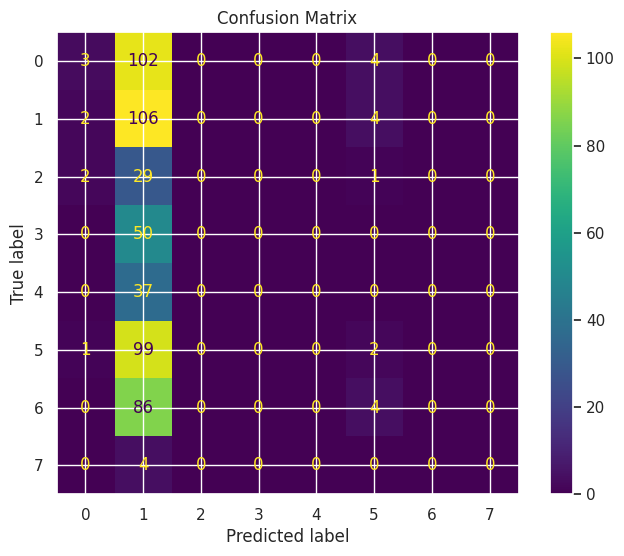

In [ ]:
main({'CNN_GRU_test': models_hybrids['CNN_GRU_tiny']}, "cnn_gru_test")


/tmp/ipykernel_5383/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)


Epoch 20/30, Loss: 1.8660


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 20/30, Loss: 1.8840
Epoch 20/30, Loss: 1.8600
Epoch 20/30, Loss: 1.8715
Epoch 20/30, Loss: 1.8853
Epoch 20/30, Loss: 1.8808

Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_GRU_test
------------------------------
TRAIN
Accuracy: 0.2170
Precision: 0.1549
Recall: 0.2170
F1: 0.0785
Kappa: 0.0010
Error Rate: 0.7830

TEST
Accuracy: 0.1772
Precision: 0.0315
Recall: 0.1772
F1: 0.0535
Kappa: -0.0002
Error Rate: 0.8228
Gap (overfitting): 0.0397

CV
Mean: 0.2409
Std: 0.0274
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.3, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.3, 'fc_hidden': (4,), 'input_size': 21, 'output_size': 8, 'learning_rate': 0.0005, 'epochs': 30, 'batch_size': 16, 'random_state': 42}



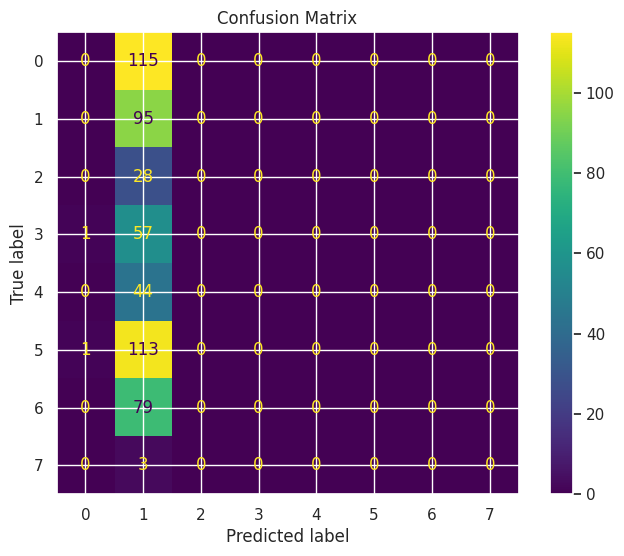

In [ ]:
main({'RNN_GRU_test': models_hybrids['RNN_GRU_tiny']}, "rnn_gru_test")

/tmp/ipykernel_5383/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)


Epoch 20/30, Loss: 1.8612


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 20/30, Loss: 1.8527
Epoch 20/30, Loss: 1.8498
Epoch 20/30, Loss: 1.8514
Epoch 20/30, Loss: 1.8580
Epoch 20/30, Loss: 1.8524

Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_LSTM_test
------------------------------
TRAIN
Accuracy: 0.3195
Precision: 0.1409
Recall: 0.3195
F1: 0.1954
Kappa: 0.1256
Error Rate: 0.6805

TEST
Accuracy: 0.2351
Precision: 0.1128
Recall: 0.2351
F1: 0.1375
Kappa: 0.0344
Error Rate: 0.7649
Gap (overfitting): 0.0844

CV
Mean: 0.3249
Std: 0.0111
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.3, 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.3, 'fc_hidden': (4,), 'input_size': 21, 'output_size': 8, 'learning_rate': 0.0005, 'epochs': 30, 'batch_size': 16, 'random_state': 42}



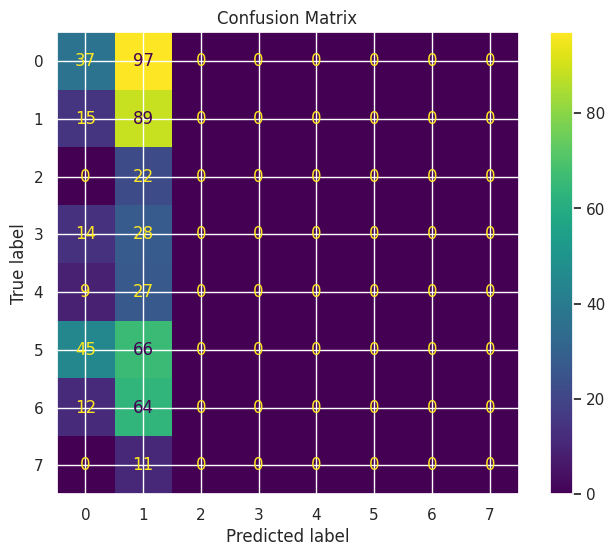

In [ ]:
main({'RNN_LSTM_test': models_hybrids['RNN_LSTM_tiny']}, "rnn_lstm_test")

verficart o codigo acima,
entender cada passo
fazs a validcao dos hiermatepros][link text](https://)**bold text** *italicized text*

In [ ]:
class TCNClassifier(BaseEstimator, ClassifierMixin):
    """Temporal Convolutional Network para classificação"""

    def __init__(self,
                 num_channels=[32, 64, 32],
                 kernel_size=3,
                 dropout=0.2,
                 dilations=[1, 2, 4],
                 fc_hidden_layers=(16,),
                 input_size=None,
                 output_size=8,
                 learning_rate=0.001,
                 epochs=100,
                 batch_size=32,
                 random_state=42,
                 device='cpu'):

        self.num_channels = num_channels
        self.kernel_size = kernel_size
        self.dropout = dropout
        self.dilations = dilations
        self.fc_hidden_layers = fc_hidden_layers
        self.input_size = input_size
        self.output_size = output_size
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.batch_size = batch_size
        self.random_state = random_state
        self.device = device if torch.cuda.is_available() else 'cpu'

        self.model = None
        self.optimizer = None
        self.criterion = None
        self.label_encoder = LabelEncoder()
        self.scaler = MinMaxScaler()

    def _build_tcn_block(self, in_channels, out_channels, kernel_size, dilation, dropout):
        return nn.Sequential(
            nn.Conv1d(
                in_channels=in_channels,
                out_channels=out_channels,
                kernel_size=kernel_size,
                padding='same',
                dilation=dilation
            ),
            nn.BatchNorm1d(out_channels),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

    def _build_model(self):
        class TCNModel(nn.Module):
            def __init__(self, input_size, num_channels, kernel_size, dilations, dropout, fc_hiddens, output_size):
                super(TCNModel, self).__init__()

                # Primeira camada para ajustar dimensão
                self.initial_conv = nn.Conv1d(1, num_channels[0], kernel_size=1)

                # Blocos TCN
                tcn_blocks = []
                prev_channels = num_channels[0]

                for i, (out_channels, dilation) in enumerate(zip(num_channels[1:], dilations)):
                    tcn_blocks.append(
                        self._make_tcn_block(prev_channels, out_channels, kernel_size, dilation, dropout)
                    )
                    prev_channels = out_channels

                self.tcn_blocks = nn.Sequential(*tcn_blocks)

                # Global Average Pooling
                self.gap = nn.AdaptiveAvgPool1d(1)

                # Fully connected
                fc_layers = []
                prev_size = num_channels[-1]

                for hidden in fc_hiddens:
                    fc_layers.append(nn.Linear(prev_size, hidden))
                    fc_layers.append(nn.ReLU())
                    fc_layers.append(nn.Dropout(dropout))
                    prev_size = hidden

                fc_layers.append(nn.Linear(prev_size, output_size))
                self.fc = nn.Sequential(*fc_layers)

            def _make_tcn_block(self, in_channels, out_channels, kernel_size, dilation, dropout):
                return nn.Sequential(
                    nn.Conv1d(in_channels, out_channels, kernel_size, padding='same', dilation=dilation),
                    nn.BatchNorm1d(out_channels),
                    nn.ReLU(),
                    nn.Dropout(dropout)
                )

            def forward(self, x):
                # x: (batch, features) -> (batch, 1, features)
                x = x.unsqueeze(1)

                # Initial conv
                x = self.initial_conv(x)

                # TCN blocks
                x = self.tcn_blocks(x)

                # Global Average Pooling
                x = self.gap(x)
                x = x.squeeze(-1)

                # Fully connected
                x = self.fc(x)
                return x

        return TCNModel(
            input_size=self.input_size,
            num_channels=self.num_channels,
            kernel_size=self.kernel_size,
            dilations=self.dilations,
            dropout=self.dropout,
            fc_hiddens=self.fc_hidden_layers,
            output_size=self.output_size
        )

    def fit(self, X, y):
        if isinstance(X, pd.DataFrame):
            X = X.values
        if isinstance(y, (pd.Series, pd.DataFrame)):
            y = y.values

        if self.input_size is None:
            self.input_size = X.shape[1]

        X_scaled = self.scaler.fit_transform(X)
        y_encoded = self.label_encoder.fit_transform(y)
        self.output_size = len(self.label_encoder.classes_)

        torch.manual_seed(self.random_state)
        self.model = self._build_model().to(self.device)

        self.optimizer = optim.Adam(self.model.parameters(), lr=self.learning_rate)
        self.criterion = nn.CrossEntropyLoss()

        X_tensor = torch.FloatTensor(X_scaled).to(self.device)
        y_tensor = torch.LongTensor(y_encoded).to(self.device)

        dataset = TensorDataset(X_tensor, y_tensor)
        dataloader = DataLoader(dataset, batch_size=self.batch_size, shuffle=True)

        self.model.train()
        for epoch in range(self.epochs):
            total_loss = 0
            for batch_X, batch_y in dataloader:
                self.optimizer.zero_grad()
                outputs = self.model(batch_X)
                loss = self.criterion(outputs, batch_y)
                loss.backward()
                self.optimizer.step()
                total_loss += loss.item()

            if (epoch + 1) % 20 == 0:
                print(f"Epoch {epoch+1}/{self.epochs}, Loss: {total_loss/len(dataloader):.4f}")

        return self

    def predict(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = self.model(X_tensor)
            _, predicted = torch.max(outputs, 1)

        return self.label_encoder.inverse_transform(predicted.cpu().numpy())

    def predict_proba(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = torch.softmax(self.model(X_tensor), dim=1)

        return outputs.cpu().numpy()

    def get_params(self, deep=True):
        return {
            'num_channels': self.num_channels,
            'kernel_size': self.kernel_size,
            'dropout': self.dropout,
            'dilations': self.dilations,
            'fc_hidden_layers': self.fc_hidden_layers,
            'input_size': self.input_size,
            'output_size': self.output_size,
            'learning_rate': self.learning_rate,
            'epochs': self.epochs,
            'batch_size': self.batch_size,
            'random_state': self.random_state
        }

    def set_params(self, **params):
        for key, value in params.items():
            setattr(self, key, value)
        return self

In [ ]:
class TCN_LSTM_Hybrid(BaseEstimator, ClassifierMixin):
    """TCN para extrair padrões temporais + LSTM para dependências de longo prazo"""

    def __init__(self,
                 tcn_channels=[16, 32],
                 tcn_kernel=3,
                 tcn_dropout=0.2,
                 tcn_dilations=[1, 2],
                 lstm_hidden=16,
                 lstm_layers=1,
                 lstm_dropout=0.2,
                 fc_hidden=(8,),
                 input_size=None,
                 output_size=8,
                 learning_rate=0.001,
                 epochs=100,
                 batch_size=32,
                 random_state=42,
                 device='cpu'):

        self.tcn_channels = tcn_channels
        self.tcn_kernel = tcn_kernel
        self.tcn_dropout = tcn_dropout
        self.tcn_dilations = tcn_dilations
        self.lstm_hidden = lstm_hidden
        self.lstm_layers = lstm_layers
        self.lstm_dropout = lstm_dropout
        self.fc_hidden = fc_hidden
        self.input_size = input_size
        self.output_size = output_size
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.batch_size = batch_size
        self.random_state = random_state
        self.device = device if torch.cuda.is_available() else 'cpu'

        self.model = None
        self.optimizer = None
        self.criterion = None
        self.label_encoder = LabelEncoder()
        self.scaler = MinMaxScaler()

    def _build_model(self):
        class TCN_LSTM_Model(nn.Module):
            def __init__(self, input_size, tcn_channels, tcn_kernel, tcn_dilations, tcn_dropout,
                         lstm_hidden, lstm_layers, lstm_dropout, fc_hidden, output_size):
                super(TCN_LSTM_Model, self).__init__()

                # TCN para extrair features temporais
                tcn_layers = []
                prev_channels = 1

                for i, (out_channels, dilation) in enumerate(zip(tcn_channels, tcn_dilations)):
                    tcn_layers.append(
                        nn.Conv1d(prev_channels, out_channels, tcn_kernel,
                                  padding='same', dilation=dilation)
                    )
                    tcn_layers.append(nn.BatchNorm1d(out_channels))
                    tcn_layers.append(nn.ReLU())
                    tcn_layers.append(nn.Dropout(tcn_dropout))
                    prev_channels = out_channels

                self.tcn = nn.Sequential(*tcn_layers)

                # LSTM
                self.lstm = nn.LSTM(
                    input_size=prev_channels,
                    hidden_size=lstm_hidden,
                    num_layers=lstm_layers,
                    batch_first=True,
                    dropout=lstm_dropout if lstm_layers > 1 else 0
                )

                self.lstm_dropout = nn.Dropout(lstm_dropout)

                # Fully connected
                fc_layers = []
                prev_size = lstm_hidden

                for hidden in fc_hidden:
                    fc_layers.append(nn.Linear(prev_size, hidden))
                    fc_layers.append(nn.ReLU())
                    fc_layers.append(nn.Dropout(tcn_dropout))
                    prev_size = hidden

                fc_layers.append(nn.Linear(prev_size, output_size))
                self.fc = nn.Sequential(*fc_layers)

            def forward(self, x):
                # x: (batch, features)
                x = x.unsqueeze(1)  # (batch, 1, features)

                # TCN
                x = self.tcn(x)  # (batch, channels, features)

                # Reshape para LSTM
                x = x.permute(0, 2, 1)  # (batch, features, channels)

                # LSTM
                lstm_out, (hidden, cell) = self.lstm(x)
                last_hidden = hidden[-1]

                x = self.lstm_dropout(last_hidden)
                x = self.fc(x)
                return x

        return TCN_LSTM_Model(
            input_size=self.input_size,
            tcn_channels=self.tcn_channels,
            tcn_kernel=self.tcn_kernel,
            tcn_dilations=self.tcn_dilations,
            tcn_dropout=self.tcn_dropout,
            lstm_hidden=self.lstm_hidden,
            lstm_layers=self.lstm_layers,
            lstm_dropout=self.lstm_dropout,
            fc_hidden=self.fc_hidden,
            output_size=self.output_size
        )

    def fit(self, X, y):
        if isinstance(X, pd.DataFrame):
            X = X.values
        if isinstance(y, (pd.Series, pd.DataFrame)):
            y = y.values

        if self.input_size is None:
            self.input_size = X.shape[1]

        X_scaled = self.scaler.fit_transform(X)
        y_encoded = self.label_encoder.fit_transform(y)
        self.output_size = len(self.label_encoder.classes_)

        torch.manual_seed(self.random_state)
        self.model = self._build_model().to(self.device)

        self.optimizer = optim.Adam(self.model.parameters(), lr=self.learning_rate)
        self.criterion = nn.CrossEntropyLoss()

        X_tensor = torch.FloatTensor(X_scaled).to(self.device)
        y_tensor = torch.LongTensor(y_encoded).to(self.device)

        dataset = TensorDataset(X_tensor, y_tensor)
        dataloader = DataLoader(dataset, batch_size=self.batch_size, shuffle=True)

        self.model.train()
        for epoch in range(self.epochs):
            total_loss = 0
            for batch_X, batch_y in dataloader:
                self.optimizer.zero_grad()
                outputs = self.model(batch_X)
                loss = self.criterion(outputs, batch_y)
                loss.backward()
                self.optimizer.step()
                total_loss += loss.item()

            if (epoch + 1) % 20 == 0:
                print(f"Epoch {epoch+1}/{self.epochs}, Loss: {total_loss/len(dataloader):.4f}")

        return self

    def predict(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = self.model(X_tensor)
            _, predicted = torch.max(outputs, 1)

        return self.label_encoder.inverse_transform(predicted.cpu().numpy())

    def predict_proba(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = torch.softmax(self.model(X_tensor), dim=1)

        return outputs.cpu().numpy()

    def get_params(self, deep=True):
        return {
            'tcn_channels': self.tcn_channels,
            'tcn_kernel': self.tcn_kernel,
            'tcn_dropout': self.tcn_dropout,
            'tcn_dilations': self.tcn_dilations,
            'lstm_hidden': self.lstm_hidden,
            'lstm_layers': self.lstm_layers,
            'lstm_dropout': self.lstm_dropout,
            'fc_hidden': self.fc_hidden,
            'input_size': self.input_size,
            'output_size': self.output_size,
            'learning_rate': self.learning_rate,
            'epochs': self.epochs,
            'batch_size': self.batch_size,
            'random_state': self.random_state
        }

    def set_params(self, **params):
        for key, value in params.items():
            setattr(self, key, value)
        return self

In [ ]:
class TCN_GRU_Hybrid(BaseEstimator, ClassifierMixin):
    """TCN para extrair padrões temporais + GRU para dependências sequenciais"""

    def __init__(self,
                 tcn_channels=[16, 32],
                 tcn_kernel=3,
                 tcn_dropout=0.2,
                 tcn_dilations=[1, 2],
                 gru_hidden=16,
                 gru_layers=1,
                 gru_dropout=0.2,
                 fc_hidden=(8,),
                 input_size=None,
                 output_size=8,
                 learning_rate=0.001,
                 epochs=100,
                 batch_size=32,
                 random_state=42,
                 device='cpu'):

        self.tcn_channels = tcn_channels
        self.tcn_kernel = tcn_kernel
        self.tcn_dropout = tcn_dropout
        self.tcn_dilations = tcn_dilations
        self.gru_hidden = gru_hidden
        self.gru_layers = gru_layers
        self.gru_dropout = gru_dropout
        self.fc_hidden = fc_hidden
        self.input_size = input_size
        self.output_size = output_size
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.batch_size = batch_size
        self.random_state = random_state
        self.device = device if torch.cuda.is_available() else 'cpu'

        self.model = None
        self.optimizer = None
        self.criterion = None
        self.label_encoder = LabelEncoder()
        self.scaler = MinMaxScaler()

    def _build_model(self):
        class TCN_GRU_Model(nn.Module):
            def __init__(self, input_size, tcn_channels, tcn_kernel, tcn_dilations, tcn_dropout,
                         gru_hidden, gru_layers, gru_dropout, fc_hidden, output_size):
                super(TCN_GRU_Model, self).__init__()

                # TCN
                tcn_layers = []
                prev_channels = 1

                for i, (out_channels, dilation) in enumerate(zip(tcn_channels, tcn_dilations)):
                    tcn_layers.append(
                        nn.Conv1d(prev_channels, out_channels, tcn_kernel,
                                  padding='same', dilation=dilation)
                    )
                    tcn_layers.append(nn.BatchNorm1d(out_channels))
                    tcn_layers.append(nn.ReLU())
                    tcn_layers.append(nn.Dropout(tcn_dropout))
                    prev_channels = out_channels

                self.tcn = nn.Sequential(*tcn_layers)

                # GRU
                self.gru = nn.GRU(
                    input_size=prev_channels,
                    hidden_size=gru_hidden,
                    num_layers=gru_layers,
                    batch_first=True,
                    dropout=gru_dropout if gru_layers > 1 else 0
                )

                self.gru_dropout = nn.Dropout(gru_dropout)

                # Fully connected
                fc_layers = []
                prev_size = gru_hidden

                for hidden in fc_hidden:
                    fc_layers.append(nn.Linear(prev_size, hidden))
                    fc_layers.append(nn.ReLU())
                    fc_layers.append(nn.Dropout(tcn_dropout))
                    prev_size = hidden

                fc_layers.append(nn.Linear(prev_size, output_size))
                self.fc = nn.Sequential(*fc_layers)

            def forward(self, x):
                x = x.unsqueeze(1)  # (batch, 1, features)
                x = self.tcn(x)  # (batch, channels, features)
                x = x.permute(0, 2, 1)  # (batch, features, channels)

                gru_out, hidden = self.gru(x)
                last_hidden = hidden[-1]

                x = self.gru_dropout(last_hidden)
                x = self.fc(x)
                return x

        return TCN_GRU_Model(
            input_size=self.input_size,
            tcn_channels=self.tcn_channels,
            tcn_kernel=self.tcn_kernel,
            tcn_dilations=self.tcn_dilations,
            tcn_dropout=self.tcn_dropout,
            gru_hidden=self.gru_hidden,
            gru_layers=self.gru_layers,
            gru_dropout=self.gru_dropout,
            fc_hidden=self.fc_hidden,
            output_size=self.output_size
        )

    # fit, predict, predict_proba (mesmo padrão)
    def fit(self, X, y):
        if isinstance(X, pd.DataFrame):
            X = X.values
        if isinstance(y, (pd.Series, pd.DataFrame)):
            y = y.values

        if self.input_size is None:
            self.input_size = X.shape[1]

        X_scaled = self.scaler.fit_transform(X)
        y_encoded = self.label_encoder.fit_transform(y)
        self.output_size = len(self.label_encoder.classes_)

        torch.manual_seed(self.random_state)
        self.model = self._build_model().to(self.device)

        self.optimizer = optim.Adam(self.model.parameters(), lr=self.learning_rate)
        self.criterion = nn.CrossEntropyLoss()

        X_tensor = torch.FloatTensor(X_scaled).to(self.device)
        y_tensor = torch.LongTensor(y_encoded).to(self.device)

        dataset = TensorDataset(X_tensor, y_tensor)
        dataloader = DataLoader(dataset, batch_size=self.batch_size, shuffle=True)

        self.model.train()
        for epoch in range(self.epochs):
            total_loss = 0
            for batch_X, batch_y in dataloader:
                self.optimizer.zero_grad()
                outputs = self.model(batch_X)
                loss = self.criterion(outputs, batch_y)
                loss.backward()
                self.optimizer.step()
                total_loss += loss.item()

            if (epoch + 1) % 20 == 0:
                print(f"Epoch {epoch+1}/{self.epochs}, Loss: {total_loss/len(dataloader):.4f}")

        return self

    def predict(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = self.model(X_tensor)
            _, predicted = torch.max(outputs, 1)

        return self.label_encoder.inverse_transform(predicted.cpu().numpy())

    def predict_proba(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = torch.softmax(self.model(X_tensor), dim=1)

        return outputs.cpu().numpy()

    def get_params(self, deep=True):
        return {
            'tcn_channels': self.tcn_channels,
            'tcn_kernel': self.tcn_kernel,
            'tcn_dropout': self.tcn_dropout,
            'tcn_dilations': self.tcn_dilations,
            'gru_hidden': self.gru_hidden,
            'gru_layers': self.gru_layers,
            'gru_dropout': self.gru_dropout,
            'fc_hidden': self.fc_hidden,
            'input_size': self.input_size,
            'output_size': self.output_size,
            'learning_rate': self.learning_rate,
            'epochs': self.epochs,
            'batch_size': self.batch_size,
            'random_state': self.random_state
        }

    def set_params(self, **params):
        for key, value in params.items():
            setattr(self, key, value)
        return self

In [ ]:
# Modelos TCN
models_tcn = {}

# TCN pura pequena
models_tcn['TCN_tiny'] = TCNClassifier(
    num_channels=[8, 16],
    kernel_size=3,
    dropout=0.3,
    dilations=[1, 2],
    fc_hidden_layers=(8,),
    learning_rate=0.0005,
    epochs=30,
    batch_size=16,
    random_state=42
)

# TCN + LSTM
models_tcn['TCN_LSTM_tiny'] = TCN_LSTM_Hybrid(
    tcn_channels=[8, 16],
    tcn_kernel=3,
    tcn_dropout=0.3,
    tcn_dilations=[1, 2],
    lstm_hidden=8,
    lstm_layers=1,
    lstm_dropout=0.3,
    fc_hidden=(4,),
    learning_rate=0.0005,
    epochs=30,
    batch_size=16,
    random_state=42
)

# TCN + GRU
models_tcn['TCN_GRU_tiny'] = TCN_GRU_Hybrid(
    tcn_channels=[8, 16],
    tcn_kernel=3,
    tcn_dropout=0.3,
    tcn_dilations=[1, 2],
    gru_hidden=8,
    gru_layers=1,
    gru_dropout=0.3,
    fc_hidden=(4,),
    learning_rate=0.0005,
    epochs=30,
    batch_size=16,
    random_state=42
)

# TCN com mais canais (cuidado com overfitting)
models_tcn['TCN_regularized'] = TCNClassifier(
    num_channels=[4, 8, 4],
    kernel_size=3,
    dropout=0.5,
    dilations=[1, 2, 4],
    fc_hidden_layers=(4,),
    learning_rate=0.0003,
    epochs=25,
    batch_size=16,
    random_state=42
)



/tmp/ipykernel_5383/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)


Epoch 20/30, Loss: 1.8056


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 20/30, Loss: 1.7704
Epoch 20/30, Loss: 1.7904
Epoch 20/30, Loss: 1.7944
Epoch 20/30, Loss: 1.7828
Epoch 20/30, Loss: 1.7897

Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_test
------------------------------
TRAIN
Accuracy: 0.2978
Precision: 0.1783
Recall: 0.2978
F1: 0.1930
Kappa: 0.1121
Error Rate: 0.7022

TEST
Accuracy: 0.0728
Precision: 0.1118
Recall: 0.0728
F1: 0.0282
Kappa: 0.0011
Error Rate: 0.9272
Gap (overfitting): 0.2251

CV
Mean: 0.3008
Std: 0.0128
------------------------------
Model params:
{'num_channels': [8, 16], 'kernel_size': 3, 'dropout': 0.3, 'dilations': [1, 2], 'fc_hidden_layers': (8,), 'input_size': 21, 'output_size': 8, 'learning_rate': 0.0005, 'epochs': 30, 'batch_size': 16, 'random_state': 42}



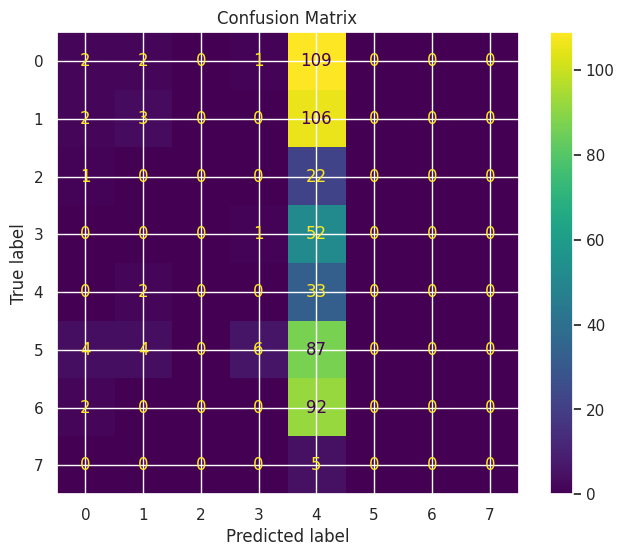

In [ ]:
# Testar
main({'TCN_test': models_tcn['TCN_tiny']}, "tcn_test")

/tmp/ipykernel_5383/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)


Epoch 20/30, Loss: 1.8888


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 20/30, Loss: 1.8619
Epoch 20/30, Loss: 1.8679
Epoch 20/30, Loss: 1.8640
Epoch 20/30, Loss: 1.8675
Epoch 20/30, Loss: 1.8705

Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_LSTM_test
------------------------------
TRAIN
Accuracy: 0.2834
Precision: 0.1373
Recall: 0.2834
F1: 0.1735
Kappa: 0.0718
Error Rate: 0.7166

TEST
Accuracy: 0.2164
Precision: 0.0468
Recall: 0.2164
F1: 0.0770
Kappa: 0.0000
Error Rate: 0.7836
Gap (overfitting): 0.0670

CV
Mean: 0.2829
Std: 0.0158
------------------------------
Model params:
{'tcn_channels': [8, 16], 'tcn_kernel': 3, 'tcn_dropout': 0.3, 'tcn_dilations': [1, 2], 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.3, 'fc_hidden': (4,), 'input_size': 21, 'output_size': 8, 'learning_rate': 0.0005, 'epochs': 30, 'batch_size': 16, 'random_state': 42}



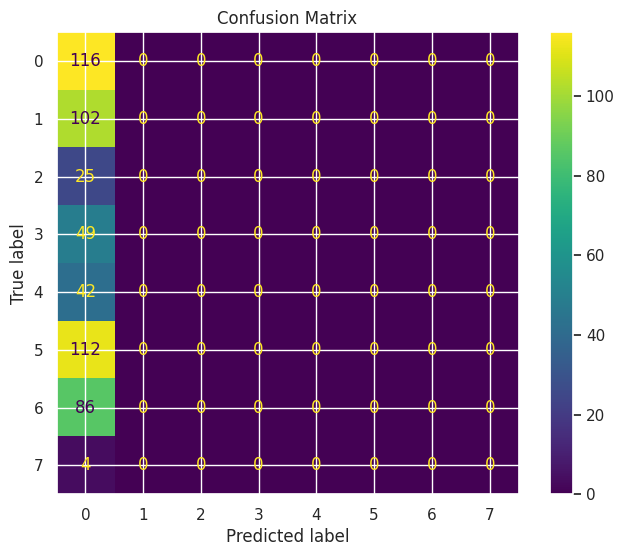

In [ ]:
main({'TCN_LSTM_test': models_tcn['TCN_LSTM_tiny']}, "tcn_lstm_test")


/tmp/ipykernel_5383/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)


Epoch 20/30, Loss: 1.8408


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 20/30, Loss: 1.8216
Epoch 20/30, Loss: 1.8403
Epoch 20/30, Loss: 1.8385
Epoch 20/30, Loss: 1.8305
Epoch 20/30, Loss: 1.8202

Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_GRU_test
------------------------------
TRAIN
Accuracy: 0.3603
Precision: 0.2537
Recall: 0.3603
F1: 0.2885
Kappa: 0.1818
Error Rate: 0.6397

TEST
Accuracy: 0.2071
Precision: 0.1194
Recall: 0.2071
F1: 0.0962
Kappa: 0.0062
Error Rate: 0.7929
Gap (overfitting): 0.1532

CV
Mean: 0.3557
Std: 0.0216
------------------------------
Model params:
{'tcn_channels': [8, 16], 'tcn_kernel': 3, 'tcn_dropout': 0.3, 'tcn_dilations': [1, 2], 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.3, 'fc_hidden': (4,), 'input_size': 21, 'output_size': 8, 'learning_rate': 0.0005, 'epochs': 30, 'batch_size': 16, 'random_state': 42}



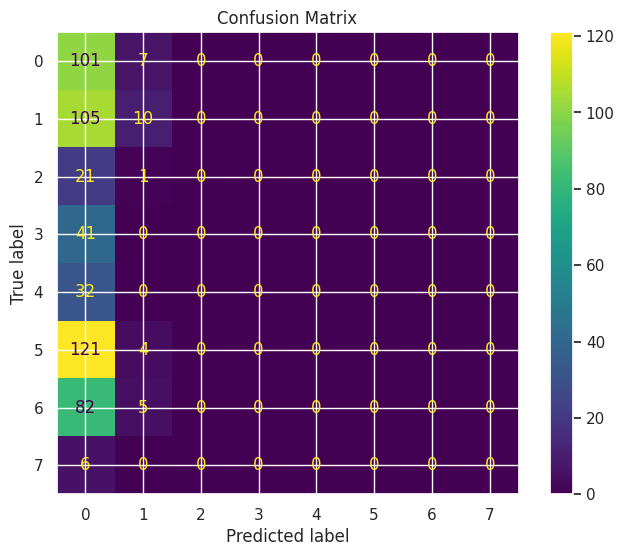

In [ ]:
main({'TCN_GRU_test': models_tcn['TCN_GRU_tiny']}, "tcn_gru_test")

VALIDACAO HIEPRMATEOS


1º vALIDAR MELHOREMODELOS DE CADA REDE
2º Organizr dadso para ficar facil ocmpra (entre proiara redfe e entre redes difetrentes
3º otimzar e organzir odigto
4º se der coeçar ml